# Replicated Held-Out Comparison of NSGA-II, Random Search and Multi-Objective Bayesian Optimisation

Two benchmarks, three search strategies, five independent repetitions each, one
default-policy baseline per benchmark, all evaluated on a single host under real
RAPL energy measurement.

## Design

| | |
| --- | --- |
| Search space | 11-dimensional decoding policy (temperature, top_p, top_k for Analyzer/Repair/Optimizer; retry budgets for Verifier and Optimizer) |
| Budget | 750 candidate evaluations per repetition, matched across arms |
| Arms | NSGA-II (seeds 42–46), random search (seeds 99–103), MOBO (seeds 123–127), default policy (5 repetitions) |
| Training | 50 problems, identical across every repetition and all three arms |
| Held-out | 100 bug records per benchmark; C is record-disjoint, with task overlap (see §0) |
| Objectives | F1 whole-program cyclomatic complexity (min), F2 test pass fraction (max), F3 execution energy of the repaired program (min) |
| Measurement | v3.1 two-phase, `rapl_sysfs`, 4 workers, one otherwise-idle host |

The searches were executed on a different machine; only the Pareto fronts —
policy vectors, which carry no timing information — were transferred. Every
held-out measurement reported here was taken on the evaluating host, so F3 is
internally comparable across all arms and repetitions.

## Arms and their replication status

| arm | method | seeds | repetitions |
| --- | --- | --- | --- |
| GA | NSGA-II (pymoo), SBX + PM | 42-46 | 5, complete |
| RS | uniform random sampling | 99-103 | 5, complete |
| MOBO | qLogNEHVI over per-objective GPs (BoTorch) | 123-127 | 5, complete |
| Baseline | the shipped default decoding policy | n/a | 5 |

**All three arms are complete at five repetitions.** The notebook asserts the
full design before analysis. For untied n = 5 versus 5, the minimum exact
two-sided Mann–Whitney p is 2/C(10,5) = 0.00794. Holm over four outcomes can
reach 0.03175; over three outcomes it can reach 0.02381. Ties invoke SciPy's
asymptotic correction, so these are not universal floors.

## Statistical scope

Two units of analysis appear throughout and are **not** interchangeable.

A **policy** is one point on one front. A **repetition** is one complete search
run. Policies within a repetition share a search trajectory, a random seed and a
training sample; they are not independent draws. Treating them as independent
inflates the effective sample size roughly forty-fold and correspondingly
deflates p-values.

The repetition is therefore the unit of replication for any claim about
*search strategies*, giving n = 5 per arm. Pooled-policy tests are descriptive diagnostics, not valid independent-policy
inference about method-generated populations. Where the two disagree, the
repetition-level result is the one that supports a claim about the methods.

## Reading order

Sections 0–1 establish that the comparison is well-posed. Sections 2–4 give the
aggregate result and the variance structure. Sections 5–7 test whether it
survives changes of indicator, estimator and reference point. Sections 8–11
examine mechanism. Section 12 states findings computed from the above; section
13 states what those findings do not license.

In [1]:
from __future__ import annotations

import json
import math
import statistics as st
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr, ttest_ind, wilcoxon

# Blanket suppression hid genuine numerical warnings (constant input to a
# correlation, invalid statistic). Suppress only the cosmetic ones.
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*tight_layout.*")

REPO = Path.cwd()
while not (REPO / "benchmarks").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
assert (REPO / "benchmarks").is_dir(), "run from inside the repository"

FIGS = REPO / "analysis" / "figs"; FIGS.mkdir(parents=True, exist_ok=True)
DATA = REPO / "analysis" / "data"; DATA.mkdir(parents=True, exist_ok=True)

# Colour follows the entity, assigned once and never reused for anything else.
C_GA, C_RS, C_MOBO, C_BASE = "#eb6834", "#8a8f98", "#1baf7a", "#2a78d6"
PALETTE = {"GA": C_GA, "RS": C_RS, "MOBO": C_MOBO, "Baseline": C_BASE}
ORDER = ["GA", "RS", "MOBO"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

def savefig(fig, name):
    fig.savefig(FIGS / f"fig_{name}.png", bbox_inches="tight")


def between(a, b):
    # Between-group test for per-repetition samples. The statistical policy is
    # non-parametric (Mann-Whitney U); Welch's t is returned alongside because
    # the two disagree materially at n = 5 and the disagreement is informative.
    #
    # The exact two-sided MWU minimum at n = 5 vs 5 is 2/C(10,5) = 0.0079 WHEN the
    # exact method applies. SciPy falls back to the normal approximation when ties
    # are present, so a tied comparison can return a value below or around that
    # figure without complete separation. Treat 0.0079 as the floor for untied
    # exact contrasts, not as a universal minimum.
    U, p_mwu = mannwhitneyu(a, b, alternative="two-sided")
    _, p_welch = ttest_ind(a, b, equal_var=False)
    return float(p_mwu), float(p_welch), float(U)


def holm_adjust(pvals):
    # Holm-Bonferroni step-down adjusted p-values; input order preserved.
    # Defined here because several sections apply the same correction.
    m = len(pvals)
    order = sorted(range(m), key=lambda i: pvals[i])
    adj = [0.0] * m
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i])
        adj[i] = min(1.0, running)
    return adj

BENCH = {
    "Codeflaws (C)": {
        "root": REPO / "outputs/ga/codeflaws/qwen2.5-coder_1.5b",
        "ga_dir": "pop50_gen15_n50_v4/rep_0", "ga_tag": "heldout_rep{i}_n100_seed0",
        "rs_dir": "rs_pop50_gen15_n50_v4/rep_0", "rs_tag": "heldout_rsrep{i}_n100_seed0",
        "mobo_dir": "mobo_pop50_gen15_n50_v4/rep_0", "mobo_tag": "heldout_moborep{i}_n100_seed0",
        "base_dir": REPO / "baselines" / "codeflaws",
        "digest": "365503a2457502e94a12ebe7c818b4cd30d335549a7682c7a14dac575b80b6f7",
        "ga_front": "results/nsga2/rep_{i}/pareto_solutions.json",
        "rs_front": "results/random_search/rep_{i}/pareto_solutions.json",
        "mobo_front": "results/mobo/rep_{i}/pareto_solutions.json",
    },
    "RunBugRun (Python)": {
        "root": REPO / "outputs/ga/runbugrun_py/qwen2.5-coder_1.5b",
        "ga_dir": "py_n50_random/rep_0", "ga_tag": "transfer_c_rep{i}_n100_seed0",
        "rs_dir": "py_n50_random/rep_0", "rs_tag": "transfer_rs_rep{i}_n100_seed0",
        "mobo_dir": "py_n50_random/rep_0", "mobo_tag": "transfer_mobo_rep{i}_n100_seed0",
        "base_dir": REPO / "baselines" / "runbugrun_py",
        "digest": "e3d0637c2d1331fbf0d9116b05fe2192352d9897d0f9d0a46b2b55ca49bb8deb",
        "ga_front": "results/nsga2/rep_{i}/pareto_solutions.json",
        "rs_front": "results/random_search/rep_{i}/pareto_solutions.json",
        "mobo_front": "results/mobo/rep_{i}/pareto_solutions.json",
    },
}
# This report describes the completed five-repetition design. Fail explicitly
# if inputs are missing or the design changes, instead of publishing partial tables.
EXPECTED_REPS = tuple(range(5))
MAX_REPS = 8

def _load(p):
    d = json.loads(Path(p).read_text())
    return d["results"] if isinstance(d, dict) and "results" in d else d

def rep_path(b, arm, i):
    cfg = BENCH[b]
    d, tag = {"GA": (cfg["ga_dir"], cfg["ga_tag"]),
              "RS": (cfg["rs_dir"], cfg["rs_tag"]),
              "MOBO": (cfg["mobo_dir"], cfg["mobo_tag"])}[arm]
    return cfg["root"] / d / tag.format(i=i) / "results.json"

# policies[bench][arm][rep] -> list of policy records; only repetitions that
# exist on disk are present.
policies = {b: {a: {i: _load(rep_path(b, a, i)) for i in range(MAX_REPS)
                    if rep_path(b, a, i).is_file()}
                for a in ORDER} for b in BENCH}

def RP(b, a):
    #  repetition indices available for this benchmark and arm
    return sorted(policies[b][a])

N_REPS = {(b, a): len(RP(b, a)) for b in BENCH for a in ORDER}
REPS = range(5)          # retained only where a fixed axis is wanted for plots
baseline = {}
for b, cfg in BENCH.items():
    bd = cfg["base_dir"]
    baseline[b] = {
        "summary": json.loads((bd / "summary.json").read_text()),
        "reps": [json.loads(p.read_text()) for p in sorted((bd / "reps").glob("*.json"))],
    }

def flat(b, a, key):
    return [x[key] for i in RP(b, a) for x in policies[b][a][i]
            if isinstance(x[key], (int, float)) and math.isfinite(x[key])]

def per_rep(b, a, key, agg=st.mean):
    return [agg([x[key] for x in policies[b][a][i]
                 if isinstance(x[key], (int, float)) and math.isfinite(x[key])]) for i in RP(b, a)]

print("loaded")
for b in BENCH:
    parts = []
    for a in ORDER:
        npol = sum(len(policies[b][a][i]) for i in RP(b, a))
        parts.append(f"{a} {npol:4d} policies / {N_REPS[(b, a)]} reps")
    print(f"  {b:22s} " + "   ".join(parts) +
          f"   baseline {baseline[b]['summary']['n_reps']} reps")
if len({N_REPS[(b, a)] for b in BENCH for a in ORDER}) > 1:
    print("\n  NOTE: repetition counts are UNEQUAL across arms, so the comparisons "
          "below\n  are unbalanced and the resolution floor differs between contrasts.")
else:
    print(f"\n  All arms balanced at {N_REPS[(list(BENCH)[0], ORDER[0])]} repetitions; "
          "every contrast shares the same\n  resolution floor.")

assert all(tuple(RP(b, a)) == EXPECTED_REPS for b in BENCH for a in ORDER), "expected reps 0–4 for every arm"
assert all(len(v["reps"]) == v["summary"]["n_reps"] == 5 for v in baseline.values())
for b, v in baseline.items():
    for key in ("mean_cl", "mean_correctness", "mean_energy", "n_feasible"):
        raw = [r[key] for r in v["reps"]]
        assert np.isclose(v["summary"][key]["mean"], st.mean(raw), rtol=1e-10)
        assert np.isclose(v["summary"][key]["std"], st.stdev(raw), rtol=1e-10)

loaded
  Codeflaws (C)          GA  222 policies / 5 reps   RS  198 policies / 5 reps   MOBO  245 policies / 5 reps   baseline 5 reps
  RunBugRun (Python)     GA  222 policies / 5 reps   RS  198 policies / 5 reps   MOBO  245 policies / 5 reps   baseline 5 reps

  All arms balanced at 5 repetitions; every contrast shares the same
  resolution floor.


## §0 · Provenance and integrity

A comparison across arms is only meaningful if the arms were measured on the
same problems with the same instrument. Both conditions are asserted here rather
than assumed. The evaluator records the SHA-256 of its held-out problem id list
in every run manifest; identical digests across arms establish that the sets are
identical element-wise, not merely equal in size.

In [2]:
rows = []
for b, cfg in BENCH.items():
    for a in ORDER:
        # Each arm has its own run directory and tag. Resolving them per arm is
        # what makes the digest, backend and worker checks below apply to the arm
        # being reported rather than to some other arm's manifest.
        d, tag = {"GA":   (cfg["ga_dir"],   cfg["ga_tag"]),
                  "RS":   (cfg["rs_dir"],   cfg["rs_tag"]),
                  "MOBO": (cfg["mobo_dir"], cfg["mobo_tag"])}[a]
        for i in RP(b, a):
            m = json.loads((cfg["root"] / d / tag.format(i=i) / "manifest.json").read_text())
            rows.append((b, a, i, m.get("heldout_ids_sha256", ""), m.get("energy_backend"),
                         m.get("energy_is_real_measurement"), m.get("n_pareto_policies"),
                         m.get("n_problem_workers")))
    bm = json.loads((cfg["base_dir"] / "manifest.json").read_text())
    rows.append((b, "Baseline", "-", bm.get("heldout_ids_sha256", ""), bm.get("energy_backend"),
                 bm.get("energy_is_real_measurement"), None, bm.get("n_problem_workers")))

ok = True
for b, cfg in BENCH.items():
    digests = {r[3] for r in rows if r[0] == b}
    backends = {r[4] for r in rows if r[0] == b}
    real = {r[5] for r in rows if r[0] == b}
    workers = {r[7] for r in rows if r[0] == b}
    same_d = digests == {cfg["digest"]}
    ok &= same_d and backends == {"rapl_sysfs"} and real == {True} and workers == {4}
    print(f"  {b}")
    print(f"    held-out digest identical across all arms : {same_d}  ({list(digests)[0][:16]}…)")
    print(f"    energy backend                            : {backends}")
    print(f"    real measurement (not a proxy)            : {real}")
    print(f"    problem workers                           : {workers}")
assert ok, "provenance check failed - the arms are not comparable"
print("\n  PASS - every arm on every benchmark shares one problem set and one instrument")

# Verify payloads, not only manifest claims, and audit the actual upstream tasks.
import hashlib

def upstream_key(q):
    pid = str(q["problem_id"])
    # Codeflaws metadata falls back to the bug-record id. The Codeforces task
    # is the contest/problem prefix, shared by sibling submissions.
    return pid.split("-bug-", 1)[0] if "-bug-" in pid else str(q.get("group_id") or pid)

def problem_records(r):
    pp = r["per_problem"]
    return pp if isinstance(pp, list) else list(pp.values())

SPLIT_AUDIT = {}
for b, cfg in BENCH.items():
    m0 = json.loads(rep_path(b, "GA", 0).with_name("manifest.json").read_text())
    expected_ids = set(m0["heldout_ids"])
    assert len(expected_ids) == 100
    for a in ORDER:
        for i in RP(b, a):
            m = json.loads(rep_path(b, a, i).with_name("manifest.json").read_text())
            assert hashlib.sha256("\n".join(m["heldout_ids"]).encode()).hexdigest() == cfg["digest"]
            assert set(m["heldout_ids"]) == expected_ids
            assert set(m["train_ids"]) == set(m0["train_ids"])
            front = _load(REPO / cfg[a.lower() + "_front"].format(i=i))
            expected = {json.dumps(r["policy"], sort_keys=True): r["fitness"] for r in front}
            actual = {json.dumps(r["policy"], sort_keys=True): r["train_fitness"] for r in policies[b][a][i]}
            assert len(front) == len(actual) == len(policies[b][a][i]) == m["n_pareto_policies"]
            assert actual == expected, (b, a, i, "policy or training-fitness mismatch")
    all_records = [r for a in ORDER for i in RP(b, a) for r in policies[b][a][i]] + baseline[b]["reps"]
    for r in all_records:
        pp = problem_records(r)
        assert len(pp) == r["n_total"] == 100
        assert {q["problem_id"] for q in pp} == expected_ids
        feasible = [q for q in pp if q.get("feasible")]
        assert len(feasible) == r["n_feasible"]
        for field, vals in (("mean_correctness", [q["correctness"] for q in pp]),
                            ("mean_cl", [q["cl"] for q in feasible]),
                            ("mean_energy", [q["runtime_mj"] for q in feasible])):
            assert np.isclose(r[field], st.mean(vals), rtol=1e-10, atol=1e-10), (b, field)
    held_groups = {upstream_key(q) for q in problem_records(all_records[0])}
    if "Codeflaws" in b:
        train_groups = {pid.split("-bug-", 1)[0] for pid in m0["train_ids"]}
        overlap = sorted(train_groups & held_groups)
        overlap_ids = sorted(pid for pid in expected_ids if pid.split("-bug-", 1)[0] in overlap)
    else:
        train_groups = set(map(str, m0["train_group_ids"]))
        overlap = sorted(train_groups & held_groups)
        overlap_ids = sorted(q["problem_id"] for q in problem_records(all_records[0]) if upstream_key(q) in overlap)
    assert not (set(m0["train_ids"]) & expected_ids)
    SPLIT_AUDIT[b] = dict(records=len(expected_ids), groups=len(held_groups),
                          excluded_training_records=len(m0["train_ids"]), training_groups=len(train_groups),
                          overlapping_groups=overlap, overlapping_record_ids=overlap_ids)
    print(f"  {b}: {len(expected_ids)} records / {len(held_groups)} tasks; "
          f"training-task overlap {len(overlap)} tasks / {len(overlap_ids)} held-out records")
print("  PASS — complete fronts, policy vectors, training fitness and per-record aggregates verified")

  Codeflaws (C)
    held-out digest identical across all arms : True  (365503a2457502e9…)
    energy backend                            : {'rapl_sysfs'}
    real measurement (not a proxy)            : {True}
    problem workers                           : {4}
  RunBugRun (Python)
    held-out digest identical across all arms : True  (e3d0637c2d1331fb…)
    energy backend                            : {'rapl_sysfs'}
    real measurement (not a proxy)            : {True}
    problem workers                           : {4}

  PASS - every arm on every benchmark shares one problem set and one instrument
  Codeflaws (C): 100 records / 98 tasks; training-task overlap 6 tasks / 7 held-out records


  RunBugRun (Python): 100 records / 68 tasks; training-task overlap 0 tasks / 0 held-out records
  PASS — complete fronts, policy vectors, training fitness and per-record aggregates verified


## §1 · Data available

Front cardinality varies because it is an outcome of search. Adding points to a
fixed set cannot reduce hypervolume, but an arbitrary larger front need not have
higher HV than a smaller one. Section 5 includes equal-cardinality subsampling
as a sensitivity analysis.

  benchmark             arm     rep 0   rep 1   rep 2   rep 3   rep 4   total
  Codeflaws (C)         GA         38      45      50      46      43     222
  Codeflaws (C)         RS         34      44      33      42      45     198
  Codeflaws (C)         MOBO       48      50      59      45      43     245
  RunBugRun (Python)    GA         38      45      50      46      43     222
  RunBugRun (Python)    RS         34      44      33      42      45     198
  RunBugRun (Python)    MOBO       48      50      59      45      43     245


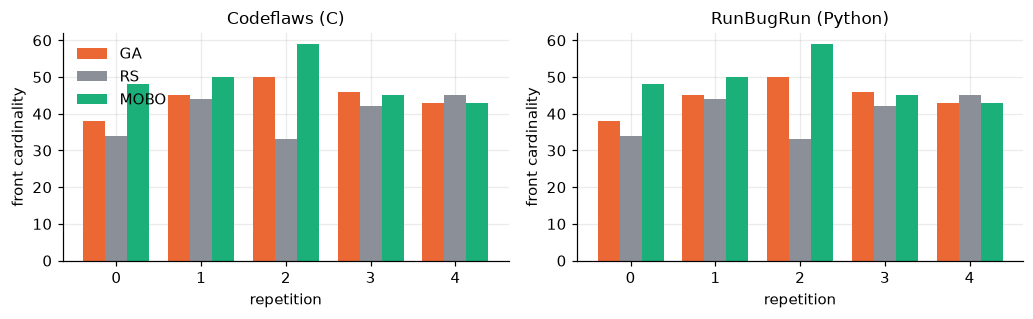

In [3]:
print(f"  {'benchmark':22s}{'arm':5s}" + "".join(f"{'rep '+str(i):>8s}" for i in RP(b, a)) + f"{'total':>8s}")
inv = {}
for b in BENCH:
    for a in ORDER:
        ns = [len(policies[b][a][i]) for i in RP(b, a)]
        inv[(b, a)] = ns
        print(f"  {b:22s}{a:5s}" + "".join(f"{n:8d}" for n in ns) + f"{sum(ns):8d}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.0))
for ax, b in zip(axes, BENCH):
    w = 0.26
    for k, a in enumerate(ORDER):
        ax.bar([i + (k - (len(ORDER) - 1) / 2) * w for i in RP(b, a)], inv[(b, a)], w,
               color=PALETTE[a], label=a)
    ax.set_title(b); ax.set_xlabel("repetition"); ax.set_xticks(list(REPS))
    ax.set_ylabel("front cardinality")
axes[0].legend()
fig.tight_layout(); savefig(fig, "front_cardinality"); plt.show()

## §2 · Held-out aggregates

The repeated default is the reference for improvement over untuned decoding.
Arm-versus-arm comparisons assess directed search against uniform sampling at
the same evaluation budget. Neither alone establishes that search repays its
cost. Baseline SD is a descriptive scale of default-policy execution variation;
a difference smaller than one SD can still be estimable and should be assessed
with uncertainty, not dismissed by that threshold.


  Codeflaws (C)
                  n       mean     median       best        sd    vs base  in base sd
    F2 corr             0.4580                          0.0243   (baseline, 5 reps)
      GA        222     0.4511     0.4641     0.5628    0.0624    -0.0070       -0.29
      RS        198     0.4798     0.4960     0.5555    0.0538    +0.0218       +0.90
      MOBO      245     0.4601     0.4953     0.5669    0.0850    +0.0021       +0.09
    F1 cplx             9.2595                          0.2821   (baseline, 5 reps)
      GA        222     8.9144     9.0156     7.2174    0.5431    +0.3451       +1.22
      RS        198     9.0411     9.1212     7.4375    0.4475    +0.2184       +0.77
      MOBO      245     8.9041     9.0541     7.0750    0.6273    +0.3554       +1.26
    F3 mJ              35.5597                          5.9377   (baseline, 5 reps)
      GA        222    39.4649    32.2018    10.7500   55.8423    -3.9052       -0.66
      RS        198    33.0524    32.6775  

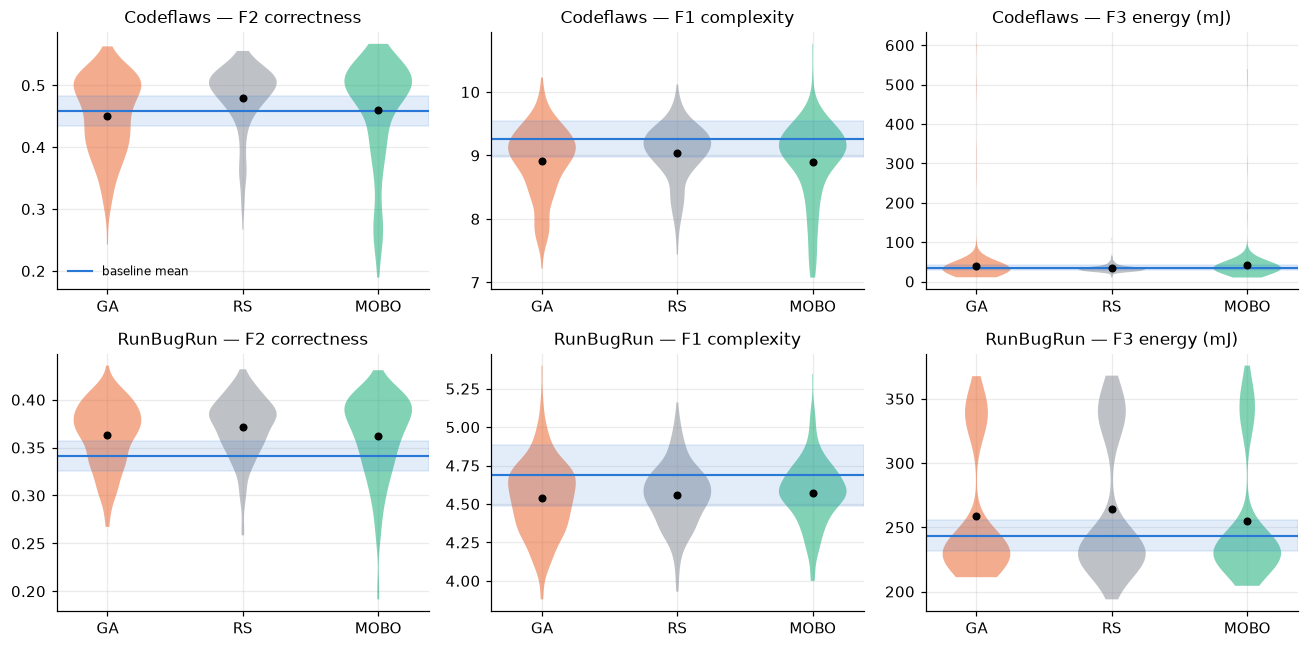

In [4]:
def summarise(b, a, key, better):
    v = flat(b, a, key)
    return len(v), st.mean(v), st.median(v), (max(v) if better == "hi" else min(v)), st.stdev(v)

table = {}
for b in BENCH:
    bs = baseline[b]["summary"]
    print(f"\n  {b}")
    print(f"    {'':10s}{'n':>5s}{'mean':>11s}{'median':>11s}{'best':>11s}{'sd':>10s}{'vs base':>11s}{'in base sd':>12s}")
    for key, lab, better, bkey in (("mean_correctness", "F2 corr", "hi", "mean_correctness"),
                                   ("mean_cl", "F1 cplx", "lo", "mean_cl"),
                                   ("mean_energy", "F3 mJ", "lo", "mean_energy")):
        bm, bsd = bs[bkey]["mean"], bs[bkey]["std"]
        print(f"    {lab:10s}{'':5s}{bm:11.4f}{'':11s}{'':11s}{bsd:10.4f}   (baseline, {bs['n_reps']} reps)")
        for a in ORDER:
            n, mu, med, best, sd = summarise(b, a, key, better)
            gain = (mu - bm) if better == "hi" else (bm - mu)
            table[(b, a, key)] = dict(n=n, mean=mu, median=med, best=best, sd=sd,
                                      gain=gain, gain_sd=gain / bsd)
            print(f"    {'  '+a:10s}{n:5d}{mu:11.4f}{med:11.4f}{best:11.4f}{sd:10.4f}"
                  f"{gain:+11.4f}{gain/bsd:+12.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for r, b in enumerate(BENCH):
    bs = baseline[b]["summary"]
    for c, (key, lab, bkey) in enumerate((("mean_correctness", "F2 correctness", "mean_correctness"),
                                          ("mean_cl", "F1 complexity", "mean_cl"),
                                          ("mean_energy", "F3 energy (mJ)", "mean_energy"))):
        ax = axes[r, c]
        parts = ax.violinplot([flat(b, a, key) for a in ORDER], showextrema=False)
        for pc, a in zip(parts["bodies"], ORDER):
            pc.set_facecolor(PALETTE[a]); pc.set_alpha(0.55)
        for k, a in enumerate(ORDER, start=1):
            v = flat(b, a, key)
            ax.scatter([k], [st.mean(v)], color="black", zorder=3, s=18)
        bm, bsd = bs[bkey]["mean"], bs[bkey]["std"]
        ax.axhline(bm, color=C_BASE, lw=1.4, label="baseline mean")
        ax.axhspan(bm - bsd, bm + bsd, color=C_BASE, alpha=0.13)
        ax.set_xticks(range(1, len(ORDER) + 1)); ax.set_xticklabels(ORDER)
        ax.set_title(f"{b.split(' ')[0]} — {lab}")
        if r == 0 and c == 0: ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "heldout_distributions"); plt.show()

#### Interpretation

The shaded band marks one baseline standard deviation. Each front-mean coordinate
averages that objective over **all** retained policies; it is not taken from a
single policy. The coordinate-wise median is also a marginal summary. Neither
summary is guaranteed to correspond to an available policy, or to be dominated
by one. A claim about a deployable policy needs an explicit selection rule.

Energy is right-skewed on C, so mean and median can disagree in direction against
the baseline. Report both with the estimator stated. The per-objective shares in
§2a concern actual policies, but different subsets may win each objective;
separate marginal shares do not establish simultaneous improvement.

## §2a · Proportion of the front exceeding the default policy

For each objective, what fraction of retained policies strictly beats the
repeated-default mean? Each counted policy was evaluated, but different policies
can beat different objectives. These marginal shares do not establish joint
improvement or repeatability for a chosen policy. the three-arm comparison report also computes the
share improving all three objectives simultaneously.

Feasibility counts records with any passing test. It was a constraint, not a
separate objective, but is mechanically linked to the optimised F2. It is not
an independent, unselected confirmation of improvement.

In [5]:
OUT2 = [("F1", "mean_cl", "lo"), ("F2", "mean_correctness", "hi"),
        ("F3", "mean_energy", "lo"), ("feasibility", "n_feasible", "hi")]

share_tbl = {}
for b in BENCH:
    bs = baseline[b]["summary"]
    bmean = {"F1": bs["mean_cl"]["mean"], "F2": bs["mean_correctness"]["mean"],
             "F3": bs["mean_energy"]["mean"], "feasibility": bs["n_feasible"]["mean"]}
    print(f"\n  {b}")
    print(f"    {'objective':13s}{'baseline':>10s}{'arm':>6s}{'n':>6s}"
          f"{'% beating default':>19s}{'front mean':>12s}{'front median':>14s}{'skew':>8s}")
    for o, key, better in OUT2:
        for a in ORDER:
            v = np.array([x[key] for i in RP(b, a) for x in policies[b][a][i]
                          if isinstance(x[key], (int, float)) and math.isfinite(x[key])], float)
            bm = bmean[o]
            share = 100 * ((v > bm).mean() if better == "hi" else (v < bm).mean())
            sk = float(((v - v.mean()) ** 3).mean() / (v.std() ** 3 + 1e-12))
            share_tbl[(b, o, a)] = share
            print(f"    {o if a == ORDER[0] else '':13s}{bm if a == ORDER[0] else float('nan'):10.4f}"
                  f"{a:>6s}{len(v):6d}{share:18.0f}%{v.mean():12.4f}{np.median(v):14.4f}{sk:8.2f}")
    print(f"    (a mean and median that disagree in direction against the baseline indicate "
          f"skew, not an effect)")


  Codeflaws (C)
    objective      baseline   arm     n  % beating default  front mean  front median    skew
    F1               9.2595    GA   222                74%      8.9144        9.0156   -0.66
                        nan    RS   198                67%      9.0411        9.1212   -0.91
                        nan  MOBO   245                71%      8.9041        9.0541   -1.01
    F2               0.4580    GA   222                52%      0.4511        0.4641   -0.61
                        nan    RS   198                80%      0.4798        0.4960   -1.67
                        nan  MOBO   245                68%      0.4601        0.4953   -1.40
    F3              35.5597    GA   222                73%     39.4649       32.2018    8.03
                        nan    RS   198                77%     33.0524       32.6775    3.53
                        nan  MOBO   245                64%     40.9037       33.1434    8.69
    feasibility     68.8000    GA   222              

### §2a-i · Whole front against the baseline, under both estimators

Formal tests compare five per-repetition front means or coordinate-wise medians
against five baseline repeats. A marginal summary need not be a real policy.
The two estimators expose sensitivity to skew and to the chosen estimand.
Nominal p-values and Holm adjustment over four outcomes within each
benchmark-arm cell are both shown; state the family with every claim.

In [6]:
def whole_front_test(agg):
    rows = []
    for b in BENCH:
        braw = {"F1": [r["mean_cl"] for r in baseline[b]["reps"]],
                "F2": [r["mean_correctness"] for r in baseline[b]["reps"]],
                "F3": [r["mean_energy"] for r in baseline[b]["reps"]],
                "feasibility": [float(r["n_feasible"]) for r in baseline[b]["reps"]]}
        for a in ORDER:
            ps, cells = [], []
            for o, key, better in OUT2:
                per = [agg([x[key] for x in policies[b][a][i]
                            if isinstance(x[key], (int, float)) and math.isfinite(x[key])])
                       for i in RP(b, a)]
                bm, bsd = st.mean(braw[o]), st.stdev(braw[o])
                marg = (bm - st.mean(per)) if better == "lo" else (st.mean(per) - bm)
                pv, pv_w, _ = between(per, braw[o])
                ps.append(pv)
                cells.append([b, a, o, bm, st.mean(per), marg, 100 * marg / bm, marg / bsd, pv])
            for c, pa in zip(cells, holm_adjust(ps)):
                rows.append(c + [pa])
    return rows

for agg_name, agg in (("MEAN", st.mean), ("MEDIAN", st.median)):
    print(f"\n  front aggregate = {agg_name}")
    print(f"    {'benchmark':22s}{'arm':5s}{'objective':13s}{'baseline':>10s}{'front':>11s}"
          f"{'margin':>10s}{'%':>8s}{'base sd':>9s}{'p nom':>9s}{'p Holm':>9s}  verdict")
    n_nom = n_holm = n_cells = 0
    for b, a, o, bm, mu, marg, pct, z, pv, pa in whole_front_test(agg):
        n_nom += pv < 0.05; n_holm += pa < 0.05; n_cells += 1
        v = ("SIGNIFICANT" if pa < 0.05 else
             "(nominal only)" if pv < 0.05 else
             "beats, ns" if marg > 0 else "WORSE, ns")
        print(f"    {b:22s}{a:5s}{o:13s}{bm:10.4f}{mu:11.4f}{marg:+10.4f}{pct:+7.1f}%"
              f"{z:+9.2f}{pv:9.3g}{pa:9.3g}  {v}")
    print(f"    -> significant at nominal 0.05: {n_nom}/{n_cells}"
          f"    after Holm: {n_holm}/{n_cells}")


  front aggregate = MEAN
    benchmark             arm  objective      baseline      front    margin       %  base sd    p nom   p Holm  verdict
    Codeflaws (C)         GA   F1               9.2595     8.9221   +0.3374   +3.6%    +1.20   0.0159   0.0635  (nominal only)
    Codeflaws (C)         GA   F2               0.4580     0.4522   -0.0058   -1.3%    -0.24    0.841        1  WORSE, ns
    Codeflaws (C)         GA   F3              35.5597    39.2187   -3.6591  -10.3%    -0.62     0.31    0.929  WORSE, ns
    Codeflaws (C)         GA   feasibility     68.8000    68.0354   -0.7646   -1.1%    -0.17     0.69        1  WORSE, ns
    Codeflaws (C)         RS   F1               9.2595     9.0430   +0.2165   +2.3%    +0.77   0.0556    0.222  beats, ns
    Codeflaws (C)         RS   F2               0.4580     0.4797   +0.0217   +4.7%    +0.89   0.0952    0.286  beats, ns
    Codeflaws (C)         RS   F3              35.5597    33.1261   +2.4336   +6.8%    +0.41    0.841    0.841  beats

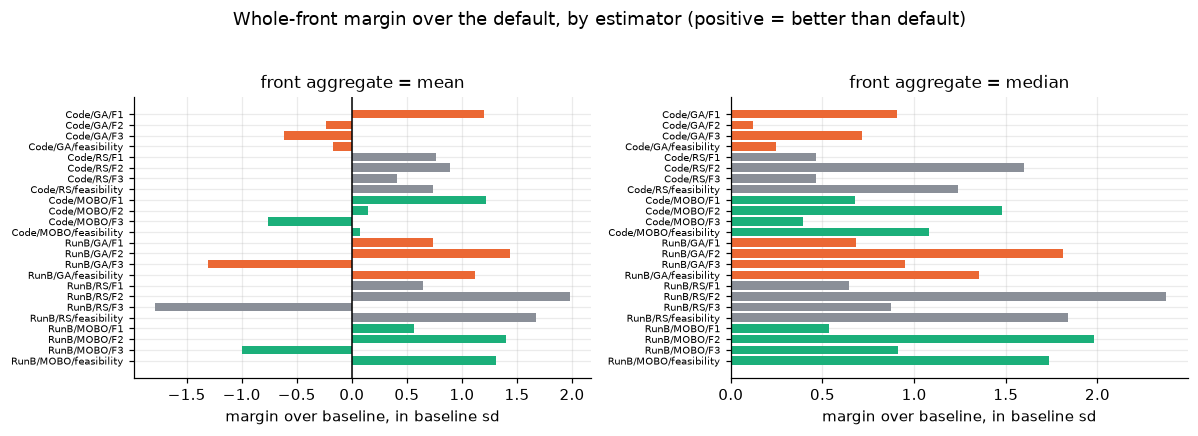

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (agg_name, agg) in zip(axes, (("mean", st.mean), ("median", st.median))):
    rows = whole_front_test(agg)
    labels = [f"{r[0].split(' ')[0][:4]}/{r[1]}/{r[2]}" for r in rows]
    z = [r[7] for r in rows]
    cols = [PALETTE[r[1]] for r in rows]
    y = np.arange(len(rows))
    ax.barh(y, z, color=cols)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=6.5)
    ax.invert_yaxis()
    ax.set_xlabel("margin over baseline, in baseline sd")
    ax.set_title(f"front aggregate = {agg_name}")
fig.suptitle("Whole-front margin over the default, by estimator "
             "(positive = better than default)", y=1.03)
fig.tight_layout(); savefig(fig, "whole_front_estimator"); plt.show()

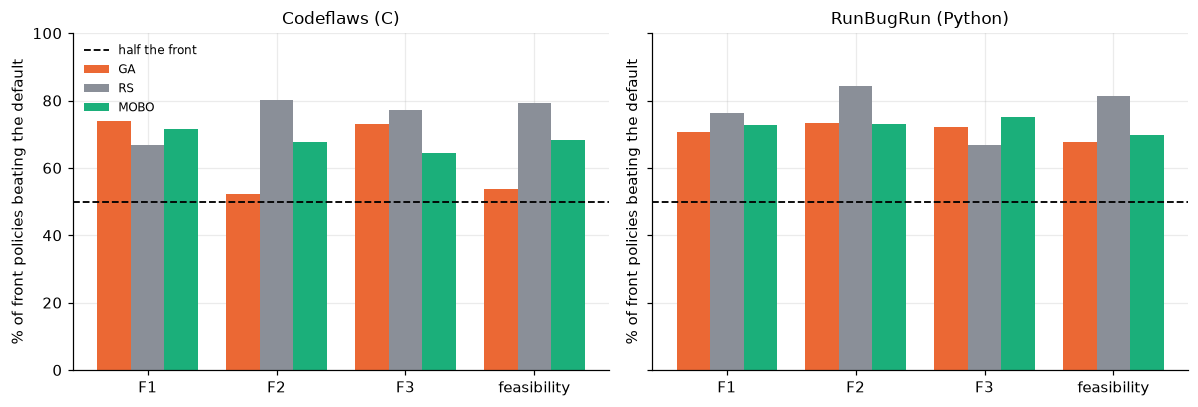

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels = [o for o, _, _ in OUT2]
for ax, b in zip(axes, BENCH):
    x = np.arange(len(labels)); w = 0.26
    for k, a in enumerate(ORDER):
        ax.bar(x + (k - (len(ORDER) - 1) / 2) * w, [share_tbl[(b, o, a)] for o in labels], w,
               color=PALETTE[a], label=a)
    ax.axhline(50, color="black", lw=1.2, ls="--", label="half the front" if b == list(BENCH)[0] else None)
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_ylim(0, 100); ax.set_ylabel("% of front policies beating the default")
    ax.set_title(b)
axes[0].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "share_beating_default"); plt.show()

## §3 · The unit of replication

A front's policies share a search trajectory and are dependent. Pooled-policy
tests below are diagnostics of the observed distributions and do not supply
valid independent-policy inference about method-generated populations. The
repetition-level test supplies the primary method comparison, with n=5 per arm.
The ratio of the two p-values illustrates sensitivity to pseudoreplication; it
is not a general estimate of sample-size inflation or a correction factor.

In [9]:
def cliffs_delta(a, b):
    a, b = list(a), list(b)
    gt = sum(1 for x in a for y in b if x > y)
    lt = sum(1 for x in a for y in b if x < y)
    return (gt - lt) / (len(a) * len(b))

def dmag(d):
    ad = abs(d)
    return "negligible" if ad < 0.147 else "small" if ad < 0.33 else "medium" if ad < 0.474 else "large"

repl = {}
for b in BENCH:
    print(f"\n  {b}")
    for key, lab, better in (("mean_correctness", "F2 correctness", "hi"),
                             ("mean_cl", "F1 complexity", "lo"),
                             ("mean_energy", "F3 energy", "lo")):
        for x, y in combinations(ORDER, 2):
            xp, yp = flat(b, x, key), flat(b, y, key)
            xr, yr = per_rep(b, x, key), per_rep(b, y, key)
            _, p_pol = mannwhitneyu(xp, yp)
            p_rep, p_rep_welch, U_rep = between(xr, yr)
            # Effect size must share the unit of the test it accompanies. The
            # headline p is per-repetition, so delta is per-repetition too; the
            # pooled-policy value is kept alongside because it is what a
            # policy-level reading would report, and the two differ sharply.
            d = cliffs_delta(yr, xr)
            d_pooled = cliffs_delta(yp, xp)
            diff = st.mean(yr) - st.mean(xr)
            repl[(b, key, x, y)] = dict(p_pol=p_pol, p_rep=p_rep, delta=d,
                                        delta_pooled=d_pooled, diff=diff, p_welch=p_rep_welch, U=U_rep)
            if (x, y) == ("GA", "RS"):
                # Two-key alias for the GA-vs-RS pair specifically. Used by the
                # p-inflation figure below and by summary_out; NOT a general
                # "the" contrast for the key -- §13 iterates the pairs itself.
                repl[(b, key)] = repl[(b, key, x, y)]
            print(f"    {lab:16s} {y}-{x:<5s} {diff:+8.4f}   per-policy p={p_pol:<10.3g} "
                  f"(n={len(xp)}+{len(yp)})   per-rep MWU p={p_rep:<8.3g} "
                  f"[Welch {p_rep_welch:.3g}] (n={len(xr)}+{len(yr)})   "
                  f"Cliff d(per-rep)={d:+.3f} ({dmag(d)}) "
                  f"[pooled {d_pooled:+.3f}]")

print("\n  inflation factor from pseudo-replication (per-rep p / per-policy p)")
for k, r in repl.items():
    if len(k) != 4:              # skip the two-key back-compat aliases
        continue
    b, key, x, y = k
    if r["p_pol"] > 0:
        print(f"    {b.split(' ')[0]:12s} {key:18s} {x}v{y:<5s} "
              f"{r['p_rep'] / r['p_pol']:12.0f}x")

# Three objective comparisons form one family within each benchmark/arm pair.
for b in BENCH:
    for x, y in combinations(ORDER, 2):
        keys = ["mean_correctness", "mean_cl", "mean_energy"]
        for key, pa in zip(keys, holm_adjust([repl[(b, k, x, y)]["p_rep"] for k in keys])):
            repl[(b, key, x, y)]["p_holm"] = pa
            print(f"  {b} {y}-{x} {key}: Holm(3) p={pa:.4g}")


  Codeflaws (C)
    F2 correctness   RS-GA     +0.0275   per-policy p=3.47e-07   (n=222+198)   per-rep MWU p=0.00794  [Welch 0.0553] (n=5+5)   Cliff d(per-rep)=+1.000 (large) [pooled +0.288]
    F2 correctness   MOBO-GA     +0.0093   per-policy p=0.000747   (n=222+245)   per-rep MWU p=0.421    [Welch 0.537] (n=5+5)   Cliff d(per-rep)=+0.360 (medium) [pooled +0.181]
    F2 correctness   MOBO-RS     -0.0182   per-policy p=0.316      (n=198+245)   per-rep MWU p=0.222    [Welch 0.142] (n=5+5)   Cliff d(per-rep)=-0.520 (large) [pooled -0.055]
    F1 complexity    RS-GA     +0.1210   per-policy p=0.0167     (n=222+198)   per-rep MWU p=0.151    [Welch 0.128] (n=5+5)   Cliff d(per-rep)=+0.600 (large) [pooled +0.135]
    F1 complexity    MOBO-GA     -0.0061   per-policy p=0.573      (n=222+245)   per-rep MWU p=1        [Welch 0.948] (n=5+5)   Cliff d(per-rep)=-0.040 (negligible) [pooled +0.030]
    F1 complexity    MOBO-RS     -0.1270   per-policy p=0.0786     (n=198+245)   per-rep MWU p=0.151

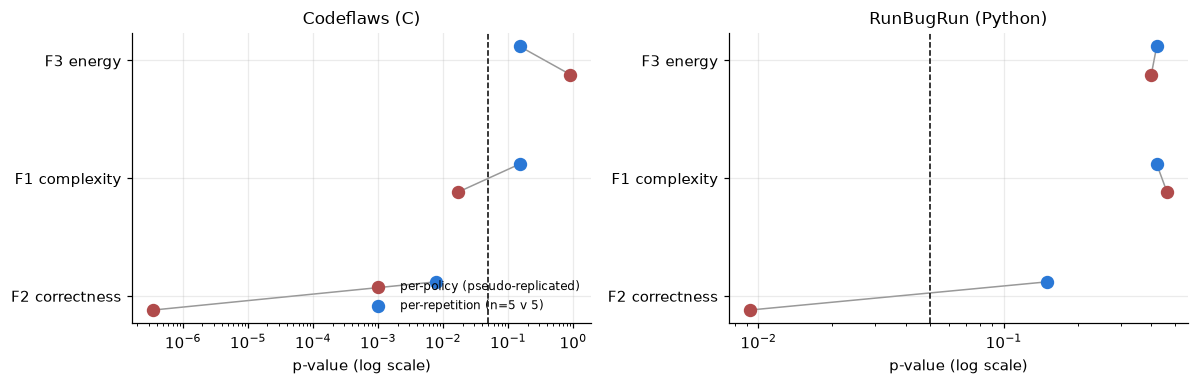

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
labs = ["F2 correctness", "F1 complexity", "F3 energy"]
keys = ["mean_correctness", "mean_cl", "mean_energy"]
for ax, b in zip(axes, BENCH):
    y = np.arange(len(keys))
    ax.scatter([repl[(b, k)]["p_pol"] for k in keys], y - 0.12,
               s=60, color="#b04b4b", label="per-policy (pseudo-replicated)")
    ax.scatter([repl[(b, k)]["p_rep"] for k in keys], y + 0.12,
               s=60, color="#2a78d6", label="per-repetition (n=5 v 5)")
    for yy, k in zip(y, keys):
        ax.plot([repl[(b, k)]["p_pol"], repl[(b, k)]["p_rep"]], [yy - 0.12, yy + 0.12],
                color="#999", lw=1, zorder=0)
    ax.axvline(0.05, color="black", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yticks(y); ax.set_yticklabels(labs)
    ax.set_xlabel("p-value (log scale)"); ax.set_title(b)
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout(); savefig(fig, "replication_unit_pvalues"); plt.show()

#### Interpretation

The primary Cliff's δ compares **per-repetition front means**, using the same
unit as the primary Mann–Whitney test. It is P(Y > X) − P(Y < X), with the
reported direction Y − X; a positive value favours Y only for maximised outcomes.
Pooled-policy δ is shown separately as a descriptive distribution comparison.
Policies within a search repetition are dependent, so pooled-policy p-values do
not support independent evidence about search strategies.

## §4 · Between-run variance

Replication was undertaken to estimate this quantity, which no single-run study
can. It is reported before any ranking claim because it sets the resolution at
which arms can be distinguished at all.

  benchmark             objective       arm        mean       sd      CV             range
  Codeflaws (C)         F2 correctness  GA       0.4522   0.0231    5.1%   0.4252-0.4734
  Codeflaws (C)         F2 correctness  RS       0.4797   0.0041    0.9%   0.4753-0.4857
  Codeflaws (C)         F2 correctness  MOBO     0.4615   0.0223    4.8%   0.4328-0.4847
                                        base     0.4580   0.0243    5.3%
  Codeflaws (C)         F1 complexity   GA       8.9221   0.1410    1.6%   8.7316-9.0527
  Codeflaws (C)         F1 complexity   RS       9.0430   0.0230    0.3%   9.0083-9.0676
  Codeflaws (C)         F1 complexity   MOBO     8.9160   0.1448    1.6%   8.7297-9.1019
                                        base     9.2595   0.2821    3.0%
  Codeflaws (C)         F3 energy       GA      39.2187   5.6786   14.5%  30.2053-44.3813
  Codeflaws (C)         F3 energy       RS      33.1261   2.1650    6.5%  31.5254-36.6885
  Codeflaws (C)         F3 energy       MOBO    4

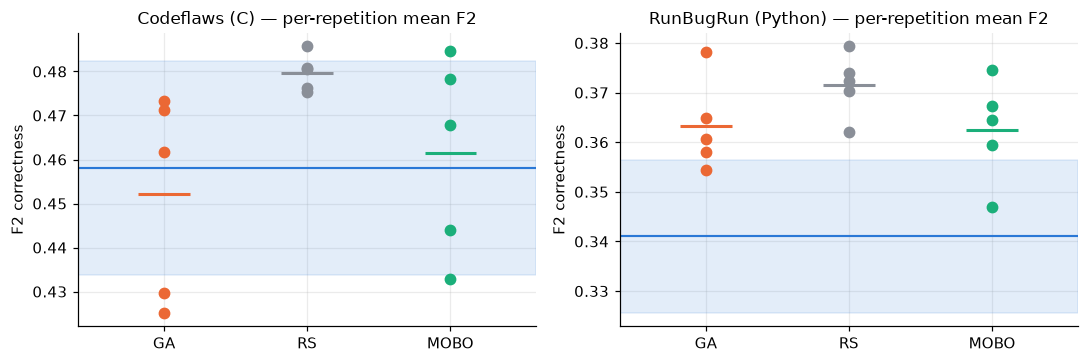

In [11]:
print(f"  {'benchmark':22s}{'objective':16s}{'arm':5s}{'mean':>10s}{'sd':>9s}{'CV':>8s}{'range':>18s}")
var_rows = {}
for b in BENCH:
    for key, lab in (("mean_correctness", "F2 correctness"), ("mean_cl", "F1 complexity"),
                     ("mean_energy", "F3 energy")):
        for a in ORDER:
            v = per_rep(b, a, key)
            cv = 100 * st.stdev(v) / st.mean(v)
            var_rows[(b, key, a)] = (st.mean(v), st.stdev(v), cv)
            print(f"  {b:22s}{lab:16s}{a:5s}{st.mean(v):10.4f}{st.stdev(v):9.4f}{cv:7.1f}%"
                  f"{min(v):9.4f}-{max(v):.4f}")
        bs = baseline[b]["summary"][key if key != "mean_energy" else "mean_energy"]
        print(f"  {'':22s}{'':16s}{'base':5s}{bs['mean']:10.4f}{bs['std']:9.4f}"
              f"{100*bs['std']/bs['mean']:7.1f}%")

print("\n  ratio of between-run standard deviations, every arm pair")
print(f"    {'benchmark':12s}{'obj':4s}" + "".join(f"{y+'/'+x:>12s}" for x, y in combinations(ORDER, 2)))
for b in BENCH:
    for key, lab in (("mean_correctness", "F2"), ("mean_cl", "F1"), ("mean_energy", "F3")):
        row = ""
        for x, y in combinations(ORDER, 2):
            sx = var_rows[(b, key, x)][1]; sy = var_rows[(b, key, y)][1]
            row += f"{(sy/sx if sx else float('nan')):11.2f}x"
        print(f"    {b.split(' ')[0]:12s}{lab:4s}{row}")
print("    (>1 means the second-named arm varies more between runs)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, b in zip(axes, BENCH):
    for k, a in enumerate(ORDER):
        v = per_rep(b, a, "mean_correctness")
        ax.scatter([k] * len(v), v, color=PALETTE[a], s=45, zorder=3, label=a)
        ax.hlines(st.mean(v), k - 0.18, k + 0.18, color=PALETTE[a], lw=2)
    bs = baseline[b]["summary"]["mean_correctness"]
    ax.axhline(bs["mean"], color=C_BASE, lw=1.4)
    ax.axhspan(bs["mean"] - bs["std"], bs["mean"] + bs["std"], color=C_BASE, alpha=0.13)
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER)
    ax.set_xlim(-0.6, len(ORDER) - 0.4)
    ax.set_title(f"{b} — per-repetition mean F2"); ax.set_ylabel("F2 correctness")
fig.tight_layout(); savefig(fig, "between_run_variance"); plt.show()

#### Interpretation

Random search does not adapt its candidate proposals to observed fitness;
NSGA-II and MOBO do. Adaptive selection could propagate measurement noise, but
the observed between-run SD combines seed variation, search behaviour and
measurement variation. Its ratio is **not** an identified noise-amplification
factor. Establishing that mechanism requires controlled repeated measurements.

## §5 · Set-level quality indicators

Sections 2–4 compare arms through the marginal distribution of each objective.
That discards the multi-objective structure: a front is a set, and set quality
is not the mean of its members. This section applies the standard indicators —
hypervolume, IGD+ and additive ε — on a shared normalisation, with the two
sensitivity analyses those indicators require.

All three objectives are mapped to minimisation and normalised to the unit cube
using the ideal and nadir points of the union of all fronts on that benchmark,
so indicator values are comparable within a benchmark and meaningless across.

**Range of the hypervolume.** The *objectives* occupy the unit cube, but the
reference point sits at `margin x (1,1,1)`, so the dominated region is bounded by
that point and the indicator ranges over `[0, margin^3]` — at the main margin of
1.10 that is `[0, 1.331]`, not `[0, 1]`. A front approaching the union ideal
approaches 1.331. Values above 1.0 are therefore expected for a strong front and
are not a normalisation error.

In [12]:
def obj_matrix(recs):
    return np.array([[r["mean_cl"], -r["mean_correctness"], r["mean_energy"]] for r in recs
                     if all(isinstance(r[k], (int, float)) and math.isfinite(r[k])
                            for k in ("mean_cl", "mean_correctness", "mean_energy"))], float)

def nondominated(F):
    keep = []
    for i in range(len(F)):
        if not any(np.all(F[j] <= F[i]) and np.any(F[j] < F[i])
                   for j in range(len(F)) if j != i):
            keep.append(i)
    return F[keep]

# Preserve the original 200,000-draw estimator and seed. Cache packed point
# domination masks: dominated points do not alter the union, so no Pareto sort
# is needed inside HV. This is algebraically identical to the previous loop.
from functools import lru_cache
HV_SAMPLES, HV_SEED = 200_000, 20260825

@lru_cache(maxsize=8)
def _hv_samples(ref):
    return np.random.default_rng(HV_SEED).random((HV_SAMPLES, len(ref))) * np.array(ref)

@lru_cache(maxsize=8192)
def _hv_mask(point, ref):
    return np.packbits(np.all(_hv_samples(ref) >= np.array(point), axis=1))

def hv(F, ref):
    ref = tuple(float(v) for v in ref)
    dom = np.zeros((HV_SAMPLES + 7) // 8, dtype=np.uint8)
    for point in F:
        dom |= _hv_mask(tuple(float(v) for v in point), ref)
    return float(np.unpackbits(dom, count=HV_SAMPLES).mean() * np.prod(ref))

def igd_plus(F, ref_set):
    d = []
    for z in ref_set:
        d.append(min(np.sqrt(np.sum(np.maximum(f - z, 0) ** 2)) for f in F))
    return float(np.mean(d))

def eps_plus(F, ref_set):
    return float(max(min(max(f - z) for f in F) for z in ref_set))

norm, sets = {}, {}
for b in BENCH:
    allF = np.vstack([obj_matrix(policies[b][a][i]) for a in ORDER for i in RP(b, a)])
    ideal, nadir = allF.min(0), allF.max(0)
    span = np.where(nadir - ideal == 0, 1.0, nadir - ideal)
    norm[b] = (ideal, span)
    for a in ORDER:
        for i in RP(b, a):
            sets[(b, a, i)] = (obj_matrix(policies[b][a][i]) - ideal) / span
    sets[(b, "union", None)] = nondominated(np.vstack([sets[(b, a, i)] for a in ORDER for i in RP(b, a)]))

REF_MARGIN = 1.10
print(f"  hypervolume at reference margin {REF_MARGIN}, per repetition\n")
hv_vals = {}
for b in BENCH:
    ref = np.full(3, REF_MARGIN)
    print(f"  {b}")
    print(f"    {'arm':5s}" + "".join(f"{'rep '+str(i):>9s}" for i in RP(b, a)) + f"{'mean':>9s}{'sd':>8s}")
    for a in ORDER:
        vs = [hv(sets[(b, a, i)], ref) for i in RP(b, a)]
        hv_vals[(b, a)] = vs
        print(f"    {a:5s}" + "".join(f"{v:9.4f}" for v in vs) + f"{st.mean(vs):9.4f}{st.stdev(vs):8.4f}")
    for x, y in combinations(ORDER, 2):
        p, p_w, _ = between(hv_vals[(b, x)], hv_vals[(b, y)])
        print(f"    {x} vs {y:5s} MWU p = {p:.3g}  [Welch {p_w:.3g}]")
    print()

  hypervolume at reference margin 1.1, per repetition

  Codeflaws (C)
    arm      rep 0    rep 1    rep 2    rep 3    rep 4     mean      sd


    GA      0.9251   0.9924   1.0050   0.9234   0.9551   0.9602  0.0376


    RS      0.9214   0.8703   0.9562   0.9824   0.8972   0.9255  0.0448


    MOBO    1.0121   1.0756   1.0789   0.9139   0.9454   1.0052  0.0747
    GA vs RS    MWU p = 0.222  [Welch 0.222]
    GA vs MOBO  MWU p = 0.421  [Welch 0.275]
    RS vs MOBO  MWU p = 0.151  [Welch 0.0828]

  RunBugRun (Python)
    arm      rep 0    rep 1    rep 2    rep 3    rep 4     mean      sd


    GA      0.8901   0.9841   0.8902   0.9252   0.8748   0.9129  0.0439


    RS      0.9492   0.8631   0.9824   0.8203   0.8596   0.8949  0.0679


    MOBO    0.8698   0.8523   0.9392   0.8573   0.8911   0.8819  0.0353
    GA vs RS    MWU p = 0.421  [Welch 0.635]
    GA vs MOBO  MWU p = 0.31  [Welch 0.256]
    RS vs MOBO  MWU p = 0.841  [Welch 0.717]



### §5a · Reference-point sensitivity

Hypervolume depends on its reference point. Recompute it over margins 1.02–1.50
to assess that dependence. This display checks whether the **leading arm by mean
HV** stays the same; it does not assert that the complete ordering is unchanged.
A stable winner is descriptive and does not establish statistical superiority.

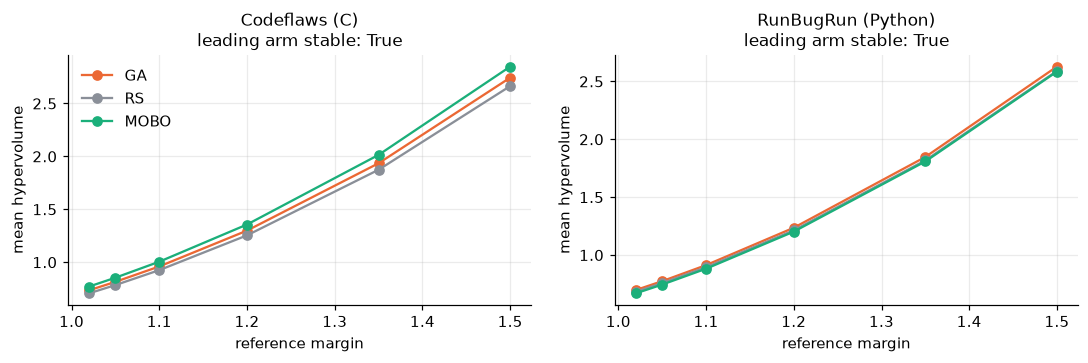

  Codeflaws (C)          stable=True  winner(s) across margins: ['MOBO']
  RunBugRun (Python)     stable=True  winner(s) across margins: ['GA']


In [13]:
MARGINS = [1.02, 1.05, 1.10, 1.20, 1.35, 1.50]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
stable = {}
for ax, b in zip(axes, BENCH):
    curves = {}
    for a in ORDER:
        ys = [st.mean([hv(sets[(b, a, i)], np.full(3, m)) for i in RP(b, a)]) for m in MARGINS]
        curves[a] = ys
        ax.plot(MARGINS, ys, "o-", color=PALETTE[a], label=a)
    winners = {max(ORDER, key=lambda a: curves[a][j]) for j in range(len(MARGINS))}
    stable[b] = (len(winners) == 1, winners)
    ax.set_title(f"{b}\nleading arm stable: {len(winners)==1}")
    ax.set_xlabel("reference margin"); ax.set_ylabel("mean hypervolume")
axes[0].legend()
fig.tight_layout(); savefig(fig, "hv_reference_sensitivity"); plt.show()
for b, (s, w) in stable.items():
    print(f"  {b:22s} stable={s}  winner(s) across margins: {sorted(w)}")

### §5b · Cardinality control

Larger fronts have more opportunities to cover objective space. Adding points to
a fixed front cannot reduce its HV, although size alone does not order arbitrary
fronts. Subsample each front to the common minimum size and average forty draws
within each repetition; comparisons still use five repetitions per arm.

In [14]:
K = min(len(sets[(b, a, i)]) for b in BENCH for a in ORDER for i in RP(b, a))
DRAWS = 40
rng = np.random.default_rng(20260825)
SIZEMATCH = {}
print(f"  subsampling every front to n = {K} points, {DRAWS} draws each\n")
for b in BENCH:
    ref = np.full(3, REF_MARGIN)
    means = {}
    for a in ORDER:
        per = []
        for i in RP(b, a):
            S = sets[(b, a, i)]
            per.append(st.mean([hv(S[rng.choice(len(S), K, replace=False)], ref)
                                for _ in range(DRAWS)]))
        means[a] = per
        SIZEMATCH[(b, a)] = per
    print(f"  {b}")
    for a in ORDER:
        print(f"    {a:5s} size-matched HV  mean {st.mean(means[a]):.4f}  "
              f"sd {st.stdev(means[a]):.4f}  (n={len(means[a])} reps)")
    for x, y in combinations(ORDER, 2):
        p, p_w, _ = between(means[x], means[y])
        print(f"    {x} vs {y:5s} MWU p = {p:.3g}  [Welch {p_w:.3g}]  "
              f"(n={len(means[x])} vs {len(means[y])})")
    lead = max(ORDER, key=lambda a: st.mean(means[a]))
    raw = max(ORDER, key=lambda a: st.mean(hv_vals[(b, a)]))
    print(f"    leader raw = {raw}, size-matched = {lead}  "
          f"{'(unchanged)' if raw == lead else '(CHANGED by cardinality control)'}\n")

  subsampling every front to n = 33 points, 40 draws each

  Codeflaws (C)
    GA    size-matched HV  mean 0.9338  sd 0.0361  (n=5 reps)
    RS    size-matched HV  mean 0.9124  sd 0.0482  (n=5 reps)
    MOBO  size-matched HV  mean 0.9731  sd 0.0625  (n=5 reps)
    GA vs RS    MWU p = 0.548  [Welch 0.451]  (n=5 vs 5)
    GA vs MOBO  MWU p = 0.421  [Welch 0.267]  (n=5 vs 5)
    RS vs MOBO  MWU p = 0.151  [Welch 0.126]  (n=5 vs 5)
    leader raw = MOBO, size-matched = MOBO  (unchanged)



  RunBugRun (Python)
    GA    size-matched HV  mean 0.8880  sd 0.0371  (n=5 reps)
    RS    size-matched HV  mean 0.8826  sd 0.0780  (n=5 reps)
    MOBO  size-matched HV  mean 0.8470  sd 0.0228  (n=5 reps)
    GA vs RS    MWU p = 0.548  [Welch 0.893]  (n=5 vs 5)
    GA vs MOBO  MWU p = 0.0556  [Welch 0.0753]  (n=5 vs 5)
    RS vs MOBO  MWU p = 0.841  [Welch 0.375]  (n=5 vs 5)
    leader raw = GA, size-matched = GA  (unchanged)



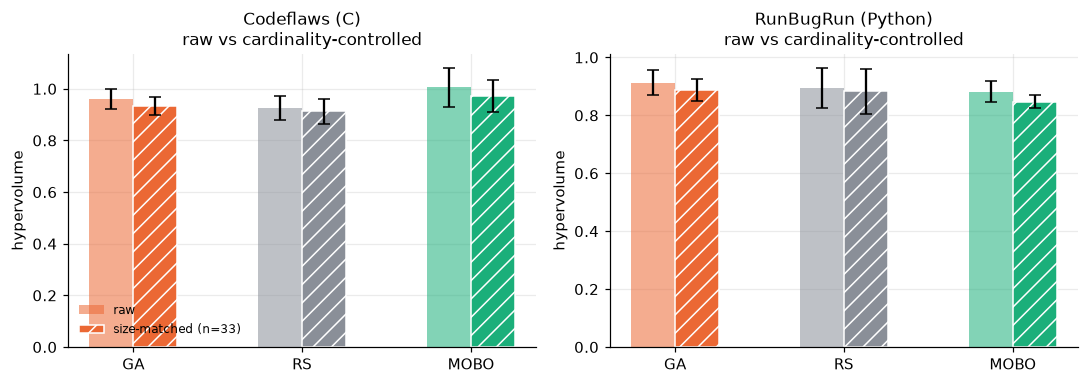

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
w = 0.26
for ax, b in zip(axes, BENCH):
    for k, a in enumerate(ORDER):
        raw = hv_vals[(b, a)]; sm = SIZEMATCH[(b, a)]
        ax.bar(k - w/2, st.mean(raw), w, yerr=st.stdev(raw), capsize=4,
               color=PALETTE[a], alpha=0.55, label="raw" if k == 0 else None)
        ax.bar(k + w/2, st.mean(sm), w, yerr=st.stdev(sm), capsize=4,
               color=PALETTE[a], hatch="//", edgecolor="white",
               label=f"size-matched (n={K})" if k == 0 else None)
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER)
    ax.set_ylabel("hypervolume"); ax.set_title(f"{b}\nraw vs cardinality-controlled")
axes[0].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "cardinality_control"); plt.show()

### §5c · IGD+, additive ε and pooled-front contribution

Hypervolume rewards spread as well as proximity. IGD+ measures distance to a
reference set with the Pareto-compliance correction; additive ε measures the
worst-case shift needed to dominate it. The reference set is the non-dominated
union of every front on that benchmark, so both are relative measures of how
much of the collectively-known trade-off surface each arm recovers.

Pooled-front contribution counts how many of a repetition's points survive into
that union — a direct count of unique contribution, insensitive to spread.

In [16]:
IND = {}
for b in BENCH:
    U = sets[(b, "union", None)]
    print(f"  {b}   (reference set: {len(U)} non-dominated points from the union)")
    print(f"    {'arm':5s}{'IGD+':>10s}{'sd':>8s}{'eps+':>10s}{'sd':>8s}{'pooled pts':>12s}{'share':>9s}")
    for a in ORDER:
        ig = [igd_plus(sets[(b, a, i)], U) for i in RP(b, a)]
        ep = [eps_plus(sets[(b, a, i)], U) for i in RP(b, a)]
        contrib = 0
        for i in RP(b, a):
            S = sets[(b, a, i)]
            contrib += sum(1 for s in S if any(np.array_equal(s, u) for u in U))
        IND[(b, a)] = dict(igd=ig, eps=ep, contrib=contrib, ref=len(U))
        print(f"    {a:5s}{st.mean(ig):10.4f}{st.stdev(ig):8.4f}{st.mean(ep):10.4f}"
              f"{st.stdev(ep):8.4f}{contrib:12d}{100*contrib/len(U):8.1f}%")
    print()

  Codeflaws (C)   (reference set: 45 non-dominated points from the union)
    arm        IGD+      sd      eps+      sd  pooled pts    share
    GA       0.0527  0.0093    0.1809  0.0466          16    35.6%
    RS       0.0617  0.0123    0.2125  0.0426           8    17.8%
    MOBO     0.0451  0.0122    0.1726  0.0590          21    46.7%

  RunBugRun (Python)   (reference set: 55 non-dominated points from the union)
    arm        IGD+      sd      eps+      sd  pooled pts    share


    GA       0.0572  0.0113    0.1648  0.0260          22    40.0%
    RS       0.0674  0.0127    0.1942  0.0575          16    29.1%
    MOBO     0.0700  0.0144    0.2059  0.0308          17    30.9%



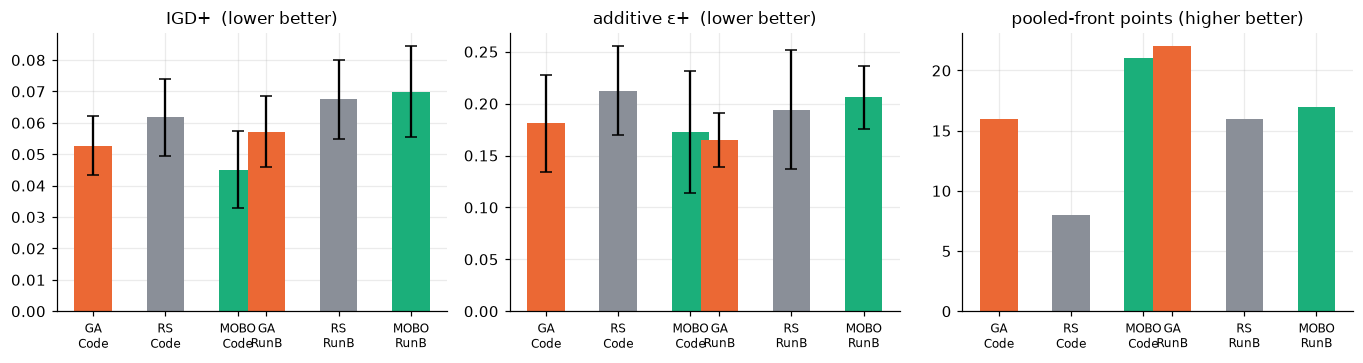

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
w = 0.26
for ax, (metric, lab, better) in zip(
        axes, [("igd", "IGD+  (lower better)", "lo"),
               ("eps", "additive ε+  (lower better)", "lo"),
               ("contrib", "pooled-front points (higher better)", "hi")]):
    xt, xl = [], []
    for bi, b in enumerate(BENCH):
        for k, a in enumerate(ORDER):
            x = bi * 2.4 + k
            if metric == "contrib":
                ax.bar(x, IND[(b, a)]["contrib"], w * 2, color=PALETTE[a])
            else:
                v = IND[(b, a)][metric]
                ax.bar(x, st.mean(v), w * 2, yerr=st.stdev(v), capsize=4, color=PALETTE[a])
            xt.append(x); xl.append(f"{a}\n{b.split(' ')[0][:4]}")
    ax.set_xticks(xt); ax.set_xticklabels(xl, fontsize=8); ax.set_title(lab)
fig.tight_layout(); savefig(fig, "set_indicators"); plt.show()

#### Interpretation

HV, IGD+ and additive ε emphasise different aspects of the empirical front.
Agreement in their mean ordering is a descriptive sensitivity check; it is not
independent replication. Disagreement does not uniquely identify its cause:
coverage, proximity, reference-set geometry and scaling can all contribute.

## §6 · Paired upstream-task inference

All arms share the same 100 held-out records. Resample upstream tasks to retain
sibling dependence: **98 Codeforces tasks** on C and **68 tasks** on Python.
First pool policy/record observations within each task; then give tasks equal
weight. Larger fronts contribute more observations to a task's pooled mean.
F1 and F3 use only feasible observations; F2 uses every record.

These intervals condition on the evaluated policies and estimate task-sampling
uncertainty. They do not account for search-run variation, policy remeasurement
or training/test task overlap; they complement the repetition-level analysis.

In [18]:
# The resampling unit is the upstream problem, not the held-out record. On
# RunBugRun the 100 records collapse to 68 upstream tasks -- siblings share a
# task and a test suite, so treating them as independent narrows the intervals.
# Codeflaws has 100 bug records from 98 Codeforces tasks; use the task prefix.
# F1 and F3 are defined over feasible problems only: the search drivers
# aggregate mean_cl over feasible_cls and mean_energy over feasible_runtimes.
# An infeasible attempt can still emit a complexity number: a program that
# compiles but passes no test. Admitting those here contradicts the contract and
# is enough to reverse the sign of the RunBugRun F1 result, so the filter is not
# optional. Correctness is defined over all problems, infeasible scoring zero.
FEASIBLE_ONLY = {"cl", "runtime_mj"}

def problem_vector(recs, key):
    # Mean over policies of a per-problem value, keyed by upstream group.
    acc = {}
    for r in recs:
        pp = r["per_problem"]; pp = pp if isinstance(pp, list) else list(pp.values())
        for q in pp:
            if key in FEASIBLE_ONLY and not q.get("feasible"):
                continue
            v = q.get(key)
            if isinstance(v, (int, float)) and math.isfinite(v):
                acc.setdefault(upstream_key(q), []).append(v)
    return {k: st.mean(v) for k, v in acc.items()}

def baseline_vector(b, key):
    acc = {}
    for rep in baseline[b]["reps"]:
        pp = rep["per_problem"]; pp = pp if isinstance(pp, list) else list(pp.values())
        for q in pp:
            if key in FEASIBLE_ONLY and not q.get("feasible"):
                continue
            v = q.get(key)
            if isinstance(v, (int, float)) and math.isfinite(v):
                acc.setdefault(upstream_key(q), []).append(v)
    return {k: st.mean(v) for k, v in acc.items()}

BOOT, SEED = 5000, 20260825
def paired_boot(dx, n_boot=BOOT):
    rng = np.random.default_rng(SEED)
    x = np.array(dx)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    means = x[idx].mean(1)
    return float(x.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

PKEY = {"correctness": "correctness", "cl": "cl", "runtime_mj": "runtime_mj"}
contrasts = {}
for b in BENCH:
    print(f"\n  {b}   (paired on problem, {BOOT} bootstrap resamples of problems)")
    print(f"    {'contrast':22s}{'objective':14s}{'delta':>10s}{'95% CI':>22s}{'excl 0':>8s}{'Wilcoxon p':>12s}")
    vec = {a: {k: problem_vector([x for i in RP(b, a) for x in policies[b][a][i]], k) for k in PKEY}
           for a in ORDER}
    vec["Baseline"] = {k: baseline_vector(b, k) for k in PKEY}
    CONTRASTS = ([(a, "Baseline") for a in ORDER] +
                 [(y, x) for x, y in combinations(ORDER, 2)])
    for lo, hi in CONTRASTS:
        for k, lab, better in (("correctness", "F2 correctness", "hi"),
                               ("cl", "F1 complexity", "lo"),
                               ("runtime_mj", "F3 energy", "lo")):
            common = sorted(set(vec[lo][k]) & set(vec[hi][k]))
            d = [vec[lo][k][p] - vec[hi][k][p] for p in common]
            m, l, u = paired_boot(d)
            try: _, wp = wilcoxon(d)
            except Exception: wp = float("nan")
            excl = (l > 0) or (u < 0)
            contrasts[(b, lo, hi, k)] = dict(mean=m, lo=l, hi=u, excl=excl, p=wp, n=len(common))
            print(f"    {lo+' - '+hi:22s}{lab:14s}{m:+10.4f}  [{l:+8.4f},{u:+8.4f}]{str(excl):>8s}{wp:12.3g}")


  Codeflaws (C)   (paired on problem, 5000 bootstrap resamples of problems)
    contrast              objective          delta                95% CI  excl 0  Wilcoxon p
    GA - Baseline         F2 correctness   -0.0058  [ -0.0270, +0.0159]   False       0.736
    GA - Baseline         F1 complexity    +0.0591  [ -0.0506, +0.1858]   False       0.372
    GA - Baseline         F3 energy        +5.9464  [ -2.0418,+15.9678]   False    5.47e-09
    RS - Baseline         F2 correctness   +0.0226  [ -0.0000, +0.0457]   False      0.0232
    RS - Baseline         F1 complexity    +0.0980  [ -0.0185, +0.2357]   False       0.266
    RS - Baseline         F3 energy        -0.4203  [ -2.8377, +2.8883]   False    5.75e-09
    MOBO - Baseline       F2 correctness   +0.0034  [ -0.0181, +0.0257]   False       0.565
    MOBO - Baseline       F1 complexity    +0.0855  [ -0.0307, +0.2250]   False       0.314
    MOBO - Baseline       F3 energy        +4.2093  [ -1.4324,+12.0867]   False    2.85e-06
  

    RS - Baseline         F2 correctness   +0.0287  [ +0.0040, +0.0572]    True       0.209
    RS - Baseline         F1 complexity    -0.0834  [ -0.1578, -0.0213]    True       0.305
    RS - Baseline         F3 energy       -12.6236  [-15.8534, -9.3852]    True    1.94e-08
    MOBO - Baseline       F2 correctness   +0.0199  [ -0.0039, +0.0480]   False       0.498
    MOBO - Baseline       F1 complexity    -0.0766  [ -0.1492, -0.0152]    True       0.358
    MOBO - Baseline       F3 energy       -12.5642  [-15.9569, -9.1536]    True    5.33e-08
    RS - GA               F2 correctness   +0.0071  [ +0.0017, +0.0124]    True     0.00383
    RS - GA               F1 complexity    -0.0121  [ -0.0240, -0.0004]    True      0.0371
    RS - GA               F3 energy        +0.8905  [ -0.3961, +2.5938]   False       0.744
    MOBO - GA             F2 correctness   -0.0018  [ -0.0076, +0.0040]   False       0.971
    MOBO - GA             F1 complexity    -0.0053  [ -0.0168, +0.0071]   False 

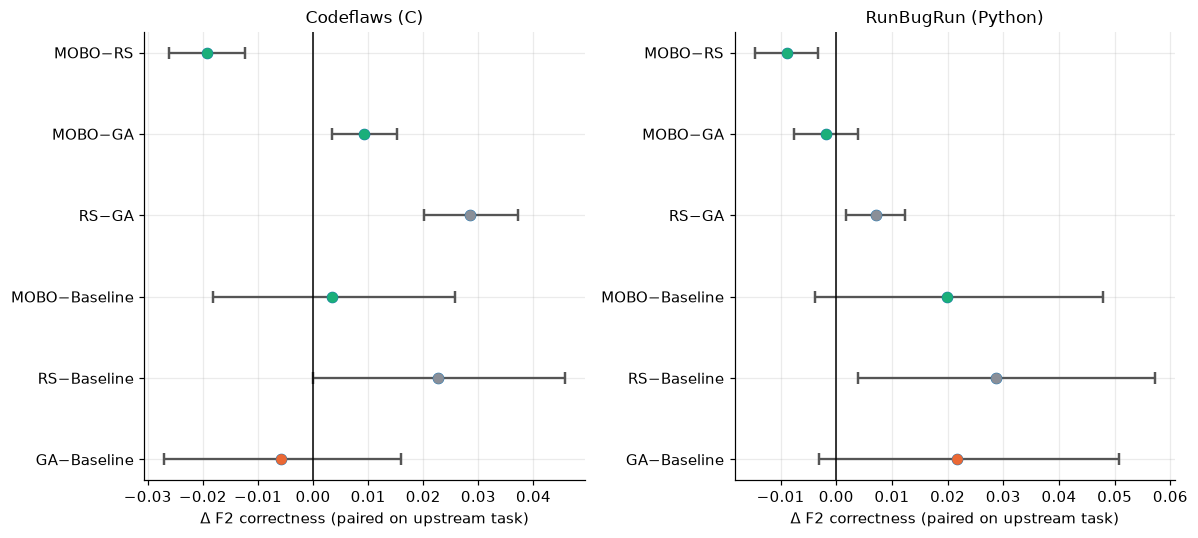

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.0))
for ax, b in zip(axes, BENCH):
    labels, mids, los, his, cols = [], [], [], [], []
    for lo, hi in ([(a, "Baseline") for a in ORDER] + [(y,x) for x,y in combinations(ORDER,2)]):
        c = contrasts[(b, lo, hi, "correctness")]
        labels.append(f"{lo}−{hi}"); mids.append(c["mean"])
        los.append(c["mean"] - c["lo"]); his.append(c["hi"] - c["mean"])
        cols.append(PALETTE.get(lo, "black"))
    y = range(len(labels))
    ax.errorbar(mids, y, xerr=[los, his], fmt="o", capsize=4,
                ecolor="#555", markerfacecolor="white", markeredgewidth=1.6)
    for yi, m, c in zip(y, mids, cols):
        ax.plot(m, yi, "o", color=c, zorder=3)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(list(y)); ax.set_yticklabels(labels)
    ax.set_xlabel("Δ F2 correctness (paired on upstream task)")
    ax.set_title(b)
fig.tight_layout(); savefig(fig, "paired_bootstrap_f2"); plt.show()

#### Interpretation

An interval excluding zero indicates the contrast is stable under resampling of
problems. It is not a significance test of the *method* comparison — the
resampling unit is the upstream problem, so the inference generalises to other
problems drawn from this benchmark, holding each arm's repetitions fixed. It
also pools policies before resampling, which weights repetitions by front
cardinality rather than equally. Generalisation
across searches is what §3 and §4 address.

## §7 · Sensitivity to the choice of estimator

C per-policy F3 is right-skewed. This section compares mean, median and trimmed
mean summaries; it does not identify which underlying repairs caused the tail.
When the direction against baseline depends on the estimator, state that
sensitivity instead of reporting one summary as the unique result.

In [20]:
print(f"  {'benchmark':22s}{'arm':6s}{'mean':>10s}{'median':>10s}{'ratio':>8s}{'trimmed 10%':>13s}{'skew':>8s}")
for b in BENCH:
    for a in ORDER:
        v = np.array(flat(b, a, "mean_energy"))
        s = float(((v - v.mean()) ** 3).mean() / (v.std() ** 3 + 1e-12))
        tr = float(np.mean(np.sort(v)[int(.05*len(v)):len(v)-int(.05*len(v))]))
        print(f"  {b:22s}{a:6s}{v.mean():10.2f}{np.median(v):10.2f}"
              f"{v.mean()/np.median(v):8.3f}{tr:13.2f}{s:8.2f}")
    bs = baseline[b]["summary"]["mean_energy"]
    print(f"  {b:22s}{'base':6s}{bs['mean']:10.2f}{'':10s}{'':8s}{'':13s}")

print("\n  does the RS-GA sign on F3 depend on the estimator?")
for b in BENCH:
    row = []
    for est, fn in (("mean", np.mean), ("median", np.median),
                    ("trimmed", lambda v: np.mean(np.sort(v)[int(.05*len(v)):len(v)-int(.05*len(v))]))):
        g = fn(np.array(flat(b, "GA", "mean_energy")))
        r = fn(np.array(flat(b, "RS", "mean_energy")))
        row.append(f"{est}: {'RS lower' if r < g else 'GA lower'} ({r-g:+.2f})")
    print(f"    {b:22s} " + " | ".join(row))

  benchmark             arm         mean    median   ratio  trimmed 10%    skew
  Codeflaws (C)         GA         39.46     32.20   1.226        32.43    8.03
  Codeflaws (C)         RS         33.05     32.68   1.011        32.31    3.53
  Codeflaws (C)         MOBO       40.90     33.14   1.234        35.23    8.69
  Codeflaws (C)         base       35.56                               
  RunBugRun (Python)    GA        259.03    232.24   1.115       256.19    1.03
  RunBugRun (Python)    RS        264.29    232.63   1.136       262.12    0.81
  RunBugRun (Python)    MOBO      254.64    232.45   1.095       251.04    1.36
  RunBugRun (Python)    base      243.59                               

  does the RS-GA sign on F3 depend on the estimator?
    Codeflaws (C)          mean: RS lower (-6.41) | median: GA lower (+0.48) | trimmed: RS lower (-0.12)
    RunBugRun (Python)     mean: GA lower (+5.26) | median: GA lower (+0.39) | trimmed: GA lower (+5.94)


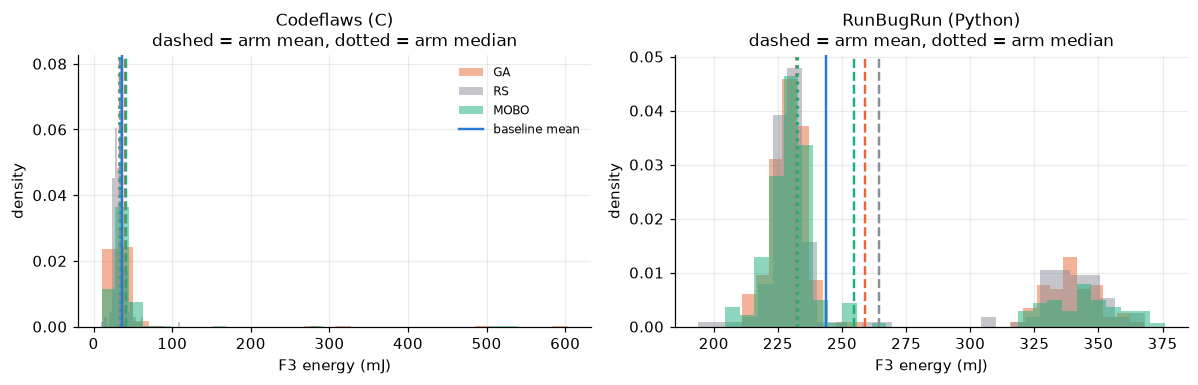

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, b in zip(axes, BENCH):
    for k, a in enumerate(ORDER):
        v = np.array(flat(b, a, "mean_energy"))
        ax.hist(v, bins=30, alpha=0.5, color=PALETTE[a], label=a, density=True)
        ax.axvline(v.mean(), color=PALETTE[a], ls="--", lw=1.6)
        ax.axvline(np.median(v), color=PALETTE[a], ls=":", lw=2)
    bs = baseline[b]["summary"]["mean_energy"]["mean"]
    ax.axvline(bs, color=C_BASE, lw=1.6, label="baseline mean")
    ax.set_xlabel("F3 energy (mJ)"); ax.set_ylabel("density")
    ax.set_title(f"{b}\ndashed = arm mean, dotted = arm median")
axes[0].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "f3_estimator_sensitivity"); plt.show()

## §8 · Generalisation from training to held-out

Each policy carries the fitness it achieved on the 50 training problems, which
is the signal the search optimised. Whether that signal predicts performance on
unseen problems determines whether the search was optimising anything
transferable — and, at the level of whole repetitions, whether training-front
quality is a valid basis for comparing arms at all.

  per-policy rank correlation, training fitness vs held-out (pooled over 5 reps)

  benchmark             arm  objective         Spearman rho         p     n
  Codeflaws (C)         GA   F2 correctness          +0.732  1.68e-38   222
  Codeflaws (C)         GA   F1 complexity           +0.278  2.68e-05   222
  Codeflaws (C)         GA   F3 energy               +0.068     0.315   222
  Codeflaws (C)         RS   F2 correctness          +0.515  7.85e-15   198
  Codeflaws (C)         RS   F1 complexity           +0.187   0.00818   198
  Codeflaws (C)         RS   F3 energy               -0.095     0.182   198
  Codeflaws (C)         MOBO F2 correctness          +0.715  1.21e-39   245
  Codeflaws (C)         MOBO F1 complexity           +0.505  2.91e-17   245
  Codeflaws (C)         MOBO F3 energy               -0.008       0.9   245
  RunBugRun (Python)    GA   F2 correctness          +0.557  1.85e-19   222
  RunBugRun (Python)    GA   F1 complexity           -0.112    0.0974   222
  RunB

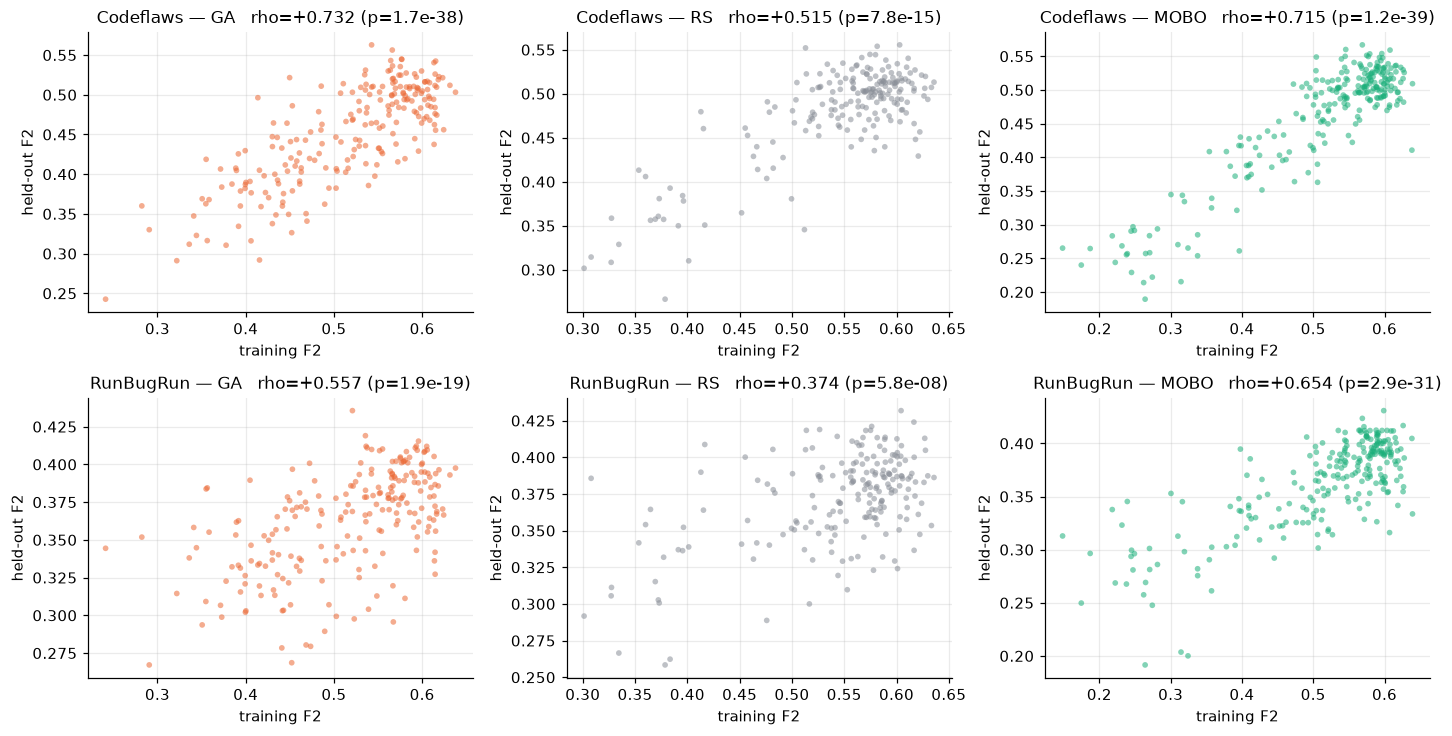

In [22]:
TRAIN_RANK = {}

print("  per-policy rank correlation, training fitness vs held-out (pooled over 5 reps)\n")
print(f"  {'benchmark':22s}{'arm':5s}{'objective':16s}{'Spearman rho':>14s}{'p':>10s}{'n':>6s}")
for b in BENCH:
    for a in ORDER:
        recs = [x for i in RP(b, a) for x in policies[b][a][i] if x.get("train_fitness")]
        for tk, hk, lab in (("correctness", "mean_correctness", "F2 correctness"),
                            ("cl", "mean_cl", "F1 complexity"),
                            ("energy", "mean_energy", "F3 energy")):
            t = [r["train_fitness"][tk] for r in recs]
            h = [r[hk] for r in recs]
            keep = [(x, y) for x, y in zip(t, h)
                    if isinstance(x, (int, float)) and isinstance(y, (int, float))
                    and x == x and y == y and math.isfinite(x) and math.isfinite(y)]
            rho, p = spearmanr([k[0] for k in keep], [k[1] for k in keep])
            TRAIN_RANK[(b, a, tk)] = dict(rho=float(rho), p=float(p), n=len(keep))
            print(f"  {b:22s}{a:5s}{lab:16s}{rho:+14.3f}{p:10.3g}{len(keep):6d}")

fig, axes = plt.subplots(len(BENCH), len(ORDER),
                         figsize=(4.4 * len(ORDER), 3.4 * len(BENCH)), squeeze=False)
for r, b in enumerate(BENCH):
    for c, a in enumerate(ORDER):
        ax = axes[r, c]
        recs = [x for i in RP(b, a) for x in policies[b][a][i] if x.get("train_fitness")]
        t = [x["train_fitness"]["correctness"] for x in recs]
        h = [x["mean_correctness"] for x in recs]
        ax.scatter(t, h, s=14, alpha=0.55, color=PALETTE[a], edgecolor="none")
        rho, p = spearmanr(t, h)
        ax.set_title(f"{b.split(' ')[0]} — {a}   rho={rho:+.3f} (p={p:.2g})")
        ax.set_xlabel("training F2"); ax.set_ylabel("held-out F2")
fig.tight_layout(); savefig(fig, "train_vs_heldout"); plt.show()

#### Interpretation

A near-zero Spearman correlation indicates little monotonic rank association
within the retained sample; it does not rule out nonlinear predictive structure.
A negative association can make the training ranking unhelpful, but does not by
itself prove that every selection rule is worse than random selection. The
shortlist analysis tests that selection question descriptively. Pareto selection
conditions on multiple objectives, so neither attenuation nor a bound on a
population correlation is guaranteed.

## §9 · Cross-language behaviour of the same policies

Every policy vector is matched exactly across benchmarks. This permits a
within-policy comparison; it does not isolate a causal policy contribution from
benchmark differences. F2 is a dimensionless test-pass fraction, but test suites
and task difficulty differ. F1 and F3 measure different programs and execution
environments and are reported within benchmark.

  policies matched on exact policy vector across both benchmarks: 665
  F2 rank correlation across benchmarks: Spearman rho = +0.634 (p=3.57e-76)
    within GA: rho = +0.629 (p=7.9e-26, n=222)
    within RS: rho = +0.493 (p=1.69e-13, n=198)
    within MOBO: rho = +0.706 (p=3.07e-38, n=245)

  spread (sd of F2): Codeflaws (C) 0.0703   RunBugRun (Python) 0.0368
  These are correlations conditional on retained fronts, not lower bounds on population correlations.


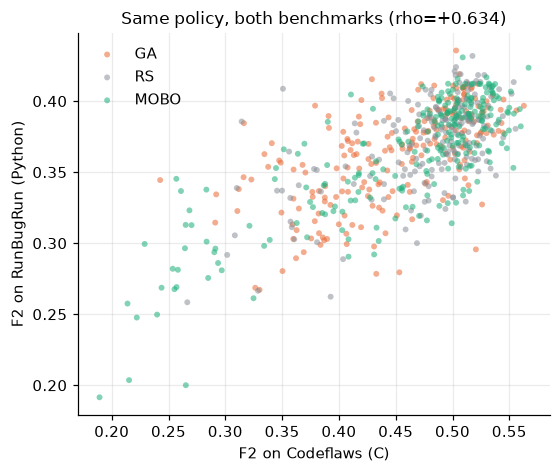

In [23]:
bs = list(BENCH)
pairs = []
for a in ORDER:
    for i in RP(bs[0], a):
        A = {json.dumps(x["policy"], sort_keys=True): x for x in policies[bs[0]][a][i]}
        B = {json.dumps(x["policy"], sort_keys=True): x for x in policies[bs[1]][a][i]}
        assert set(A) == set(B), (a, i, "cross-language policy mismatch")
        for k in sorted(A):
            pairs.append((a, A[k]["mean_correctness"], B[k]["mean_correctness"],
                          A[k]["mean_cl"], B[k]["mean_cl"]))
print(f"  policies matched on exact policy vector across both benchmarks: {len(pairs)}")

x = [p[1] for p in pairs]; y = [p[2] for p in pairs]
rho, p = spearmanr(x, y)
print(f"  F2 rank correlation across benchmarks: Spearman rho = {rho:+.3f} (p={p:.3g})")
for a in ORDER:
    xa = [q[1] for q in pairs if q[0] == a]; ya = [q[2] for q in pairs if q[0] == a]
    r2, p2 = spearmanr(xa, ya)
    print(f"    within {a}: rho = {r2:+.3f} (p={p2:.3g}, n={len(xa)})")
print(f"\n  spread (sd of F2): {bs[0]} {st.stdev(x):.4f}   {bs[1]} {st.stdev(y):.4f}")
print("  These are correlations conditional on retained fronts, not lower bounds on population correlations.")
CROSS_LANGUAGE = dict(n=len(pairs), rho=float(rho), p=float(p), sd_c=st.stdev(x), sd_py=st.stdev(y))

fig, ax = plt.subplots(figsize=(5.2, 4.4))
for a in ORDER:
    ax.scatter([q[1] for q in pairs if q[0] == a], [q[2] for q in pairs if q[0] == a],
               s=15, alpha=0.55, color=PALETTE[a], edgecolor="none", label=a)
ax.set_xlabel(f"F2 on {bs[0]}"); ax.set_ylabel(f"F2 on {bs[1]}")
ax.set_title(f"Same policy, both benchmarks (rho={rho:+.3f})"); ax.legend()
fig.tight_layout(); savefig(fig, "cross_language_f2"); plt.show()

## §10 · Per-problem structure

Aggregate differences can arise either because an arm is broadly better or
because it resolves a small number of problems the other does not. The two have
different implications, and are distinguished by counting problems rather than
averaging over them.


  Codeflaws (C)   (98 problems)
    RS better than GA on  73 problems, worse on  23, tied   2
    GA    better than baseline on  46
    RS    better than baseline on  54
    MOBO  better than baseline on  48
    tasks with no passing test in any observation :   1 / 98
    tasks fully correct in every observation   :   0 / 98
    per-problem difficulty correlation GA vs RS   : rho=+0.992 (p=7.56e-88)
    per-problem difficulty correlation GA vs MOBO : rho=+0.992 (p=1.51e-88)
    per-problem difficulty correlation RS vs MOBO : rho=+0.994 (p=1.48e-92)

  RunBugRun (Python)   (68 problems)
    RS better than GA on  41 problems, worse on  17, tied  10
    GA    better than baseline on  29
    RS    better than baseline on  30
    MOBO  better than baseline on  31
    tasks with no passing test in any observation :   8 / 68
    tasks fully correct in every observation   :   0 / 68
    per-problem difficulty correlation GA vs RS   : rho=+0.992 (p=1.58e-61)
    per-problem difficulty correlat

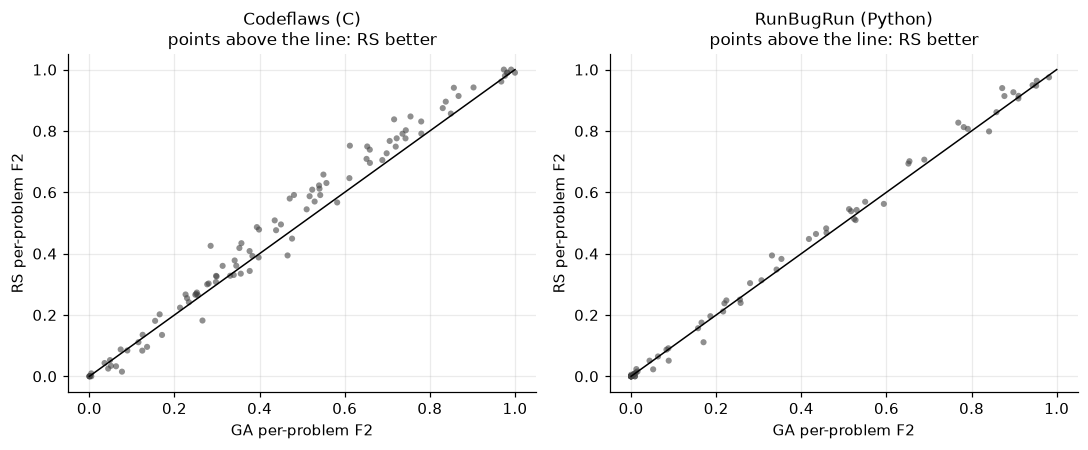

In [24]:
PROBLEM_SUMMARY = {}

for b in BENCH:
    va = {a: problem_vector([x for i in RP(b, a) for x in policies[b][a][i]], "correctness") for a in ORDER}
    vb = baseline_vector(b, "correctness")
    # The intersection and the all-arm counts span every arm plus the baseline.
    # Omitting an arm inflates the "solved by nothing" count, since a problem
    # that arm solves is no longer counted.
    common = sorted(set.intersection(*[set(va[a]) for a in ORDER], set(vb)))
    A = {a: np.array([va[a][p] for p in common]) for a in ORDER}
    bl = np.array([vb[p] for p in common])
    ga, rs = A["GA"], A["RS"]
    print(f"\n  {b}   ({len(common)} problems)")
    print(f"    RS better than GA on {int((rs>ga).sum()):3d} problems, worse on {int((rs<ga).sum()):3d}, tied {int((rs==ga).sum()):3d}")
    for a in ORDER:
        print(f"    {a:5s} better than baseline on {int((A[a]>bl).sum()):3d}")
    allzero = np.logical_and.reduce([A[a] == 0 for a in ORDER] + [bl == 0])
    allone  = np.logical_and.reduce([A[a] == 1 for a in ORDER] + [bl == 1])
    print(f"    tasks with no passing test in any observation : {int(allzero.sum()):3d} / {len(common)}")
    print(f"    tasks fully correct in every observation   : {int(allone.sum()):3d} / {len(common)}")
    PROBLEM_SUMMARY[b] = dict(n=len(common), rs_better=int((rs>ga).sum()),
        rs_worse=int((rs<ga).sum()), tied=int((rs==ga).sum()), no_passing_tests=int(allzero.sum()),
        every_observation_fully_correct=int(allone.sum()))
    pp_vec = {a: problem_vector([x for i in RP(b, a) for x in policies[b][a][i]], "correctness")
              for a in ORDER}
    for x, y in combinations(ORDER, 2):
        common_ = sorted(set(pp_vec[x]) & set(pp_vec[y]))
        rho, p = spearmanr([pp_vec[x][q] for q in common_], [pp_vec[y][q] for q in common_])
        print(f"    per-problem difficulty correlation {x} vs {y:5s}: rho={rho:+.3f} (p={p:.3g})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, b in zip(axes, BENCH):
    va = {a: problem_vector([x for i in RP(b, a) for x in policies[b][a][i]], "correctness") for a in ORDER}
    common = sorted(set(va["GA"]) & set(va["RS"]))
    ga = [va["GA"][p] for p in common]; rs = [va["RS"][p] for p in common]
    ax.scatter(ga, rs, s=16, alpha=0.6, color="#444", edgecolor="none")
    lim = [0, 1]
    ax.plot(lim, lim, color="black", lw=1)
    ax.set_xlabel("GA per-problem F2"); ax.set_ylabel("RS per-problem F2")
    ax.set_title(f"{b}\npoints above the line: RS better")
fig.tight_layout(); savefig(fig, "per_problem_scatter"); plt.show()

#### Interpretation

High cross-arm task correlations show shared difficulty in these observed
attempts. They do not establish intrinsic task difficulty independent of policy,
or an achievable ceiling for another search budget or model. Tasks with all-zero
observations received no passing test in this experiment; they are not proved
unsolvable.

## §11 · Descriptive correctness-to-energy ratio

This ratio combines the optimised F2 and F3 and is therefore not independent of
the selection criteria. For each policy, divide mean correctness over all records by mean feasible-record
execution energy in joules, then summarise those policy-level ratios. Baseline
ratios are calculated per repetition. This is not a ratio of pooled means. It is
not total pipeline efficiency, a same-task comparison at fixed correctness, or
a search-cost break-even calculation. Compare it within benchmark only.

In [25]:
print(f"  {'benchmark':22s}{'arm':6s}{'F2/J (mean)':>14s}{'F2/J (median)':>16s}")
for b in BENCH:
    for a in ORDER:
        recs = [x for i in RP(b, a) for x in policies[b][a][i]]
        r = [x["mean_correctness"] / (x["mean_energy"] / 1000.0)
             for x in recs
             if isinstance(x["mean_energy"], (int, float)) and x["mean_energy"] == x["mean_energy"]
             and x["mean_energy"] > 0]
        print(f"  {b:22s}{a:6s}{st.mean(r):14.3f}{st.median(r):16.3f}")
    # The arms above summarise a distribution of per-policy ratios. Summarising
    # the baseline as a ratio of grand means is a different estimator and is not
    # comparable with them under F3's strong right skew, so the baseline is
    # computed per repetition and summarised the same way.
    br = [rep["mean_correctness"] / (rep["mean_energy"] / 1000.0)
          for rep in baseline[b]["reps"]
          if isinstance(rep["mean_energy"], (int, float)) and rep["mean_energy"] > 0]
    print(f"  {b:22s}{'base':6s}{st.mean(br):14.3f}{st.median(br):16.3f}")

  benchmark             arm      F2/J (mean)   F2/J (median)
  Codeflaws (C)         GA            14.792          14.800
  Codeflaws (C)         RS            15.263          15.318
  Codeflaws (C)         MOBO          13.849          14.708
  Codeflaws (C)         base          13.172          13.437
  RunBugRun (Python)    GA             1.440           1.516
  RunBugRun (Python)    RS             1.453           1.558
  RunBugRun (Python)    MOBO           1.462           1.555
  RunBugRun (Python)    base           1.403           1.411


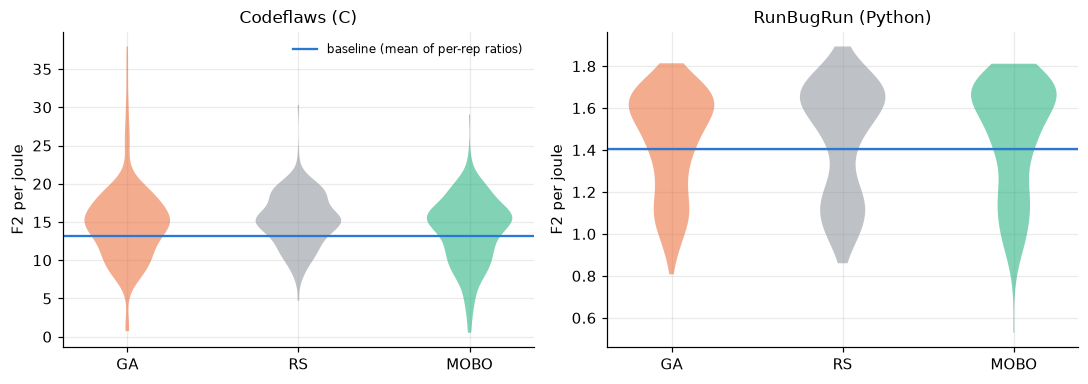

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, b in zip(axes, BENCH):
    data, cols = [], []
    for a in ORDER:
        recs = [x for i in RP(b, a) for x in policies[b][a][i]]
        data.append([x["mean_correctness"] / (x["mean_energy"] / 1000.0) for x in recs
                     if isinstance(x["mean_energy"], (int, float))
                     and x["mean_energy"] == x["mean_energy"] and x["mean_energy"] > 0])
        cols.append(PALETTE[a])
    parts = ax.violinplot(data, showextrema=False)
    for pc, c in zip(parts["bodies"], cols):
        pc.set_facecolor(c); pc.set_alpha(0.55)
    # Same estimator as the table above: mean of per-repetition ratios, not a
    # ratio of grand means. The figure previously drew the latter.
    _br = [rep["mean_correctness"] / (rep["mean_energy"] / 1000.0)
           for rep in baseline[b]["reps"]
           if isinstance(rep["mean_energy"], (int, float)) and rep["mean_energy"] > 0]
    ax.axhline(st.mean(_br), color=C_BASE, lw=1.5, label="baseline (mean of per-rep ratios)")
    ax.set_xticks(range(1, len(ORDER) + 1)); ax.set_xticklabels(ORDER)
    ax.set_ylabel("F2 per joule"); ax.set_title(b)
axes[0].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "efficiency"); plt.show()

## §12 · Policy space

Marginal distributions describe where GA and RS retained policies in the eleven
parameters. Similar marginals do not establish a shared optimum or identify the
cause of outcome differences. Later joint-space displays include MOBO. Retry
budgets can affect repair attempts, correctness and pipeline cost, but these
plots do not identify causal effects of individual parameters.

  marginal distributions on Codeflaws (C) fronts (identical policies on the other benchmark)

  dimension        GA mean    GA sd   RS mean    RS sd MOBO mean  MOBO sd    p RS-GA  p MOBO-GA  p MOBO-RS
  pi_a.temp          0.547    0.232     0.497    0.284     0.500    0.445     0.0838      0.583      0.998
  pi_a.top_p         0.756    0.137     0.744    0.148     0.777    0.226       0.43     0.0599     0.0327
  pi_a.top_k        53.036   25.382    51.106   25.449    69.376   38.544      0.331   2.66e-10   2.93e-10
  pi_r.temp          0.630    0.269     0.569    0.295     0.601    0.384     0.0507       0.29     0.0254
  pi_r.top_p         0.848    0.156     0.767    0.156     0.783    0.191   7.23e-08    0.00405      0.179
  pi_r.top_k        54.198   28.116    54.621   25.968    60.078   39.716      0.896     0.0265      0.036
  pi_o.temp          0.415    0.283     0.477    0.305     0.532    0.442     0.0442     0.0275       0.15
  pi_o.top_p         0.723    0.120     0.759    0

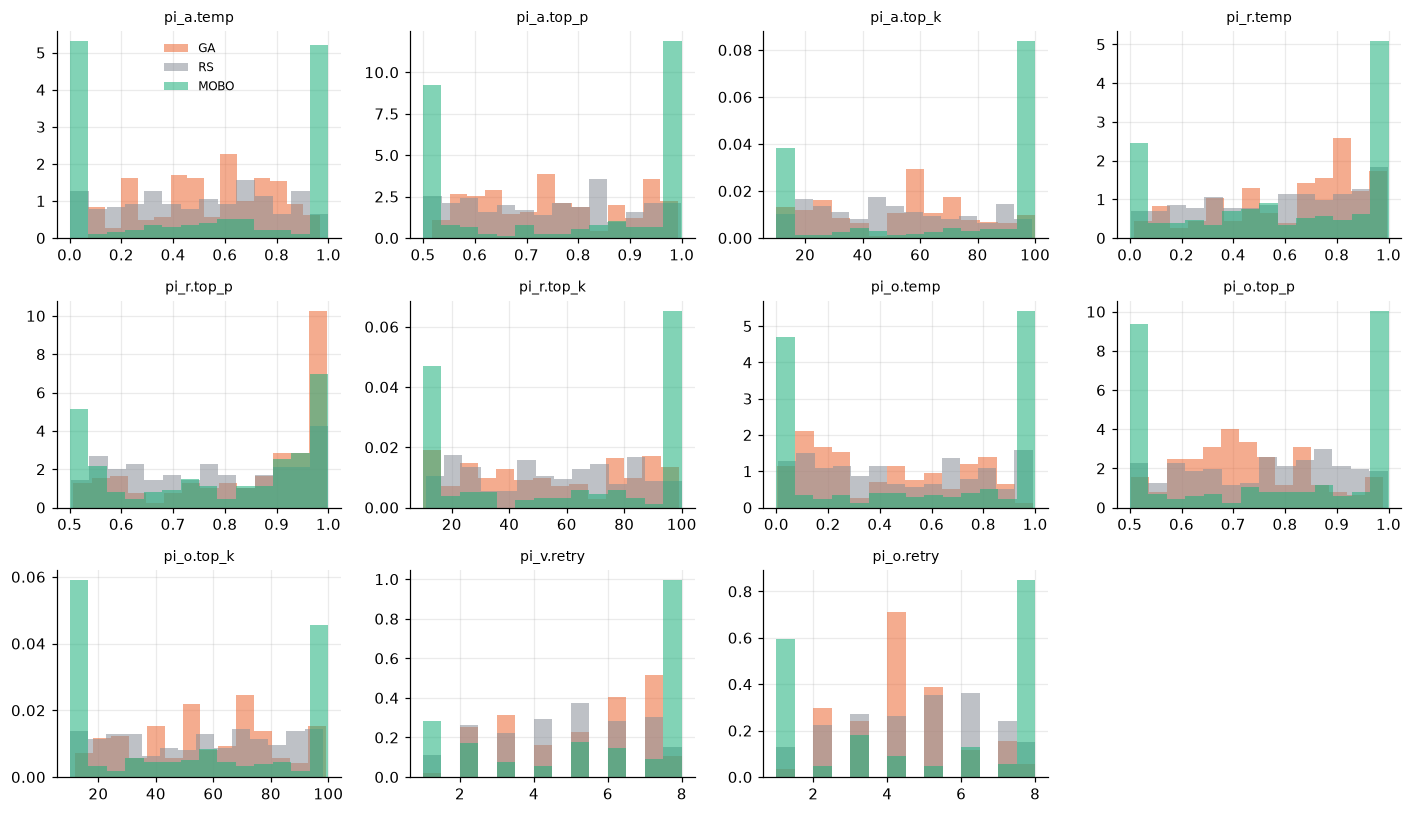

In [27]:
def vec(pol):
    return {
        "pi_a.temp": pol["pi_a"]["temperature"], "pi_a.top_p": pol["pi_a"]["top_p"],
        "pi_a.top_k": pol["pi_a"]["top_k"],
        "pi_r.temp": pol["pi_r"]["temperature"], "pi_r.top_p": pol["pi_r"]["top_p"],
        "pi_r.top_k": pol["pi_r"]["top_k"],
        "pi_o.temp": pol["pi_o"]["temperature"], "pi_o.top_p": pol["pi_o"]["top_p"],
        "pi_o.top_k": pol["pi_o"]["top_k"],
        "pi_v.retry": pol["pi_v"]["retry"], "pi_o.retry": pol["pi_o"]["retry"],
    }

b0 = list(BENCH)[0]
dims = list(vec(policies[b0]["GA"][0][0]["policy"]))
print(f"  marginal distributions on {b0} fronts (identical policies on the other benchmark)\n")
# Repetition indices are taken per arm rather than from an enclosing loop, so
# this table always covers every repetition each arm actually has.
DVEC = {a: {d: [vec(x["policy"])[d] for i in RP(b0, a) for x in policies[b0][a][i]]
            for d in dims} for a in ORDER}
print(f"  {'dimension':14s}" + "".join(f"{a+' mean':>10s}{a+' sd':>9s}" for a in ORDER)
      + "".join(f"{'p '+y+'-'+x:>11s}" for x, y in combinations(ORDER, 2)))
for d in dims:
    cells = "".join(f"{st.mean(DVEC[a][d]):10.3f}{st.stdev(DVEC[a][d]):9.3f}" for a in ORDER)
    ps = ""
    for x, y in combinations(ORDER, 2):
        _, pv = mannwhitneyu(DVEC[x][d], DVEC[y][d])
        ps += f"{pv:11.3g}"
    print(f"  {d:14s}{cells}{ps}")
print("\n  Policies within one repetition are not independent (§3), so these p-values")
print("  are anti-conservative; they describe the policies each arm retained, not")
print("  which decoding settings cause better outcomes.")

fig, axes = plt.subplots(3, 4, figsize=(13, 7.5))
for ax, d in zip(axes.ravel(), dims):
    for a in ORDER:
        v = [vec(x["policy"])[d] for i in RP(b0, a) for x in policies[b0][a][i]]
        ax.hist(v, bins=14, alpha=0.55, color=PALETTE[a], label=a, density=True)
    ax.set_title(d, fontsize=9)
for ax in axes.ravel()[len(dims):]:
    ax.axis("off")
axes.ravel()[0].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "policy_space"); plt.show()

## §12b · Anytime convergence on training fitness

All three arms have 750 rows per repetition. RS and MOBO publish every candidate
evaluation. GA publishes fifteen snapshots of the 50 surviving population
members, omitting rejected offspring; its rows are not a per-evaluation log.
Use checkpoints at multiples of 50 only.

The cumulative GA survivor archive is a subset of the evaluated archive, so its
**absolute** hypervolume is a lower bound. After division by each run's own final
hypervolume, the direction of bias in threshold times or AUC is unknown. Treat
GA comparisons as descriptive. RS versus MOBO has comparable logging.

MOBO begins with 50 random candidates and then uses acquisition-guided proposals.
The initial design is not a controlled estimate of acquisition benefit: stage,
budget and candidate sets also change.

Hypervolume here uses training fitness, including energy from the search host.
Reaching 90%, 95% or 99% of a run's **own** final HV does not mean reaching a common
absolute quality target or equal held-out quality. Training harmonic desirability
has weak rank transfer (quantified later); that is not a measured correlation
between training and held-out *set hypervolumes*.

In [28]:
# All three trajectory sources exist; their logging semantics differ.
TRAJ_SRC = {
    "GA":   ("results/nsga2/rep_{i}/intermediate_solutions.json", "ga"),
    "RS":   ("results/random_search/rep_{i}/evaluations_summary.json", "rs"),
    "MOBO": ("results/mobo/rep_{i}/intermediate_solutions.json", "ga"),
}
# MOBO shares the GA file's record schema (policy / fitness / feasible) but not
# its semantics: it is a true per-evaluation log of 750 distinct candidates,
# like RS. Only the GA file is a per-generation survivor snapshot.

def load_traj(arm, rep):
    tmpl, kind = TRAJ_SRC[arm]
    recs = json.loads((REPO / tmpl.format(i=rep)).read_text())
    if kind == "ga":
        return [(r["fitness"]["cl"], -r["fitness"]["correctness"], r["fitness"]["energy"],
                 bool(r.get("feasible", True))) for r in recs]
    return [(r["cl"], -r["correctness"], r["energy"], bool(r.get("feasible", True)))
            for r in recs]

def traj_reps(arm):
    tmpl, _ = TRAJ_SRC[arm]
    return [i for i in range(MAX_REPS) if (REPO / tmpl.format(i=i)).is_file()]

TRAJ_ARMS = [a for a in ORDER if a in TRAJ_SRC]
TRAJ = {(a, i): load_traj(a, i) for a in TRAJ_ARMS for i in traj_reps(a)}
# TRAJ_ARMS is already filtered to arms present in TRAJ_SRC, so the old check
# ("a for a in TRAJ_ARMS if a not in TRAJ_SRC") could never fire. Report the
# arms that are analysed elsewhere but publish no trajectory.
missing = [a for a in ORDER if a not in TRAJ_SRC]
if missing:
    print(f"  NOTE: no published search trajectory for {missing}. This section is a "
          f"{len(TRAJ_ARMS)}-arm\n        comparison ({', '.join(TRAJ_ARMS)}) and excludes "
          f"{', '.join(missing)} entirely --\n        an artefact limitation, not a null result.")
assert all(tuple(traj_reps(a)) == EXPECTED_REPS for a in TRAJ_ARMS)
n_eval = {len(v) for v in TRAJ.values()}
assert n_eval == {750}
print(f"  trajectories loaded: {len(TRAJ)} runs, {n_eval} evaluations each")

# One normalisation across every candidate any arm ever evaluated, so the
# anytime curves of the two arms are on a common scale.
_all = np.array([[c, k, e] for v in TRAJ.values() for (c, k, e, f) in v
                 if f and all(np.isfinite([c, k, e]))], float)
T_IDEAL, T_NADIR = _all.min(0), _all.max(0)
T_SPAN = np.where(T_NADIR - T_IDEAL == 0, 1.0, T_NADIR - T_IDEAL)
T_REF = np.full(3, REF_MARGIN)

# GA's trajectory file is 15 snapshots of the surviving 50-member population,
# not 750 sequential evaluations: across the 750 rows only ~184-204 policy
# vectors are distinct, and row order within a generation is not evaluation
# order. Generation g corresponds to 50*g evaluations consumed, so a checkpoint
# is a real algorithm state only at multiples of 50. STEP was 25, which put half
# the checkpoints mid-generation where the partial archive never existed.
# (Recomputing at boundaries moves the headline GA/RS ratio from 2.46x to 2.40x,
# so this corrects the axis rather than the conclusion.)
STEP = 50
CHECK = list(range(STEP, 751, STEP))

def anytime(arm, rep):
    #  HV of the cumulative feasible archive at each checkpoint
    pts, out, arch = TRAJ[(arm, rep)], [], []
    for k, (c, kk, e, f) in enumerate(pts, start=1):
        if f and all(np.isfinite([c, kk, e])):
            arch.append([c, kk, e])
        if k in CHECK:
            if not arch:
                out.append(0.0); continue
            F = (np.array(arch, float) - T_IDEAL) / T_SPAN
            out.append(hv(F, T_REF))
    return np.array(out)

CURVES = {(a, i): anytime(a, i) for a in TRAJ_ARMS for i in traj_reps(a)}
print("  anytime curves computed at", len(CHECK), "checkpoints")

  trajectories loaded: 15 runs, {750} evaluations each


  anytime curves computed at 15 checkpoints


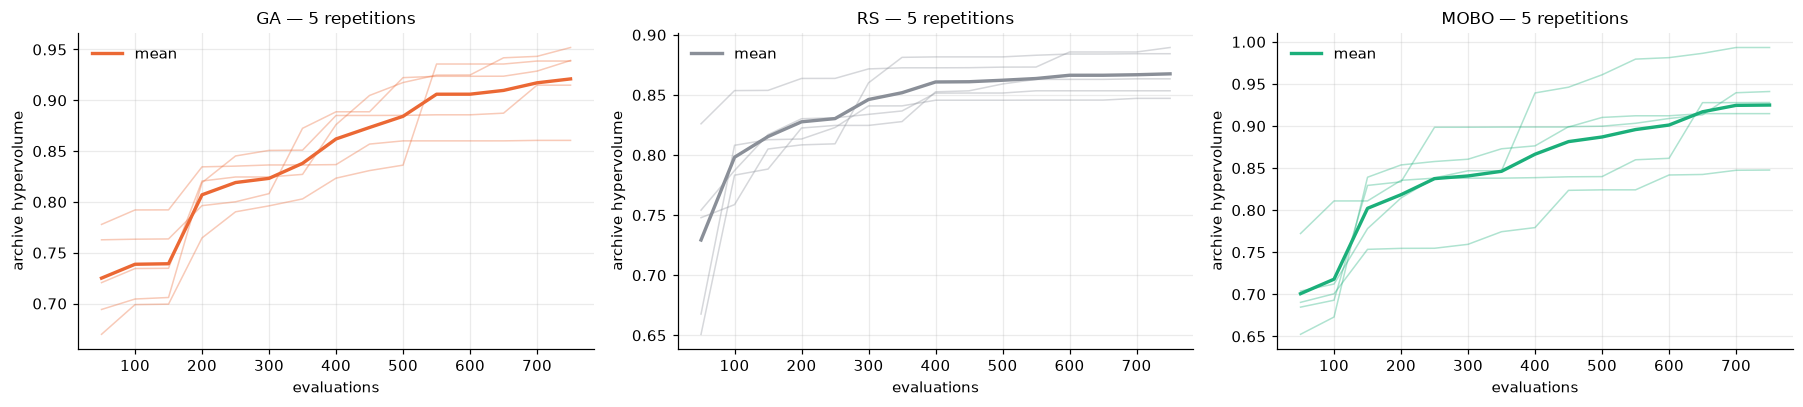

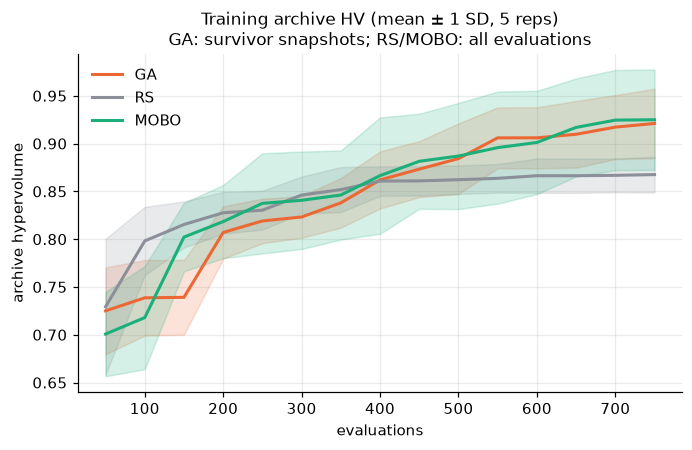

In [29]:
fig, axes = plt.subplots(1, len(TRAJ_ARMS), figsize=(5.5 * len(TRAJ_ARMS), 3.8))
for ax, (a, ttl) in zip(np.atleast_1d(axes), [(a, f"{a} — {len(traj_reps(a))} repetitions") for a in TRAJ_ARMS]):
    for i in traj_reps(a):
        ax.plot(CHECK, CURVES[(a, i)], color=PALETTE[a], alpha=0.35, lw=1)
    M = np.vstack([CURVES[(a, i)] for i in traj_reps(a)])
    ax.plot(CHECK, M.mean(0), color=PALETTE[a], lw=2.2, label="mean")
    ax.set_title(ttl); ax.set_xlabel("evaluations"); ax.set_ylabel("archive hypervolume")
    ax.legend()
fig.tight_layout(); savefig(fig, "anytime_per_arm"); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for a in TRAJ_ARMS:
    M = np.vstack([CURVES[(a, i)] for i in traj_reps(a)])
    m, sd = M.mean(0), M.std(0, ddof=1)
    ax.plot(CHECK, m, color=PALETTE[a], lw=2, label=a)
    ax.fill_between(CHECK, m - sd, m + sd, color=PALETTE[a], alpha=0.18)
ax.set_xlabel("evaluations"); ax.set_ylabel("archive hypervolume")
ax.set_title(f"Training archive HV (mean ± 1 SD, "
             f"{min(len(traj_reps(a)) for a in TRAJ_ARMS)} reps)\nGA: survivor snapshots; RS/MOBO: all evaluations"); ax.legend()
fig.tight_layout(); savefig(fig, "anytime_compare"); plt.show()

### §12b-i · Evaluations to reach a fraction of final quality

The headline number: how much of the budget each arm needed to reach 90%, 95%
and 99% of the hypervolume it eventually attained. Each run is normalised to its
**own** final value, so this measures speed of convergence and not final
quality — an arm that converges quickly to a poor front scores well here, which
is why it is read alongside §2 rather than instead of it.

In [30]:
FRACS = [0.90, 0.95, 0.99]
reach = {}
print(f"  {'arm':5s}{'rep':>4s}" + "".join(f"{int(f*100):>8d}%" for f in FRACS) + f"{'final HV':>11s}")
for a in TRAJ_ARMS:
    for i in traj_reps(a):
        c = CURVES[(a, i)]; fin = c[-1]
        row = []
        for f in FRACS:
            hit = next((CHECK[k] for k, v in enumerate(c) if v >= f * fin), CHECK[-1])
            row.append(hit)
        reach[(a, i)] = row
        print(f"  {a:5s}{i:4d}" + "".join(f"{v:9d}" for v in row) + f"{fin:11.4f}")

print(f"\n  {'arm':5s}" + "".join(f"{int(f*100):>10d}%" for f in FRACS))
for a in TRAJ_ARMS:
    R = np.array([reach[(a, i)] for i in traj_reps(a)], float)
    print(f"  {a:5s}" + "".join(f"{R[:,k].mean():7.0f}±{R[:,k].std(ddof=1):<3.0f}" for k in range(len(FRACS))))
print()
# Repetition indices are taken per arm. Reusing one arm's index set for both
# is correct only while every arm has the same repetition count.
for k, f in enumerate(FRACS):
    print(f"  to {int(f*100)}% of own final HV:")
    for x, y in combinations(TRAJ_ARMS, 2):
        vx = [reach[(x, i)][k] for i in traj_reps(x)]
        vy = [reach[(y, i)][k] for i in traj_reps(y)]
        pv, pv_w, _ = between(vx, vy)
        faster = y if st.mean(vy) < st.mean(vx) else x
        clean = "" if "GA" in (x, y) else "  <- like-for-like"
        print(f"      {x} {st.mean(vx):4.0f} vs {y} {st.mean(vy):4.0f} evals"
              f"   -> {faster} faster by {abs(st.mean(vx)-st.mean(vy)):3.0f}   "
              f"MWU p={pv:<8.3g} [Welch {pv_w:.3g}]{clean}")

  arm   rep      90%      95%      99%   final HV
  GA      0      250      400      700     0.9149
  GA      1      350      500      750     0.9392
  GA      2      400      450      700     0.9520
  GA      3       50      200      450     0.8606
  GA      4      550      550      550     0.9386
  RS      0       50      100      600     0.8895
  RS      1      150      300      350     0.8843
  RS      2      100      200      500     0.8634
  RS      3      100      150      400     0.8534
  RS      4      100      100      300     0.8471
  MOBO    0      150      250      500     0.9147
  MOBO    1      200      450      700     0.9410
  MOBO    2      400      450      650     0.9933
  MOBO    3      350      450      600     0.8477
  MOBO    4      200      650      650     0.9279

  arm          90%        95%        99%
  GA       320±186    420±135    630±125
  RS       100±35     170±84     430±120
  MOBO     260±108    450±141    620±76 

  to 90% of own final HV:
      GA

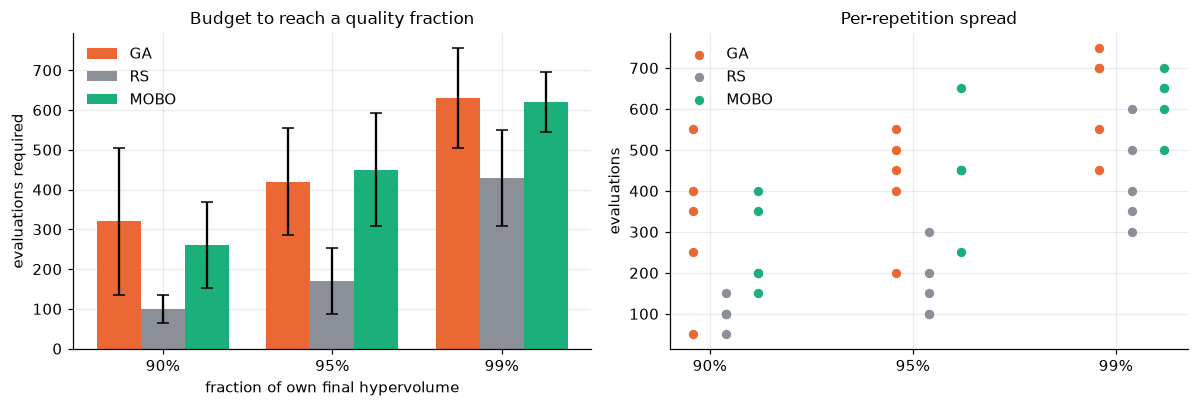

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
w = 0.26
ax = axes[0]
for k, a in enumerate(TRAJ_ARMS):
    R = np.array([reach[(a, i)] for i in traj_reps(a)], float)
    ax.bar(np.arange(len(FRACS)) + (k - (len(TRAJ_ARMS) - 1) / 2) * w, R.mean(0), w,
           yerr=R.std(0, ddof=1), capsize=4, color=PALETTE[a], label=a)
ax.set_xticks(range(len(FRACS)))
ax.set_xticklabels([f"{int(f*100)}%" for f in FRACS])
ax.set_ylabel("evaluations required"); ax.set_xlabel("fraction of own final hypervolume")
ax.set_title("Budget to reach a quality fraction"); ax.legend()

ax = axes[1]
for k, a in enumerate(TRAJ_ARMS):
    for j, f in enumerate(FRACS):
        v = [reach[(a, i)][j] for i in traj_reps(a)]
        ax.scatter([j + (k - 0.5) * 0.16] * len(v), v, color=PALETTE[a], s=26,
                   label=a if j == 0 else None)
ax.set_xticks(range(len(FRACS)))
ax.set_xticklabels([f"{int(f*100)}%" for f in FRACS])
ax.set_ylabel("evaluations"); ax.set_title("Per-repetition spread"); ax.legend()
fig.tight_layout(); savefig(fig, "evals_to_reach"); plt.show()

### §12b-ii · Area under the anytime curve and the plateau point

AUC normalised by the final value and by budget summarises the whole trajectory
in one scalar: it rewards reaching a given level early, and equals 1.0 only for a
search that has already attained its final quality by the first checkpoint.
That checkpoint is evaluation 50, so any search converging within the first 50
evaluations scores the same maximum; the measure cannot resolve below one
generation.

The plateau is the first checkpoint after which the archive hypervolume never
again improves by more than a threshold, expressed as a fraction of the final
value. The threshold applies to each individual step, so "plateau" means no
single later checkpoint gained more than 0.5% -- it does **not** mean the
remaining budget was worthless, since many sub-threshold gains can accumulate to
something substantial. It locates the last above-threshold checkpoint gain retrospectively. It is
not a validated stopping rule or a measure of surplus budget.

In [32]:
PLATEAU_TOL = 0.005
print(f"  {'arm':5s}{'rep':>4s}{'norm AUC':>11s}{'plateau eval':>14s}{'budget after plateau':>22s}")
auc, plat = {}, {}
for a in TRAJ_ARMS:
    for i in traj_reps(a):
        c = CURVES[(a, i)]; fin = c[-1]
        _trap = getattr(np, "trapezoid", None) or np.trapz   # np.trapz removed in numpy 2
        A = float(_trap(c, CHECK) / (fin * (CHECK[-1] - CHECK[0])))
        gains = np.diff(c) / fin
        idx = 0  # no above-threshold gain: plateau begins at the first checkpoint
        for k in range(len(gains) - 1, -1, -1):
            if gains[k] > PLATEAU_TOL:
                idx = k + 1; break
        pe = CHECK[min(idx, len(CHECK) - 1)]
        auc[(a, i)], plat[(a, i)] = A, pe
        print(f"  {a:5s}{i:4d}{A:11.4f}{pe:14d}{CHECK[-1]-pe:20d}  ({100*(CHECK[-1]-pe)/CHECK[-1]:.0f}%)")
print()
for a in TRAJ_ARMS:
    A = [auc[(a, i)] for i in traj_reps(a)]; P = [plat[(a, i)] for i in traj_reps(a)]
    print(f"  {a:5s} AUC {st.mean(A):.4f} ± {st.stdev(A):.4f}    plateau {st.mean(P):.0f} ± {st.stdev(P):.0f} evaluations")
print()
for x, y in combinations(TRAJ_ARMS, 2):
    p_auc, p_auc_w, _ = between([auc[(x, i)] for i in traj_reps(x)],
                                [auc[(y, i)] for i in traj_reps(y)])
    p_pl, p_pl_w, _ = between([plat[(x, i)] for i in traj_reps(x)],
                              [plat[(y, i)] for i in traj_reps(y)])
    clean = "" if "GA" in (x, y) else "   <- like-for-like per-evaluation logs"
    print(f"  {x} vs {y:5s} AUC MWU p={p_auc:<8.3g} [Welch {p_auc_w:<8.3g}]  "
          f"plateau MWU p={p_pl:<8.3g} [Welch {p_pl_w:.3g}]{clean}")
print(f"\n  exact two-sided MWU minimum at n=5 vs 5 is {2/252:.4f}.")
print("  Contrasts involving GA compare a survivor-only archive against a full")
print("  per-evaluation archive; bias direction after self-final normalisation is unknown.")

# Correct the five anytime outcomes together within each pair of arms.
ANYTIME_TESTS = {}
for x, y in combinations(TRAJ_ARMS, 2):
    series = [(f"reach_{int(f*100)}", [reach[(x,i)][k] for i in traj_reps(x)],
               [reach[(y,i)][k] for i in traj_reps(y)]) for k,f in enumerate(FRACS)]
    series += [("auc", [auc[(x,i)] for i in traj_reps(x)], [auc[(y,i)] for i in traj_reps(y)]),
               ("plateau", [plat[(x,i)] for i in traj_reps(x)], [plat[(y,i)] for i in traj_reps(y)])]
    ps = [between(vx,vy)[0] for _,vx,vy in series]
    for (name,vx,vy), pv, pa in zip(series,ps,holm_adjust(ps)):
        ANYTIME_TESTS[(x,y,name)] = dict(p=pv, p_holm=pa)
        print(f"  {x} vs {y} {name}: nominal p={pv:.5f}, Holm(5) p={pa:.5f}")

  arm   rep   norm AUC  plateau eval  budget after plateau
  GA      0     0.9220           700                  50  (7%)
  GA      1     0.9168           750                   0  (0%)
  GA      2     0.9030           750                   0  (0%)
  GA      3     0.9745           450                 300  (40%)
  GA      4     0.8822           550                 200  (27%)
  RS      0     0.9786           600                 150  (20%)
  RS      1     0.9628           350                 400  (53%)
  RS      2     0.9634           500                 250  (33%)
  RS      3     0.9799           400                 350  (47%)
  RS      4     0.9795           400                 350  (47%)
  MOBO    0     0.9537           500                 250  (33%)
  MOBO    1     0.9180           700                  50  (7%)
  MOBO    2     0.8969           700                  50  (7%)
  MOBO    3     0.9310           700                  50  (7%)
  MOBO    4     0.9173           650               

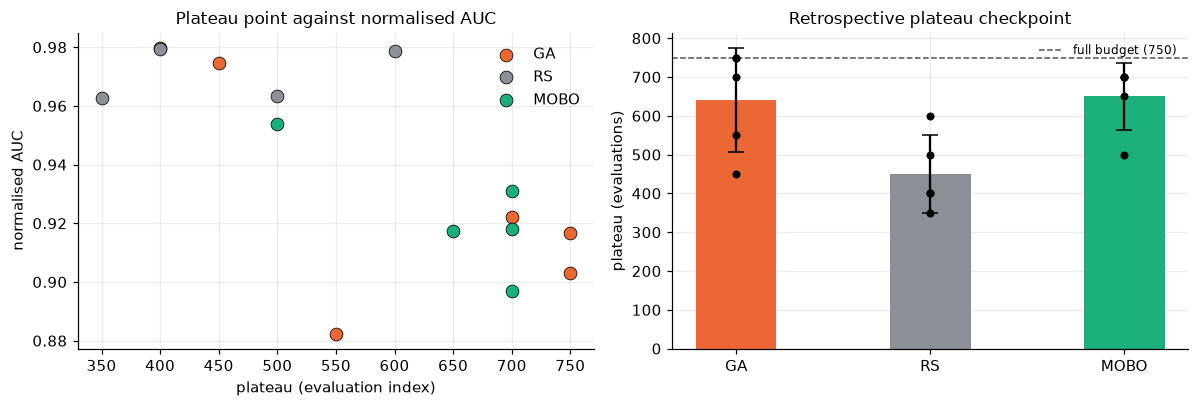

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for a in TRAJ_ARMS:
    ax.scatter([plat[(a, i)] for i in traj_reps(a)], [auc[(a, i)] for i in traj_reps(a)],
               color=PALETTE[a], s=70, label=a, edgecolor="black", linewidth=0.5)
ax.set_xlabel("plateau (evaluation index)"); ax.set_ylabel("normalised AUC")
ax.set_title("Plateau point against normalised AUC"); ax.legend()

ax = axes[1]
w = 0.26
for k, a in enumerate(TRAJ_ARMS):
    P = [plat[(a, i)] for i in traj_reps(a)]
    ax.bar(k, st.mean(P), w * 1.6, yerr=st.stdev(P), capsize=5, color=PALETTE[a])
    ax.scatter([k] * len(P), P, color="black", s=18, zorder=3)
ax.axhline(CHECK[-1], color="#555", ls="--", lw=1, label="full budget (750)")
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER)
ax.set_ylabel("plateau (evaluations)"); ax.set_title("Retrospective plateau checkpoint"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "auc_plateau"); plt.show()

#### Interpretation

Earlier self-normalised convergence indicates faster attainment of a fraction of
observed training HV. Non-significant final held-out differences do not establish
equal outcomes, so these curves do not demonstrate cost dominance or justify
cutting the search budget without loss. A validated stopping policy needs new
runs, held-out evaluation at candidate stopping points and measured end-to-end
cost. For RS–MOBO, report the five-outcome correction printed above.

## §12c · Exploratory held-out oracle selection

Four rules select **one policy per repetition using held-out outcomes**. This is
an oracle diagnostic with selection on the reported outcome, not a deployable or
independently validated improvement. Normalisation uses the benchmark-wide union.

Harmonic desirability uses equal objective weights and penalises a poor component.
Ideal distance uses equally weighted normalised Euclidean distance. Hyperplane
selection uses the plane through objective extremes, falling back to ideal
distance if singular. Trade-off ratio compares sums of normalised gains and
losses on the non-dominated set. All embed scaling or geometric assumptions;
agreement does not make them preference-free.

The training-based **top-five shortlist** in §12d is a different analysis, with
normalisation within each repetition's front. Do not transfer oracle agreement
counts or baseline tests to that operational analysis. Oracle p-values below are
uncorrected diagnostics conditional on selection, not confirmatory tests.

In [34]:
def _nd(A):
    return [i for i in range(len(A))
            if not any(np.all(A[j] <= A[i]) and np.any(A[j] < A[i])
                       for j in range(len(A)) if j != i)]

def tradeoff_mu(P):
    m = len(P); mu = np.zeros(m)
    for i in range(m):
        best = np.inf
        for j in range(m):
            if i == j: continue
            gain = float(np.sum(np.maximum(P[j] - P[i], 0)))
            loss = float(np.sum(np.maximum(P[i] - P[j], 0)))
            if loss > 0: best = min(best, gain / loss)
        mu[i] = best if np.isfinite(best) else 0.0
    return mu

def select(N, rule):
    #  N: normalised objective matrix, minimisation, 0 = union ideal.
    #  Returns the row index of the selected policy.
    nd = _nd(N); P = N[nd]
    if rule == "harmonic":
        d = np.clip(1.0 - N, 1e-6, 1.0)
        return int(np.argmax(3.0 / np.sum(1.0 / d, axis=1)))
    if rule == "ideal":
        return nd[int(np.argmin(np.linalg.norm(P, axis=1)))]
    if rule == "hyperplane":
        ext = [int(np.argmin(P[:, k])) for k in range(P.shape[1])]
        A = P[ext]
        try:
            nrm = np.linalg.solve(A, np.ones(P.shape[1]))
        except np.linalg.LinAlgError:
            return nd[int(np.argmin(np.linalg.norm(P, axis=1)))]
        nrm = nrm / np.linalg.norm(nrm)
        return nd[int(np.argmin(P @ nrm - A[0] @ nrm))]
    if rule == "tradeoff":
        return nd[int(np.argmax(tradeoff_mu(P)))]
    raise ValueError(rule)

RULES = ["harmonic", "ideal", "hyperplane", "tradeoff"]
SEL = {}
for b in BENCH:
    ideal_b, span_b = norm[b]
    for a in ORDER:
        for i in RP(b, a):
            recs = [x for x in policies[b][a][i]
                    if all(isinstance(x[k], (int, float)) and np.isfinite(x[k])
                           for k in ("mean_cl", "mean_correctness", "mean_energy"))]
            F = np.array([[x["mean_cl"], -x["mean_correctness"], x["mean_energy"]] for x in recs], float)
            N = (F - ideal_b) / span_b
            for r in RULES:
                k = select(N, r)
                SEL[(b, a, i, r)] = recs[k]
print(f"  selections made: {len(SEL)}  ({len(BENCH)} benchmarks x {len(ORDER)} arms x 5 reps x {len(RULES)} rules)")

  selections made: 120  (2 benchmarks x 3 arms x 5 reps x 4 rules)


In [35]:
print("  HELD-OUT ORACLE: outcome-selected, nominal p-values are diagnostic only")

for b in BENCH:
    bs = baseline[b]["summary"]
    bm = {k: bs[k]["mean"] for k in ("mean_cl", "mean_correctness", "mean_energy")}
    bsd = {k: bs[k]["std"] for k in ("mean_cl", "mean_correctness", "mean_energy")}
    print(f"\n  {b}")
    print(f"    baseline  F1 {bm['mean_cl']:.4f}  F2 {bm['mean_correctness']:.4f}  F3 {bm['mean_energy']:.2f}")
    print(f"    {'rule':12s}{'arm':5s}{'F1':>9s}{'F2':>9s}{'F3':>9s}"
          f"{'F2 vs base':>12s}{'in sd':>8s}{'MWU p':>10s}")
    for r in RULES:
        for a in ORDER:
            v = [SEL[(b, a, i, r)] for i in RP(b, a)]
            f1 = [x["mean_cl"] for x in v]; f2 = [x["mean_correctness"] for x in v]
            f3 = [x["mean_energy"] for x in v]
            base_f2 = [rep["mean_correctness"] for rep in baseline[b]["reps"]]
            p, _, _ = between(f2, base_f2)
            g = st.mean(f2) - bm["mean_correctness"]
            print(f"    {r:12s}{a:5s}{st.mean(f1):9.4f}{st.mean(f2):9.4f}{st.mean(f3):9.2f}"
                  f"{g:+12.4f}{g/bsd['mean_correctness']:+8.2f}{p:10.3g}")

  HELD-OUT ORACLE: outcome-selected, nominal p-values are diagnostic only

  Codeflaws (C)
    baseline  F1 9.2595  F2 0.4580  F3 35.56
    rule        arm         F1       F2       F3  F2 vs base   in sd     MWU p
    harmonic    GA      8.1484   0.4682    30.48     +0.0101   +0.42      0.69
    harmonic    RS      8.3570   0.5030    31.27     +0.0450   +1.85    0.0159
    harmonic    MOBO    7.9466   0.4695    35.13     +0.0114   +0.47         1
    ideal       GA      8.1484   0.4682    30.48     +0.0101   +0.42      0.69
    ideal       RS      8.3570   0.5030    31.27     +0.0450   +1.85    0.0159
    ideal       MOBO    7.9781   0.4739    37.61     +0.0159   +0.65      0.69
    hyperplane  GA      8.6277   0.4851    28.11     +0.0270   +1.11     0.421
    hyperplane  RS      8.3781   0.4635    27.60     +0.0054   +0.22      0.69
    hyperplane  MOBO    8.0837   0.4573    27.19     -0.0008   -0.03     0.548
    tradeoff    GA      8.1484   0.4682    30.48     +0.0101   +0.42      

### §12c-i · Concordance between held-out oracle rules

Exact equality of the selected policy vectors describes agreement on these
held-out fronts. Different rules can agree here while embodying different
preferences or disagreeing on training data. Training top-five agreement is
computed separately in §12d.

In [36]:
def sig(x):
    return json.dumps(x["policy"], sort_keys=True)

N_CELLS = sum(len(RP(b, a)) for b in BENCH for a in ORDER)
ORACLE_AGREEMENT = {}
print(f"  pairwise agreement, fraction of the {N_CELLS} (benchmark, arm, rep) cells")
for r1, r2 in combinations(RULES, 2):
    same = sum(1 for b in BENCH for a in ORDER for i in RP(b, a)
               if sig(SEL[(b, a, i, r1)]) == sig(SEL[(b, a, i, r2)]))
    ORACLE_AGREEMENT[(r1,r2)] = same
    tot = N_CELLS
    print(f"    {r1:11s} vs {r2:11s}  {same:2d}/{tot}  ({100*same/tot:3.0f}%)")

print("\n  what each rule tends to buy, averaged over both benchmarks and arms")
print(f"    {'rule':12s}{'F1 rank':>9s}{'F2 rank':>9s}{'F3 rank':>9s}   (1 = best of the four rules)")
means = {}
for r in RULES:
    means[r] = {}
    for key, better in (("mean_cl", "lo"), ("mean_correctness", "hi"), ("mean_energy", "lo")):
        vals = []
        for b in BENCH:
            ideal_b, span_b = norm[b]
            k = {"mean_cl": 0, "mean_correctness": 1, "mean_energy": 2}[key]
            for a in ORDER:
                for i in RP(b, a):
                    x = SEL[(b, a, i, r)][key]
                    lo, sp = ideal_b[k], span_b[k]
                    v = ((-x) - lo) / sp if key == "mean_correctness" else (x - lo) / sp
                    vals.append(v)          # normalised, lower always better
        means[r][key] = st.mean(vals)
for r in RULES:
    ranks = []
    for key in ("mean_cl", "mean_correctness", "mean_energy"):
        order_ = sorted(RULES, key=lambda q: means[q][key])
        ranks.append(order_.index(r) + 1)
    print(f"    {r:12s}{ranks[0]:9d}{ranks[1]:9d}{ranks[2]:9d}")

  pairwise agreement, fraction of the 30 (benchmark, arm, rep) cells
    harmonic    vs ideal        29/30  ( 97%)
    harmonic    vs hyperplane   11/30  ( 37%)
    harmonic    vs tradeoff     26/30  ( 87%)
    ideal       vs hyperplane   10/30  ( 33%)
    ideal       vs tradeoff     25/30  ( 83%)
    hyperplane  vs tradeoff     12/30  ( 40%)

  what each rule tends to buy, averaged over both benchmarks and arms
    rule          F1 rank  F2 rank  F3 rank   (1 = best of the four rules)
    harmonic            2        2        2
    ideal               3        1        3
    hyperplane          4        4        4
    tradeoff            1        3        1


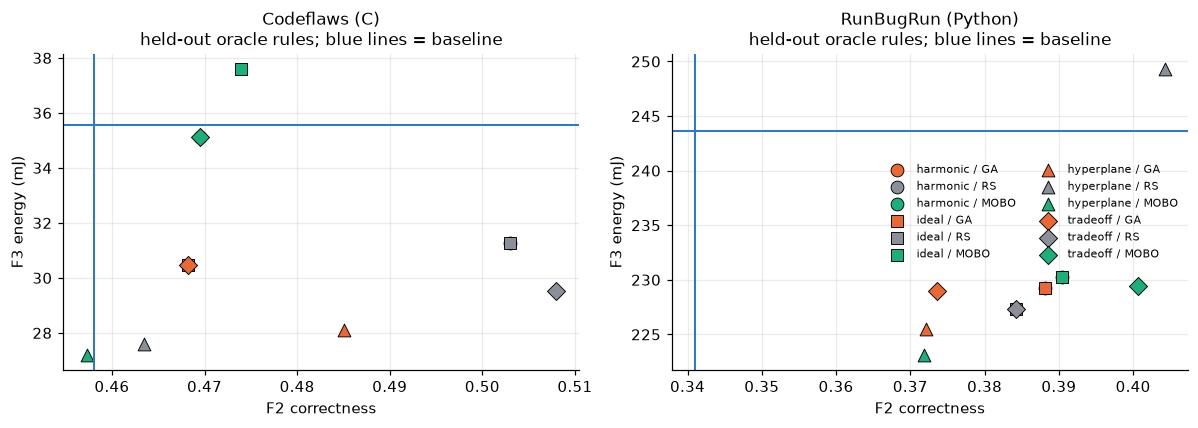

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
for ax, b in zip(axes, BENCH):
    bs = baseline[b]["summary"]
    xs, ys, cs, ms = [], [], [], []
    for r, mk in zip(RULES, ["o", "s", "^", "D"]):
        for a in ORDER:
            v = [SEL[(b, a, i, r)] for i in RP(b, a)]
            ax.scatter([st.mean([x["mean_correctness"] for x in v])],
                       [st.mean([x["mean_energy"] for x in v])],
                       marker=mk, s=70, color=PALETTE[a],
                       edgecolor="black", linewidth=0.6,
                       label=f"{r} / {a}")
    ax.axvline(bs["mean_correctness"]["mean"], color=C_BASE, lw=1.3)
    ax.axhline(bs["mean_energy"]["mean"], color=C_BASE, lw=1.3)
    ax.set_xlabel("F2 correctness"); ax.set_ylabel("F3 energy (mJ)")
    ax.set_title(f"{b}\nheld-out oracle rules; blue lines = baseline")
axes[1].legend(fontsize=7, ncol=2, loc="best")
fig.tight_layout(); savefig(fig, "selection_rules"); plt.show()

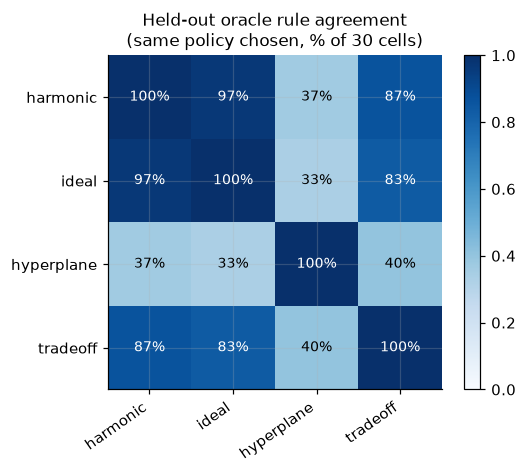

In [38]:
M = np.zeros((len(RULES), len(RULES)))
tot = N_CELLS
for i1, r1 in enumerate(RULES):
    for i2, r2 in enumerate(RULES):
        M[i1, i2] = sum(1 for b in BENCH for a in ORDER for i in RP(b, a)
                        if sig(SEL[(b, a, i, r1)]) == sig(SEL[(b, a, i, r2)])) / tot
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(M, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(RULES))); ax.set_xticklabels(RULES, rotation=35, ha="right")
ax.set_yticks(range(len(RULES))); ax.set_yticklabels(RULES)
for i1 in range(len(RULES)):
    for i2 in range(len(RULES)):
        ax.text(i2, i1, f"{100*M[i1,i2]:.0f}%", ha="center", va="center",
                color="white" if M[i1, i2] > 0.55 else "black", fontsize=9)
ax.set_title(f"Held-out oracle rule agreement\n(same policy chosen, % of {N_CELLS} cells)")
fig.colorbar(im, ax=ax, fraction=0.045)
fig.tight_layout(); savefig(fig, "rule_agreement"); plt.show()

#### Interpretation

Agreement is equality of the exact policy vectors selected by the held-out oracle.
It does not remove preferences, establish identical training shortlists or reduce
the multiplicity of evaluating several selection rules. Training top-five
agreement is calculated separately below.

## §12d · Selection basis under operational constraints

Section 12c compared selection *rules* using held-out values. That does not provide an independent evaluation: choosing by held-out performance and then
reporting held-out performance is selection on the outcome. A deployable rule
must rank policies using information available at selection time, which is the
**training** fitness the search itself recorded.

This section repeats the comparison on both bases and adds a fifth rule,
**correctness only** — rank by F2 alone and ignore the other two objectives.
Feasibility (problems of 100 with correctness > 0) is reported alongside the
three objectives. It was never an objective; it is a constraint, and is mechanically linked to the optimised F2.

Feasibility and F2 are **not independent**: F2 averages correctness over all 100
problems, so an infeasible problem contributes zero and making a problem feasible
raises F2 mechanically. They are reported together because the pair distinguishes
*obtaining any passing test on more records* from *passing a larger fraction of tests*, not because they
are two pieces of evidence.

In [39]:
def _norm_min(M):
    lo, hi = M.min(0), M.max(0)
    return (M - lo) / np.where(hi - lo == 0, 1.0, hi - lo)

def rank_by(M, rule):
    # M is a minimisation matrix (F1, -F2, F3). Returns indices, best first.
    N = _norm_min(M)
    if rule == "correctness only":
        return np.argsort(N[:, 1])
    if rule == "harmonic":
        d = np.clip(1.0 - N, 1e-6, 1.0)
        return np.argsort(-(3.0 / np.sum(1.0 / d, axis=1)))
    if rule == "dist-to-ideal":
        return np.argsort(np.linalg.norm(N, axis=1))
    nd = _nd(N); P = N[nd]
    fallback = np.argsort(np.linalg.norm(N, axis=1))
    if rule == "hyperplane":
        ext = [int(np.argmin(P[:, k])) for k in range(P.shape[1])]
        A = P[ext]
        try:
            nv = np.linalg.solve(A, np.ones(P.shape[1])); nv /= np.linalg.norm(nv)
        except np.linalg.LinAlgError:
            return fallback
        o = np.argsort(P @ nv - A[0] @ nv)
    elif rule == "tradeoff-knee":
        o = np.argsort(-tradeoff_mu(P))
    else:
        raise ValueError(rule)
    head = [nd[i] for i in o]
    return np.array(head + [i for i in fallback if i not in set(head)])

RULES2 = ["correctness only", "harmonic", "dist-to-ideal", "hyperplane", "tradeoff-knee"]
KSEL = 5
OUTCOMES = [("F1", "lo"), ("F2", "hi"), ("F3", "lo"), ("feasible", "hi")]

def _mats(b, a, i):
    R = [x for x in policies[b][a][i] if x.get("train_fitness")]
    H = np.array([[x["mean_cl"], -x["mean_correctness"], x["mean_energy"]] for x in R], float)
    T = np.array([[x["train_fitness"]["cl"], -x["train_fitness"]["correctness"],
                   x["train_fitness"]["energy"]] for x in R], float)
    g = np.all(np.isfinite(T), axis=1) & np.all(np.isfinite(H), axis=1)
    return [r for r, q in zip(R, g) if q], H[g], T[g]

SELMAT = {}     # (bench, arm, basis, rule) -> array (5 reps, 4 outcomes)
for b in BENCH:
    for a in ORDER:
        for basis in ("training", "held-out"):
            for rule in RULES2:
                rows = []
                for i in RP(b, a):
                    R, H, T = _mats(b, a, i)
                    idx = rank_by(T if basis == "training" else H, rule)[:KSEL]
                    rows.append([H[idx][:, 0].mean(), -H[idx][:, 1].mean(),
                                 H[idx][:, 2].mean(),
                                 st.mean([R[j]["n_feasible"] for j in idx])])
                SELMAT[(b, a, basis, rule)] = np.array(rows)
print(f"  selections computed: {len(SELMAT)} "
      f"({len(BENCH)} benchmarks x {len(ORDER)} arms x 2 bases x {len(RULES2)} rules)")

  selections computed: 60 (2 benchmarks x 3 arms x 2 bases x 5 rules)


### §12d-i · Overlap between training-selected and held-out-selected sets

If the training ranking carried the signal, the five policies chosen on training
fitness would substantially overlap the five best on held-out data. The overlap
is compared against the hypergeometric expectation for choosing five at random.

  benchmark             arm   rep  front  overlap  chance  rho(H_train, H_heldout)
  Codeflaws (C)         GA      0     38        0    0.66                   -0.315
  Codeflaws (C)         GA      1     45        0    0.56                   -0.012
  Codeflaws (C)         GA      2     50        0    0.50                   +0.064
  Codeflaws (C)         GA      3     46        0    0.54                   -0.063
  Codeflaws (C)         GA      4     43        1    0.58                   -0.135
  Codeflaws (C)         RS      0     34        1    0.74                   -0.060
  Codeflaws (C)         RS      1     44        1    0.57                   -0.078
  Codeflaws (C)         RS      2     33        1    0.76                   +0.053
  Codeflaws (C)         RS      3     42        1    0.60                   +0.129
  Codeflaws (C)         RS      4     45        1    0.56                   +0.124
  Codeflaws (C)         MOBO    0     48        0    0.52                   +0.386
  Co

  training top-five correctness only vs tradeoff-knee: identical 0/30, mean overlap 0.533/5
  training top-five harmonic vs dist-to-ideal: identical 16/30, mean overlap 4.467/5
  training top-five harmonic vs hyperplane: identical 0/30, mean overlap 2.000/5


  training top-five harmonic vs tradeoff-knee: identical 0/30, mean overlap 2.133/5
  training top-five dist-to-ideal vs hyperplane: identical 0/30, mean overlap 1.933/5


  training top-five dist-to-ideal vs tradeoff-knee: identical 0/30, mean overlap 2.200/5


  training top-five hyperplane vs tradeoff-knee: identical 0/30, mean overlap 2.267/5
  Training selections repeat across the two benchmarks: 30 cells represent 15 distinct fronts.


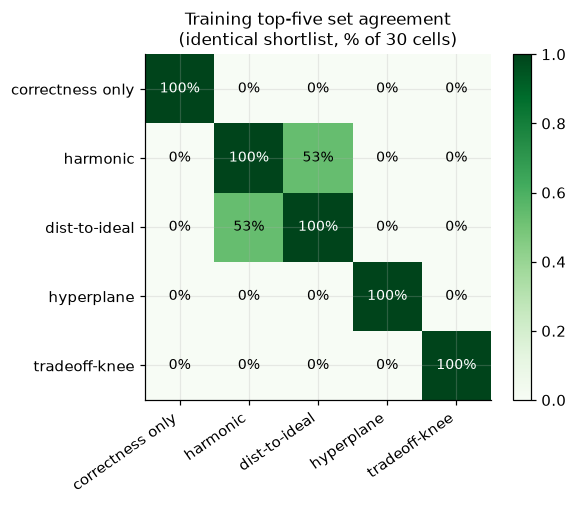

  Codeflaws (C) GA: training-harmonic F2 at 22.80th percentile of random-shortlist repetition-mean F2
  Codeflaws (C) RS: training-harmonic F2 at 15.15th percentile of random-shortlist repetition-mean F2


  Codeflaws (C) MOBO: training-harmonic F2 at 10.90th percentile of random-shortlist repetition-mean F2
  RunBugRun (Python) GA: training-harmonic F2 at 0.55th percentile of random-shortlist repetition-mean F2


  RunBugRun (Python) RS: training-harmonic F2 at 10.95th percentile of random-shortlist repetition-mean F2
  RunBugRun (Python) MOBO: training-harmonic F2 at 2.15th percentile of random-shortlist repetition-mean F2


In [40]:
ov, exp, rhos = [], [], []
print(f"  {'benchmark':22s}{'arm':5s}{'rep':>4s}{'front':>7s}{'overlap':>9s}{'chance':>8s}"
      f"{'rho(H_train, H_heldout)':>25s}")
for b in BENCH:
    for a in ORDER:
        for i in RP(b, a):
            R, H, T = _mats(b, a, i)
            d = np.clip(1.0 - _norm_min(T), 1e-6, 1.0); ht = 3.0 / np.sum(1.0 / d, axis=1)
            d = np.clip(1.0 - _norm_min(H), 1e-6, 1.0); hh = 3.0 / np.sum(1.0 / d, axis=1)
            s1 = set(np.argsort(-ht)[:KSEL].tolist()); s2 = set(np.argsort(-hh)[:KSEL].tolist())
            o = len(s1 & s2); e = KSEL * KSEL / len(R)
            r_ = spearmanr(ht, hh)[0]
            ov.append(o); exp.append(e); rhos.append(float(r_))
            print(f"  {b:22s}{a:5s}{i:4d}{len(R):7d}{o:9d}{e:8.2f}{r_:+25.3f}")
print(f"\n  mean overlap {st.mean(ov):.2f} of {KSEL}   chance {st.mean(exp):.2f}   "
      f"ratio {st.mean(ov)/st.mean(exp):.2f}x")
print(f"  repetitions with zero overlap: {sum(1 for v in ov if v == 0)}/{len(ov)}")
print(f"  mean rho(H_train, H_heldout) {st.mean(rhos):+.3f}, "
      f"negative in {sum(1 for r in rhos if r < 0)}/{len(rhos)}")

# the same, for correctness alone
r2 = []
for b in BENCH:
    for a in ORDER:
        for i in RP(b, a):
            R, H, T = _mats(b, a, i)
            r2.append(float(spearmanr(-T[:, 1], -H[:, 1])[0]))
print(f"\n  by contrast, rho(train F2, held-out F2): mean {st.mean(r2):+.3f}, "
      f"negative in {sum(1 for r in r2 if r < 0)}/{len(r2)}")

# Agreement for the actual training-selected shortlists (not oracle singletons).
TRAIN_AGREEMENT = {}
for r1,r2_ in combinations(RULES2, 2):
    overlaps = []
    for b in BENCH:
        for a in ORDER:
            for i in RP(b,a):
                R,H,T = _mats(b,a,i)
                overlaps.append(len(set(rank_by(T,r1)[:KSEL]) & set(rank_by(T,r2_)[:KSEL])))
    TRAIN_AGREEMENT[(r1,r2_)] = dict(identical=sum(v == KSEL for v in overlaps),
        cells=len(overlaps), mean_overlap=st.mean(overlaps), per_cell=overlaps)
    print(f"  training top-five {r1} vs {r2_}: identical {sum(v==KSEL for v in overlaps)}/{len(overlaps)}, "
          f"mean overlap {st.mean(overlaps):.3f}/{KSEL}")
print("  Training selections repeat across the two benchmarks: 30 cells represent 15 distinct fronts.")

# Figure: the same TRAIN_AGREEMENT data as a matrix. Distinct from the held-out
# oracle agreement plotted earlier -- this is the shortlist a practitioner can
# actually choose, since it uses training values only.
_n_cells = next(iter(TRAIN_AGREEMENT.values()))["cells"]
A = np.eye(len(RULES2))
for (r1, r2_), v in TRAIN_AGREEMENT.items():
    i1, i2 = RULES2.index(r1), RULES2.index(r2_)
    A[i1, i2] = A[i2, i1] = v["identical"] / v["cells"]
fig, ax = plt.subplots(figsize=(5.6, 4.7))
im = ax.imshow(A, vmin=0, vmax=1, cmap="Greens")
ax.set_xticks(range(len(RULES2))); ax.set_xticklabels(RULES2, rotation=35, ha="right")
ax.set_yticks(range(len(RULES2))); ax.set_yticklabels(RULES2)
for i1 in range(len(RULES2)):
    for i2 in range(len(RULES2)):
        ax.text(i2, i1, f"{100*A[i1,i2]:.0f}%", ha="center", va="center",
                color="white" if A[i1, i2] > 0.55 else "black", fontsize=9)
ax.set_title(f"Training top-five set agreement\n(identical shortlist, % of {_n_cells} cells)")
fig.colorbar(im, ax=ax, fraction=0.045)
fig.tight_layout(); savefig(fig, "training_rule_agreement"); plt.show()

# Exploratory random-shortlist reference: 2,000 draws per repetition, sample
# five without replacement, then average the five repetition means per draw.
# This is a percentile diagnostic, not a test of an independent search strategy.
RANDOM_SELECTION = {}
rng_selection = np.random.default_rng(20260825)
for b in BENCH:
    for a in ORDER:
        observed, random_reps, ranks, sizes = [], [], [], []
        for i in RP(b,a):
            R,H,T = _mats(b,a,i); ix = rank_by(T,"harmonic")[:KSEL]
            order = rank_by(H,"harmonic"); held_rank = np.empty(len(R), int)
            held_rank[order] = np.arange(1,len(R)+1)
            ranks.extend(held_rank[ix].tolist()); sizes.append(len(R))
            observed.append(float(-H[ix,1].mean()))
            random_reps.append([-H[rng_selection.choice(len(R),KSEL,replace=False),1].mean() for _ in range(2000)])
        random_mean = np.mean(random_reps, axis=0)
        RANDOM_SELECTION[(b,a)] = dict(percentile=float(100*np.mean(random_mean <= st.mean(observed))),
            median_heldout_harmonic_rank=float(np.median(ranks)), median_front_size=float(np.median(sizes)))
        print(f"  {b} {a}: training-harmonic F2 at {RANDOM_SELECTION[(b,a)]['percentile']:.2f}th percentile "
              "of random-shortlist repetition-mean F2")

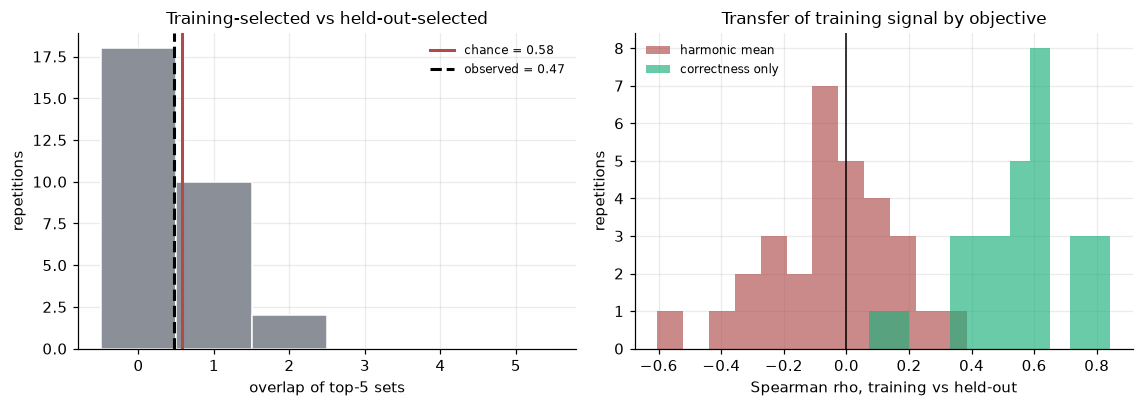

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axes[0]
ax.hist(ov, bins=np.arange(-0.5, KSEL + 1.5), color="#8a8f98", edgecolor="white")
ax.axvline(st.mean(exp), color="#b04b4b", lw=2, label=f"chance = {st.mean(exp):.2f}")
ax.axvline(st.mean(ov), color="black", lw=2, ls="--", label=f"observed = {st.mean(ov):.2f}")
ax.set_xlabel(f"overlap of top-{KSEL} sets"); ax.set_ylabel("repetitions")
ax.set_title("Training-selected vs held-out-selected"); ax.legend(fontsize=8)

ax = axes[1]
ax.hist(rhos, bins=12, alpha=0.65, color="#b04b4b", label="harmonic mean")
ax.hist(r2, bins=12, alpha=0.65, color="#1baf7a", label="correctness only")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Spearman rho, training vs held-out"); ax.set_ylabel("repetitions")
ax.set_title("Transfer of training signal by objective"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "selection_basis_overlap"); plt.show()

### §12d-ii · Margins over the baseline, by rule and basis

Each cell is the mean over that arm's five repetitions of the repetition's top-five
selection, expressed as a margin over the default-policy baseline in that
objective's improving direction.

In [42]:
for b in BENCH:
    bs = baseline[b]["summary"]
    bl = {"F1": bs["mean_cl"]["mean"], "F2": bs["mean_correctness"]["mean"],
          "F3": bs["mean_energy"]["mean"], "feasible": bs["n_feasible"]["mean"]}
    print(f"\n  {b}   baseline F1 {bl['F1']:.3f}  F2 {bl['F2']:.4f}  "
          f"F3 {bl['F3']:.1f}  feasible {bl['feasible']:.1f}")
    for basis in ("training", "held-out"):
        print(f"\n    selection on {basis.upper()} values")
        print(f"      {'arm':4s}{'rule':18s}{'F1':>9s}{'F2':>10s}{'F3':>9s}{'feas':>8s}")
        for a in ORDER:
            for rule in RULES2:
                M = SELMAT[(b, a, basis, rule)].mean(0)
                m = [bl["F1"] - M[0], M[1] - bl["F2"], bl["F3"] - M[2], M[3] - bl["feasible"]]
                print(f"      {a:4s}{rule:18s}{m[0]:+9.3f}{m[1]:+10.4f}{m[2]:+9.1f}{m[3]:+8.1f}")


  Codeflaws (C)   baseline F1 9.259  F2 0.4580  F3 35.6  feasible 68.8

    selection on TRAINING values
      arm rule                     F1        F2       F3    feas
      GA  correctness only     +0.113   +0.0385     +4.1    +5.6
      GA  harmonic             +0.455   -0.0143     -7.7    -2.4
      GA  dist-to-ideal        +0.424   -0.0191     -7.7    -2.9
      GA  hyperplane           +0.181   +0.0189     -6.2    +2.2
      GA  tradeoff-knee        +0.537   -0.0121     -4.0    -1.8
      RS  correctness only     +0.070   +0.0413     +3.9    +6.4
      RS  harmonic             +0.286   +0.0113     +0.0    +0.8
      RS  dist-to-ideal        +0.196   +0.0163     -1.0    +1.3
      RS  hyperplane           +0.147   +0.0198     +2.8    +2.5
      RS  tradeoff-knee        +0.301   -0.0058     +0.3    -0.9
      MOBOcorrectness only     +0.124   +0.0520     -0.6    +7.6
      MOBOharmonic             +0.646   -0.0164     -0.2    -4.1
      MOBOdist-to-ideal        +0.559   -0.0154  

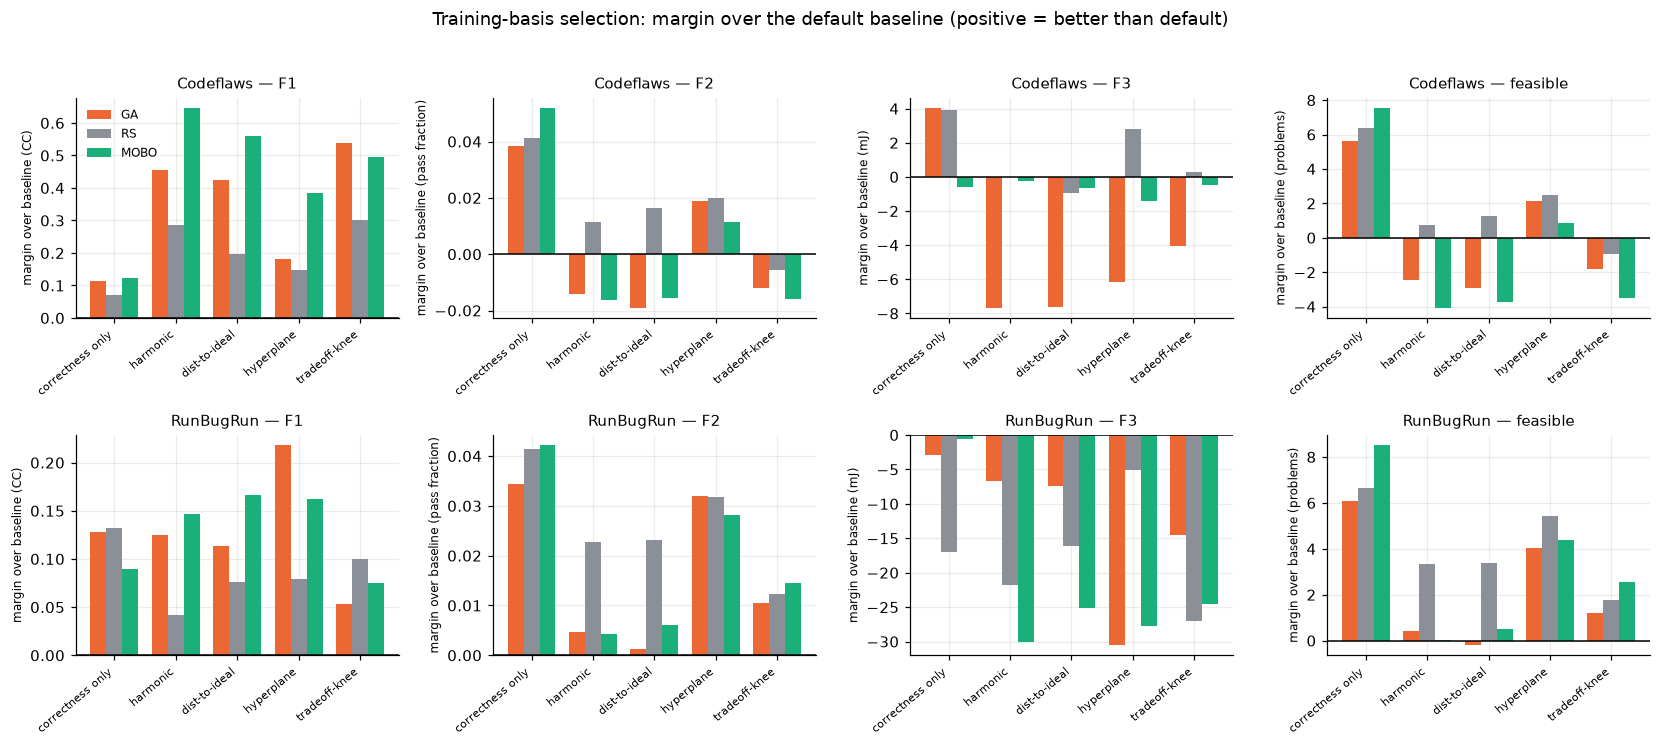

In [43]:
# No shared y-axis: the four outcomes differ in scale by two orders of magnitude
# (F2 margins are ~0.03, feasibility margins ~6), so a shared axis renders the
# F2 panel as a flat line at zero. Each panel carries its own scale and its own
# unit, stated in the y-label.
fig, axes = plt.subplots(len(BENCH), len(OUTCOMES),
                         figsize=(3.8 * len(OUTCOMES), 3.3 * len(BENCH)),
                         squeeze=False)
for r, b in enumerate(BENCH):
    bs = baseline[b]["summary"]
    bl = {"F1": bs["mean_cl"]["mean"], "F2": bs["mean_correctness"]["mean"],
          "F3": bs["mean_energy"]["mean"], "feasible": bs["n_feasible"]["mean"]}
    for c, (o, better) in enumerate(OUTCOMES):
        ax = axes[r, c]
        x = np.arange(len(RULES2)); w = 0.26
        for k, a in enumerate(ORDER):
            vals = []
            for rule in RULES2:
                M = SELMAT[(b, a, "training", rule)].mean(0)
                v = {"F1": bl["F1"] - M[0], "F2": M[1] - bl["F2"],
                     "F3": bl["F3"] - M[2], "feasible": M[3] - bl["feasible"]}[o]
                vals.append(v)
            ax.bar(x + (k - (len(ORDER) - 1) / 2) * w, vals, w, color=PALETTE[a],
                   label=a if c == 0 else None)
        ax.axhline(0, color="black", lw=1)
        ax.set_xticks(x); ax.set_xticklabels(RULES2, rotation=40, ha="right", fontsize=7)
        ax.set_title(f"{b.split(' ')[0]} — {o}", fontsize=10)
        unit = {"F1": "CC", "F2": "pass fraction", "F3": "mJ",
                "feasible": "problems"}[o]
        ax.set_ylabel(f"margin over baseline ({unit})", fontsize=8)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Training-basis selection: margin over the default baseline "
             "(positive = better than default)", y=1.02)
fig.tight_layout(); savefig(fig, "selection_basis_margins"); plt.show()

### §12d-iii · Significance of the deployable rule

Each arm's top-five-by-training-correctness selection is compared against the
default-policy baseline on all four outcomes.

**The multiplicity family is narrow, and the headline count depends on it.**
Holm is applied over the four outcomes *within* each benchmark-arm cell -- six
separate families of four. It is not applied across all 24 comparisons together.
Correcting all 24 as one family leaves nothing significant (smallest adjusted
p ~ 0.19). The narrow family is defensible only if the six cells were treated as
separate questions in advance; because correctness-only selection was itself
chosen after inspecting held-out results, that is a genuine limitation and is
recorded as such.

Two further cautions on reading the count. F2 and feasibility are mechanically
linked -- F2 averages correctness over all problems with infeasible scoring
zero -- so the surviving cells are paired findings, not independent
confirmations. And "top five" reports the mean outcome of a shortlist; turning it
into a deployable rule requires a stated procedure for picking one policy from
that shortlist, which this study does not specify.

In [44]:
SELECT_TESTS = {}
for rule in RULES2:
    for b in BENCH:
        braw = {"F1": [r["mean_cl"] for r in baseline[b]["reps"]],
                "F2": [r["mean_correctness"] for r in baseline[b]["reps"]],
                "F3": [r["mean_energy"] for r in baseline[b]["reps"]],
                "feasible": [float(r["n_feasible"]) for r in baseline[b]["reps"]]}
        for a in ORDER:
            S = SELMAT[(b,a,"training",rule)]
            ps = [between(S[:,k],braw[o])[0] for k,(o,_) in enumerate(OUTCOMES)]
            for k,((o,better),pv,pa) in enumerate(zip(OUTCOMES,ps,holm_adjust(ps))):
                bm, mu = st.mean(braw[o]), float(S[:,k].mean())
                margin = bm-mu if better == "lo" else mu-bm
                SELECT_TESTS[(rule,b,a,o)] = dict(baseline=bm, selected=mu, margin=margin,
                    relative_pct=100*margin/bm, baseline_sd_units=margin/st.stdev(braw[o]), p=pv, p_holm=pa,
                    per_rep=S[:,k].tolist())
# Also expose the sensitivity to treating all 24 correctness-rule tests as one family.
selected_keys = [k for k in SELECT_TESTS if k[0] == "correctness only"]
for k,pa in zip(selected_keys,holm_adjust([SELECT_TESTS[k]["p"] for k in selected_keys])):
    SELECT_TESTS[k]["p_holm_global24"] = pa
    _,b,a,o=k; r=SELECT_TESTS[k]
    print(f"  {b:22s} {a:5s} {o:8s} margin={r['margin']:+.4f} "
          f"nominal p={r['p']:.5f} Holm(4)={r['p_holm']:.5f} Holm(24)={pa:.5f}")
print("  correctness-only positive margins:",sum(SELECT_TESTS[k]["margin"]>0 for k in selected_keys),"/24")

  Codeflaws (C)          GA    F1       margin=+0.1128 nominal p=0.54762 Holm(4)=0.54762 Holm(24)=1.00000
  Codeflaws (C)          GA    F2       margin=+0.0385 nominal p=0.00794 Holm(4)=0.03175 Holm(24)=0.19048
  Codeflaws (C)          GA    F3       margin=+4.0547 nominal p=0.22222 Holm(4)=0.44444 Holm(24)=1.00000
  Codeflaws (C)          GA    feasible margin=+5.6000 nominal p=0.01193 Holm(4)=0.03578 Holm(24)=0.22658
  Codeflaws (C)          RS    F1       margin=+0.0696 nominal p=0.84127 Holm(4)=0.84127 Holm(24)=1.00000
  Codeflaws (C)          RS    F2       margin=+0.0413 nominal p=0.00794 Holm(4)=0.03175 Holm(24)=0.19048
  Codeflaws (C)          RS    F3       margin=+3.8928 nominal p=0.30952 Holm(4)=0.61905 Holm(24)=1.00000
  Codeflaws (C)          RS    feasible margin=+6.4000 nominal p=0.01597 Holm(4)=0.04791 Holm(24)=0.23810
  Codeflaws (C)          MOBO  F1       margin=+0.1241 nominal p=0.54762 Holm(4)=1.00000 Holm(24)=1.00000
  Codeflaws (C)          MOBO  F2       margin

The same test applied to every selection rule, so the correctness-only result can
be read against its alternatives rather than in isolation. Each row is 6
arm-benchmark cells x 4 outcomes = 24 tests, Holm-corrected over the four
outcomes within each arm.

In [45]:
print(f"  {'rule':20s}{'cells':>7s}{'nominal':>9s}{'Holm(4)':>9s}   surviving cells")
for rule in RULES2:
    items=[(k,r) for k,r in SELECT_TESTS.items() if k[0]==rule]
    survivors=[f"{k[1].split()[0]}/{k[2]}/{k[3]}" for k,r in items if r["p_holm"]<.05]
    print(f"  {rule:20s}{len(items):7d}{sum(r['p']<.05 for _,r in items):9d}"
          f"{len(survivors):9d}   {', '.join(survivors) or '(none)'}")

  rule                  cells  nominal  Holm(4)   surviving cells
  correctness only         24       12       10   Codeflaws/GA/F2, Codeflaws/GA/feasible, Codeflaws/RS/F2, Codeflaws/RS/feasible, Codeflaws/MOBO/F2, Codeflaws/MOBO/feasible, RunBugRun/RS/F2, RunBugRun/RS/feasible, RunBugRun/MOBO/F2, RunBugRun/MOBO/feasible
  harmonic                 24        3        1   Codeflaws/MOBO/F1
  dist-to-ideal            24        3        1   Codeflaws/MOBO/F1
  hyperplane               24        5        0   (none)
  tradeoff-knee            24        2        1   Codeflaws/GA/F1


#### Interpretation

Correctness-only shortlists have positive mean F2 and feasibility margins in all
six benchmark-arm cells. Nominal significance is not universal; use the printed
p-values. Holm over four outcomes within each cell yields ten significant
outcomes (five F2/feasibility pairs). Across all 24 tests, none survives.
Complexity and energy are not significantly changed by this rule.

The rule has the largest mean F2 and feasibility among these five rules in every
cell, but its selection was informed by these held-out analyses. Treat it as an
exploratory finding needing independent validation. Complexity trade-offs vary by
benchmark and arm; do not generalise one rule's advantage across all cells.

## §12e · Effect sizes with uncertainty

Sections 3 and 4 report Cliff's delta as point estimates. At five repetitions per
arm a point estimate is a weak summary: delta is bounded in [-1, +1] and its
sampling distribution at n = 5 is coarse and highly discrete. The interval below
is a percentile bootstrap over repetitions (the unit of replication), so it
answers "how much would this delta move under a different draw of seeds?".

A delta whose interval spans zero is not evidence of no difference; at this
sample size almost nothing excludes zero. The value of the interval is that it
quantifies how weakly the design constrains the effect, which is the appropriate
interpretation of a five-repetition study.

In [46]:
BOOT_D = 4000
rng_d = np.random.default_rng(7)

def boot_delta(x, y, n=BOOT_D):
    # Bootstrap Cliff's delta by resampling repetitions within each arm.
    x, y = np.asarray(x, float), np.asarray(y, float)
    out = np.empty(n)
    for k in range(n):
        xs = x[rng_d.integers(0, len(x), len(x))]
        ys = y[rng_d.integers(0, len(y), len(y))]
        out[k] = cliffs_delta(list(ys), list(xs))
    return out

DELTA_CI = {}
print(f"  Cliff's delta with bootstrap intervals ({BOOT_D} resamples of repetitions)\n")
print(f"  {'benchmark':22s}{'contrast':12s}{'objective':16s}{'delta':>8s}{'95% CI':>20s}{'spans 0':>9s}")
for b in BENCH:
    for key, lab in (("mean_correctness", "F2 correctness"),
                     ("mean_cl", "F1 complexity"),
                     ("mean_energy", "F3 energy")):
        for x, y in combinations(ORDER, 2):
            xr, yr = per_rep(b, x, key), per_rep(b, y, key)
            d = cliffs_delta(yr, xr)
            bs = boot_delta(xr, yr)
            lo, hi = np.percentile(bs, [2.5, 97.5])
            DELTA_CI[(b, key, x, y)] = (d, lo, hi)
            # A resample of completely separated samples can never produce
            # overlap, so delta = +/-1 yields a degenerate zero-width interval.
            # That is a property of the empirical bootstrap at n = 5, not
            # evidence of precision, and is flagged rather than reported as a CI.
            spans = ("degenerate" if hi - lo < 1e-9 else
                     "yes" if lo <= 0 <= hi else "NO")
            print(f"  {b:22s}{y+'-'+x:12s}{lab:16s}{d:+8.3f}   [{lo:+6.3f},{hi:+6.3f}]{spans:>9s}")
    print()

  Cliff's delta with bootstrap intervals (4000 resamples of repetitions)

  benchmark             contrast    objective          delta              95% CI  spans 0
  Codeflaws (C)         RS-GA       F2 correctness    +1.000   [+1.000,+1.000]degenerate
  Codeflaws (C)         MOBO-GA     F2 correctness    +0.360   [-0.440,+0.920]      yes


  Codeflaws (C)         MOBO-RS     F2 correctness    -0.520   [-1.000,+0.280]      yes

  Codeflaws (C)         RS-GA       F1 complexity     +0.600   [-0.120,+1.000]      yes
  Codeflaws (C)         MOBO-GA     F1 complexity     -0.040   [-0.760,+0.680]      yes
  Codeflaws (C)         MOBO-RS     F1 complexity     -0.600   [-1.000,+0.200]      yes


  Codeflaws (C)         RS-GA       F3 energy         -0.600   [-1.000,+0.200]      yes


  Codeflaws (C)         MOBO-GA     F3 energy         -0.200   [-1.000,+0.520]      yes
  Codeflaws (C)         MOBO-RS     F3 energy         +0.760   [+0.200,+1.000]       NO

  RunBugRun (Python)    RS-GA       F2 correctness    +0.600   [-0.120,+1.000]      yes


  RunBugRun (Python)    MOBO-GA     F2 correctness    +0.040   [-0.680,+0.840]      yes


  RunBugRun (Python)    MOBO-RS     F2 correctness    -0.520   [-1.000,+0.280]      yes
  RunBugRun (Python)    RS-GA       F1 complexity     +0.360   [-0.440,+1.000]      yes
  RunBugRun (Python)    MOBO-GA     F1 complexity     +0.680   [+0.040,+1.000]       NO


  RunBugRun (Python)    MOBO-RS     F1 complexity     +0.280   [-0.600,+1.000]      yes


  RunBugRun (Python)    RS-GA       F3 energy         +0.360   [-0.600,+1.000]      yes
  RunBugRun (Python)    MOBO-GA     F3 energy         -0.200   [-1.000,+0.600]      yes
  RunBugRun (Python)    MOBO-RS     F3 energy         -0.520   [-1.000,+0.200]      yes



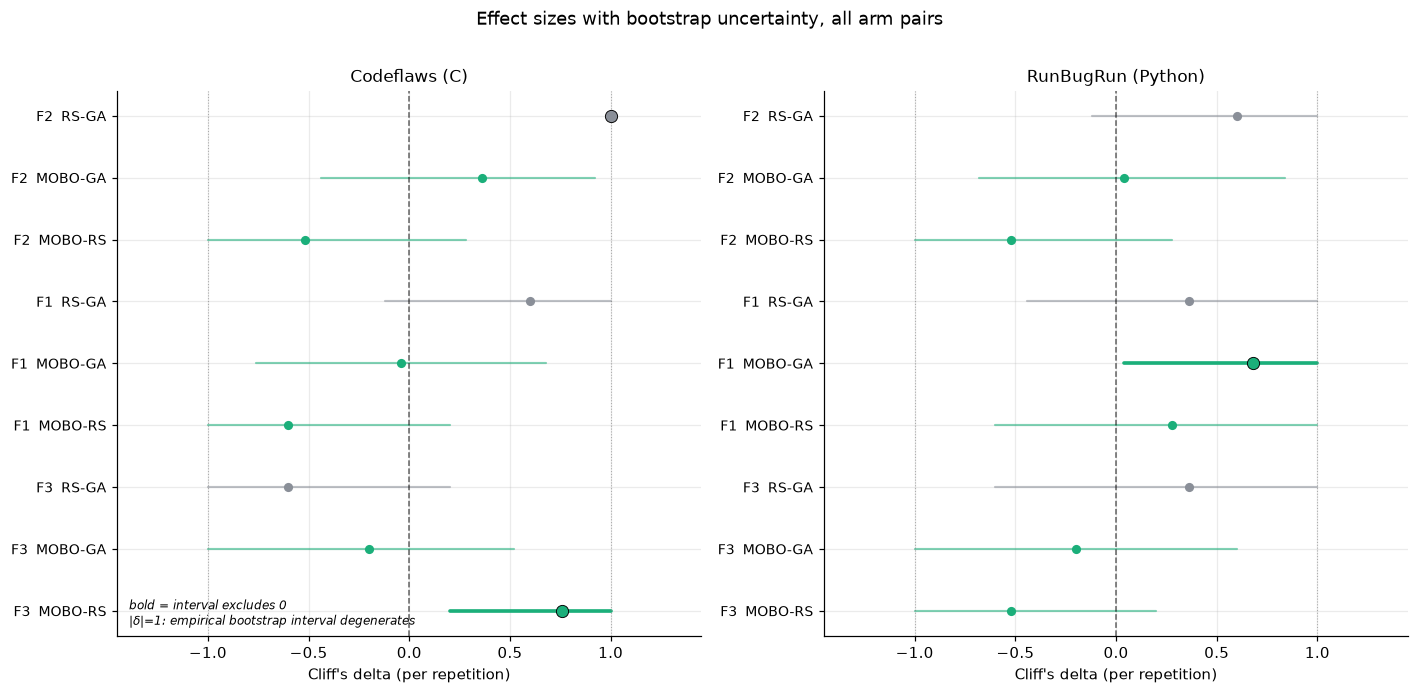

In [47]:
# Forest plot: every arm-pair contrast on every objective, both benchmarks.
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True)
for ax, b in zip(axes, BENCH):
    rows, labels, cols = [], [], []
    for key, lab in (("mean_correctness", "F2"), ("mean_cl", "F1"), ("mean_energy", "F3")):
        for x, y in combinations(ORDER, 2):
            d, lo, hi = DELTA_CI[(b, key, x, y)]
            rows.append((d, lo, hi)); labels.append(f"{lab}  {y}-{x}")
            cols.append(PALETTE[y])
    ypos = np.arange(len(rows))[::-1]
    for yy, (d, lo, hi), c in zip(ypos, rows, cols):
        excl = not (lo <= 0 <= hi)
        ax.plot([lo, hi], [yy, yy], color=c, lw=2.4 if excl else 1.4,
                alpha=1.0 if excl else 0.55, solid_capstyle="round")
        ax.plot([d], [yy], "o", color=c, ms=8 if excl else 6,
                markeredgecolor="black", markeredgewidth=0.6 if excl else 0.0, zorder=3)
    ax.axvline(0, color="black", lw=1, ls="--", alpha=0.6)
    for v in (-1, 1):
        ax.axvline(v, color="grey", lw=0.7, ls=":", alpha=0.6)
    ax.set_yticks(ypos); ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel("Cliff's delta (per repetition)"); ax.set_title(b)
    ax.set_xlim(-1.45, 1.45); ax.grid(axis="x", alpha=0.25)
axes[0].text(0.02, 0.02, "bold = interval excludes 0\n|δ|=1: empirical bootstrap interval degenerates", transform=axes[0].transAxes,
             fontsize=8, style="italic")
fig.suptitle("Effect sizes with bootstrap uncertainty, all arm pairs", y=1.01)
fig.tight_layout(); savefig(fig, "effect_size_forest"); plt.show()

## §12f · Exact permutation inference

At n = 5 versus 5 the null distribution is small enough to enumerate completely:
there are C(10,5) = 252 ways to split ten observations into two labelled groups
of five. The exact permutation p-value is therefore not an approximation and not
a simulation -- it is the entire null, computed by exhaustion.

This also makes the resolution limit visible rather than asserted. The smallest
attainable two-sided p is 2/252 = 0.0079, and it is attained only under complete
separation. Plotting the observed statistic against the full null shows exactly
how much of the distribution lies beyond it.

In [48]:
def exact_perm(x, y):
    # Exhaustive two-sided permutation test on the difference of means.
    pool = np.array(list(x) + list(y), float)
    n = len(x)
    obs = abs(np.mean(x) - np.mean(y))
    stats, idx_all = [], range(len(pool))
    for comb in combinations(idx_all, n):
        m = np.zeros(len(pool), bool); m[list(comb)] = True
        stats.append(abs(pool[m].mean() - pool[~m].mean()))
    stats = np.array(stats)
    p = float((stats >= obs - 1e-12).mean())
    return obs, stats, p

PERM = {}
print(f"  exact permutation tests, full enumeration of the null\n")
print(f"  {'benchmark':22s}{'contrast':12s}{'objective':16s}{'perms':>7s}{'exact p':>10s}{'MWU p':>10s}")
for b in BENCH:
    for key, lab in (("mean_correctness", "F2 correctness"),
                     ("mean_cl", "F1 complexity"),
                     ("mean_energy", "F3 energy")):
        for x, y in combinations(ORDER, 2):
            xr, yr = per_rep(b, x, key), per_rep(b, y, key)
            obs, null, pe = exact_perm(xr, yr)
            pm, _, _ = between(xr, yr)
            PERM[(b, key, x, y)] = (obs, null, pe, pm)
            print(f"  {b:22s}{y+'-'+x:12s}{lab:16s}{len(null):7d}{pe:10.4f}{pm:10.4f}")
    print()
print("  the exact minimum at n=5 vs 5 is 2/252 = 0.0079; at n=5 vs 3 it is 2/56 = 0.0357")

  exact permutation tests, full enumeration of the null

  benchmark             contrast    objective         perms   exact p     MWU p
  Codeflaws (C)         RS-GA       F2 correctness      252    0.0079    0.0079
  Codeflaws (C)         MOBO-GA     F2 correctness      252    0.5238    0.4206
  Codeflaws (C)         MOBO-RS     F2 correctness      252    0.1270    0.2222
  Codeflaws (C)         RS-GA       F1 complexity       252    0.0873    0.1508
  Codeflaws (C)         MOBO-GA     F1 complexity       252    0.9683    1.0000
  Codeflaws (C)         MOBO-RS     F1 complexity       252    0.0952    0.1508
  Codeflaws (C)         RS-GA       F3 energy           252    0.0794    0.1508
  Codeflaws (C)         MOBO-GA     F3 energy           252    0.8810    0.6905
  Codeflaws (C)         MOBO-RS     F3 energy           252    0.0317    0.0556

  RunBugRun (Python)    RS-GA       F2 correctness      252    0.1429    0.1508
  RunBugRun (Python)    MOBO-GA     F2 correctness      252   

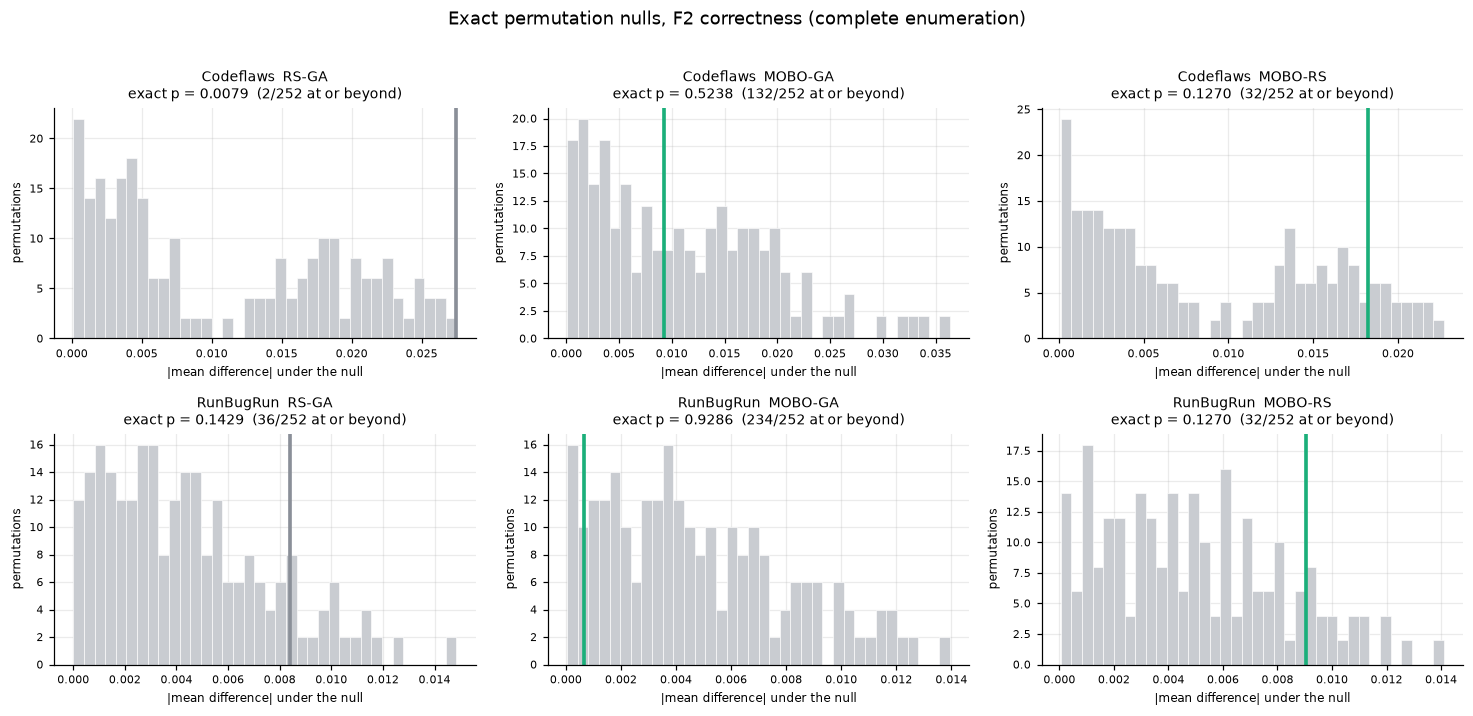

In [49]:
# Null distributions for the six F2 contrasts, observed statistic marked.
fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.4))
for row, b in enumerate(BENCH):
    for col, (x, y) in enumerate(combinations(ORDER, 2)):
        ax = axes[row, col]
        obs, null, pe, pm = PERM[(b, "mean_correctness", x, y)]
        ax.hist(null, bins=36, color="#c9ccd1", edgecolor="white", linewidth=0.4)
        ax.axvline(obs, color=PALETTE[y], lw=2.4)
        beyond = (null >= obs - 1e-12).sum()
        ax.set_title(f"{b.split()[0]}  {y}-{x}\nexact p = {pe:.4f}  ({beyond}/{len(null)} at or beyond)",
                     fontsize=9)
        ax.set_xlabel("|mean difference| under the null", fontsize=8)
        ax.set_ylabel("permutations", fontsize=8)
        ax.tick_params(labelsize=7)
fig.suptitle("Exact permutation nulls, F2 correctness (complete enumeration)", y=1.01)
fig.tight_layout(); savefig(fig, "permutation_nulls_f2"); plt.show()

## §12g · Statistical power under a normal-model simulation

For each standardised effect, simulate 3,000 samples per arm-size/test setting
and count nominal rejections at α=.05. The resulting sensitivity depends on the
assumed normal distributions and variance. It is not a universal minimum
detectable effect for these data, and does not include multiplicity correction.

In [50]:
N_SIM = 3000
rng_p = np.random.default_rng(11)
EFFECTS = np.arange(0.0, 3.01, 0.25)

def power_curve(n1, n2, effects=EFFECTS, n_sim=N_SIM):
    out = []
    for e in effects:
        rej = 0
        for _ in range(n_sim):
            a = rng_p.normal(0.0, 1.0, n1)
            c = rng_p.normal(e, 1.0, n2)
            try:
                _, pv = mannwhitneyu(a, c, alternative="two-sided")
                rej += pv < 0.05
            except ValueError:
                pass
        out.append(rej / n_sim)
    return np.array(out)

POW = {"5 vs 5 (current)": power_curve(5, 5),
       "5 vs 3 (MOBO, before)": power_curve(5, 3),
       "8 vs 8": power_curve(8, 8),
       "10 vs 10": power_curve(10, 10)}

print("  power of the two-sided Mann-Whitney test at alpha = 0.05\n")
print(f"  {'design':24s}" + "".join(f"{e:>7.2f}" for e in EFFECTS[::2]))
for k, v in POW.items():
    print(f"  {k:24s}" + "".join(f"{x:7.2f}" for x in v[::2]))
print("\n  columns are the true difference in standard deviations")
for k, v in POW.items():
    hit = EFFECTS[np.argmax(v >= 0.80)] if (v >= 0.80).any() else None
    print(f"  {k:24s} 80% power at effect >= {hit if hit is not None else 'never in range'}")

  power of the two-sided Mann-Whitney test at alpha = 0.05

  design                     0.00   0.50   1.00   1.50   2.00   2.50   3.00
  5 vs 5 (current)           0.03   0.07   0.22   0.43   0.68   0.86   0.95
  5 vs 3 (MOBO, before)      0.04   0.07   0.16   0.32   0.52   0.69   0.85
  8 vs 8                     0.05   0.14   0.46   0.77   0.95   0.99   1.00
  10 vs 10                   0.04   0.16   0.50   0.85   0.98   1.00   1.00

  columns are the true difference in standard deviations
  5 vs 5 (current)         80% power at effect >= 2.5
  5 vs 3 (MOBO, before)    80% power at effect >= 3.0
  8 vs 8                   80% power at effect >= 1.75
  10 vs 10                 80% power at effect >= 1.5


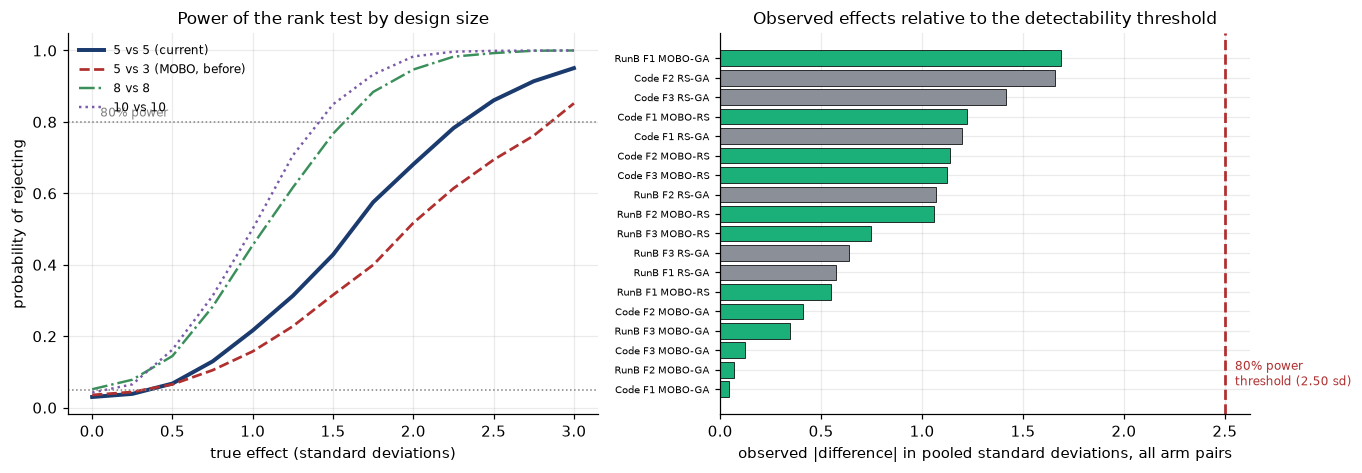

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
styles = {"5 vs 5 (current)": ("-", "#1b3b6f", 2.6), "5 vs 3 (MOBO, before)": ("--", "#b03030", 1.8),
          "8 vs 8": ("-.", "#3a8f5a", 1.6), "10 vs 10": (":", "#7a5aa8", 1.6)}
for k, v in POW.items():
    ls, c, lw = styles[k]
    ax.plot(EFFECTS, v, ls, color=c, lw=lw, label=k)
ax.axhline(0.80, color="grey", ls=":", lw=1)
ax.text(0.05, 0.815, "80% power", fontsize=8, color="grey")
ax.axhline(0.05, color="grey", ls=":", lw=1)
ax.set_xlabel("true effect (standard deviations)"); ax.set_ylabel("probability of rejecting")
ax.set_title("Power of the rank test by design size"); ax.legend(fontsize=8); ax.grid(alpha=0.25)

# Observed standardised effects, locating this study on the power curve above.
ax = axes[1]
obs_d, labs, cols = [], [], []
for b in BENCH:
    for key, lab in (("mean_correctness", "F2"), ("mean_cl", "F1"), ("mean_energy", "F3")):
        for x, y in combinations(ORDER, 2):
            xr, yr = per_rep(b, x, key), per_rep(b, y, key)
            sd = np.sqrt((np.var(xr, ddof=1) + np.var(yr, ddof=1)) / 2)
            if sd > 0:
                obs_d.append(abs(np.mean(yr) - np.mean(xr)) / sd)
                labs.append(f"{b.split()[0][:4]} {lab} {y}-{x}"); cols.append(PALETTE[y])
order_ = np.argsort(obs_d)
ax.barh(np.arange(len(obs_d)), [obs_d[i] for i in order_],
        color=[cols[i] for i in order_], edgecolor="black", linewidth=0.5)
ax.set_yticks(np.arange(len(obs_d))); ax.set_yticklabels([labs[i] for i in order_], fontsize=6.5)
p80 = EFFECTS[np.argmax(POW["5 vs 5 (current)"] >= 0.80)] if (POW["5 vs 5 (current)"] >= 0.80).any() else None
if p80 is not None:
    ax.axvline(p80, color="#b03030", lw=1.8, ls="--")
    ax.text(p80 + 0.05, 0.2, f"80% power\nthreshold ({p80:.2f} sd)", fontsize=8, color="#b03030")
ax.set_xlabel("observed |difference| in pooled standard deviations, all arm pairs")
ax.set_title("Observed effects relative to the detectability threshold"); ax.grid(axis="x", alpha=0.25)
fig.tight_layout(); savefig(fig, "power_analysis"); plt.show()

## §12h · Exploratory equivalence testing

Non-significant MWU is not equivalence. The two one-sided Welch tests below use
an estimated equivalence margin of one baseline SD. Accepting that margin as
practically negligible is a substantive assumption, not a consequence of
measurement noise. These TOST results are uncorrected exploratory diagnostics.

Difference and equivalence are separate questions: either, both, or neither can
reject. A small but nonzero difference can satisfy both. The printed table
states all four cases; an inconclusive result does not support equivalence.

In [52]:
def tost(x, y, margin):
    # Two one-sided Welch tests against +/- margin. Equivalence is the max of the two p's.
    x, y = np.asarray(x, float), np.asarray(y, float)
    d = x.mean() - y.mean()
    se = np.sqrt(x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y))
    if se == 0:
        return d, (0.0 if abs(d) < margin else 1.0)
    df = (x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y)) ** 2 / (
        (x.var(ddof=1) / len(x)) ** 2 / (len(x) - 1) + (y.var(ddof=1) / len(y)) ** 2 / (len(y) - 1))
    from scipy.stats import t as tdist
    p_lo = 1 - tdist.cdf((d + margin) / se, df)
    p_hi = tdist.cdf((d - margin) / se, df)
    return d, float(max(p_lo, p_hi))

print("  equivalence testing against a margin of one baseline sd\n")
print(f"  {'benchmark':22s}{'contrast':12s}{'obj':6s}{'diff':>10s}{'margin':>9s}"
      f"{'TOST p':>9s}{'MWU p':>9s}   verdict")
TOSTR = {}
for b in BENCH:
    bs = baseline[b]["summary"]
    for key, lab in (("mean_correctness", "F2"), ("mean_cl", "F1"), ("mean_energy", "F3")):
        margin = bs[key]["std"]
        for x, y in combinations(ORDER, 2):
            xr, yr = per_rep(b, x, key), per_rep(b, y, key)
            d, pt = tost(yr, xr, margin)
            pm, _, _ = between(xr, yr)
            if pm < 0.05 and pt >= 0.05:   v = "DIFFERENT"
            elif pt < 0.05 and pm >= 0.05: v = "EQUIVALENT"
            elif pt < 0.05 and pm < 0.05:  v = "trivially different"
            else:                          v = "inconclusive"
            TOSTR[(b, key, x, y)] = (d, margin, pt, pm, v)
            print(f"  {b:22s}{y+'-'+x:12s}{lab:6s}{d:+10.4f}{margin:9.4f}{pt:9.3g}{pm:9.3g}   {v}")
    print()
tally = {}
for v in TOSTR.values(): tally[v[4]] = tally.get(v[4], 0) + 1
print("  " + "   ".join(f"{k}: {n}/{len(TOSTR)}" for k, n in sorted(tally.items())))

  equivalence testing against a margin of one baseline sd

  benchmark             contrast    obj         diff   margin   TOST p    MWU p   verdict
  Codeflaws (C)         RS-GA       F2       +0.0275   0.0243    0.612  0.00794   DIFFERENT
  Codeflaws (C)         MOBO-GA     F2       +0.0093   0.0243    0.163    0.421   inconclusive
  Codeflaws (C)         MOBO-RS     F2       -0.0182   0.0243     0.29    0.222   inconclusive
  Codeflaws (C)         RS-GA       F1       +0.1210   0.2821   0.0311    0.151   EQUIVALENT
  Codeflaws (C)         MOBO-GA     F1       -0.0061   0.2821  0.00788        1   EQUIVALENT
  Codeflaws (C)         MOBO-RS     F1       -0.1270   0.2821   0.0371    0.151   EQUIVALENT
  Codeflaws (C)         RS-GA       F3       -6.0927   5.9377    0.522    0.151   inconclusive
  Codeflaws (C)         MOBO-GA     F3       +0.8858   5.9377    0.153     0.69   inconclusive
  Codeflaws (C)         MOBO-RS     F3       +6.9785   5.9377    0.599   0.0556   inconclusive

  Ru

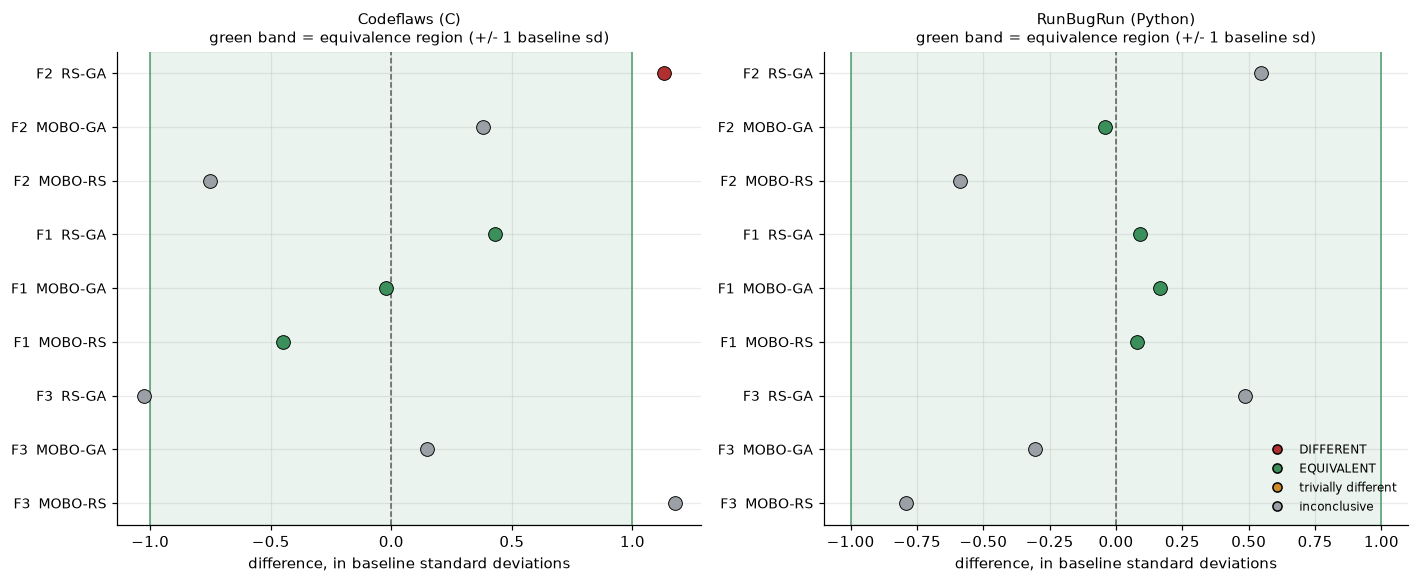

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharex=False)
VCOL = {"DIFFERENT": "#b03030", "EQUIVALENT": "#3a8f5a",
        "trivially different": "#d08a2a", "inconclusive": "#9aa0a6"}
for ax, b in zip(axes, BENCH):
    labs, ds, ms, vs = [], [], [], []
    for key, lab in (("mean_correctness", "F2"), ("mean_cl", "F1"), ("mean_energy", "F3")):
        for x, y in combinations(ORDER, 2):
            d, margin, pt, pm, v = TOSTR[(b, key, x, y)]
            labs.append(f"{lab}  {y}-{x}"); ds.append(d / margin); ms.append(1.0); vs.append(v)
    yp = np.arange(len(ds))[::-1]
    ax.axvspan(-1, 1, color="#3a8f5a", alpha=0.10)
    ax.axvline(0, color="black", lw=1, ls="--", alpha=0.6)
    for v_ in (-1, 1):
        ax.axvline(v_, color="#3a8f5a", lw=1.2, ls="-", alpha=0.7)
    for yy, d, v in zip(yp, ds, vs):
        ax.plot([d], [yy], "o", ms=9, color=VCOL[v], markeredgecolor="black", markeredgewidth=0.6)
    ax.set_yticks(yp); ax.set_yticklabels(labs, fontsize=9)
    ax.set_xlabel("difference, in baseline standard deviations")
    ax.set_title(f"{b}\ngreen band = equivalence region (+/- 1 baseline sd)", fontsize=10)
    ax.grid(axis="x", alpha=0.25)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markeredgecolor="black", label=k)
           for k, c in VCOL.items()]
axes[1].legend(handles=handles, fontsize=8, loc="lower right")
fig.tight_layout(); savefig(fig, "equivalence_tost"); plt.show()

## §12i · Distributional diagnostics

Shapiro and Q–Q displays describe the small repetition samples; non-rejection
with n=5 does not verify normality. ECDFs show the pooled-policy distributions.
The energy panels crop their upper x-range at the GA 97th percentile, so they
do not display the full tails and cannot alone establish stochastic dominance.

In [54]:
from scipy.stats import shapiro, probplot
print("  Shapiro-Wilk normality on per-repetition means (n=5 per arm)\n")
print(f"  {'benchmark':22s}{'arm':6s}{'objective':16s}{'W':>8s}{'p':>10s}  {'':4s}")
n_small = 0
for b in BENCH:
    for a in ORDER:
        for key, lab in (("mean_correctness", "F2 correctness"),
                         ("mean_cl", "F1 complexity"), ("mean_energy", "F3 energy")):
            v = per_rep(b, a, key)
            try:
                W, pv = shapiro(v)
                flag = "  <- rejects normality" if pv < 0.05 else ""
                n_small += pv < 0.05
                print(f"  {b:22s}{a:6s}{lab:16s}{W:8.3f}{pv:10.3g}{flag}")
            except Exception as e:
                print(f"  {b:22s}{a:6s}{lab:16s}   (not computable: {e})")
    print()
print(f"  rejects normality in {n_small} of 18 cells.")
print("  At n = 5 Shapiro-Wilk has almost no power, so few rejections is expected and is")
print("  NOT evidence of normality. This motivates the non-parametric policy:")
print("  the design cannot verify the assumption a t-test would require.")

  Shapiro-Wilk normality on per-repetition means (n=5 per arm)

  benchmark             arm   objective              W         p      
  Codeflaws (C)         GA    F2 correctness     0.828     0.134
  Codeflaws (C)         GA    F1 complexity      0.887     0.342
  Codeflaws (C)         GA    F3 energy          0.903     0.428
  Codeflaws (C)         RS    F2 correctness     0.927     0.578
  Codeflaws (C)         RS    F1 complexity      0.940     0.667
  Codeflaws (C)         RS    F3 energy          0.815     0.108
  Codeflaws (C)         MOBO  F2 correctness     0.919     0.525
  Codeflaws (C)         MOBO  F1 complexity      0.985     0.961
  Codeflaws (C)         MOBO  F3 energy          0.654   0.00299  <- rejects normality

  RunBugRun (Python)    GA    F2 correctness     0.901     0.417
  RunBugRun (Python)    GA    F1 complexity      0.972     0.886
  RunBugRun (Python)    GA    F3 energy          0.900     0.408
  RunBugRun (Python)    RS    F2 correctness     0.963     0.8

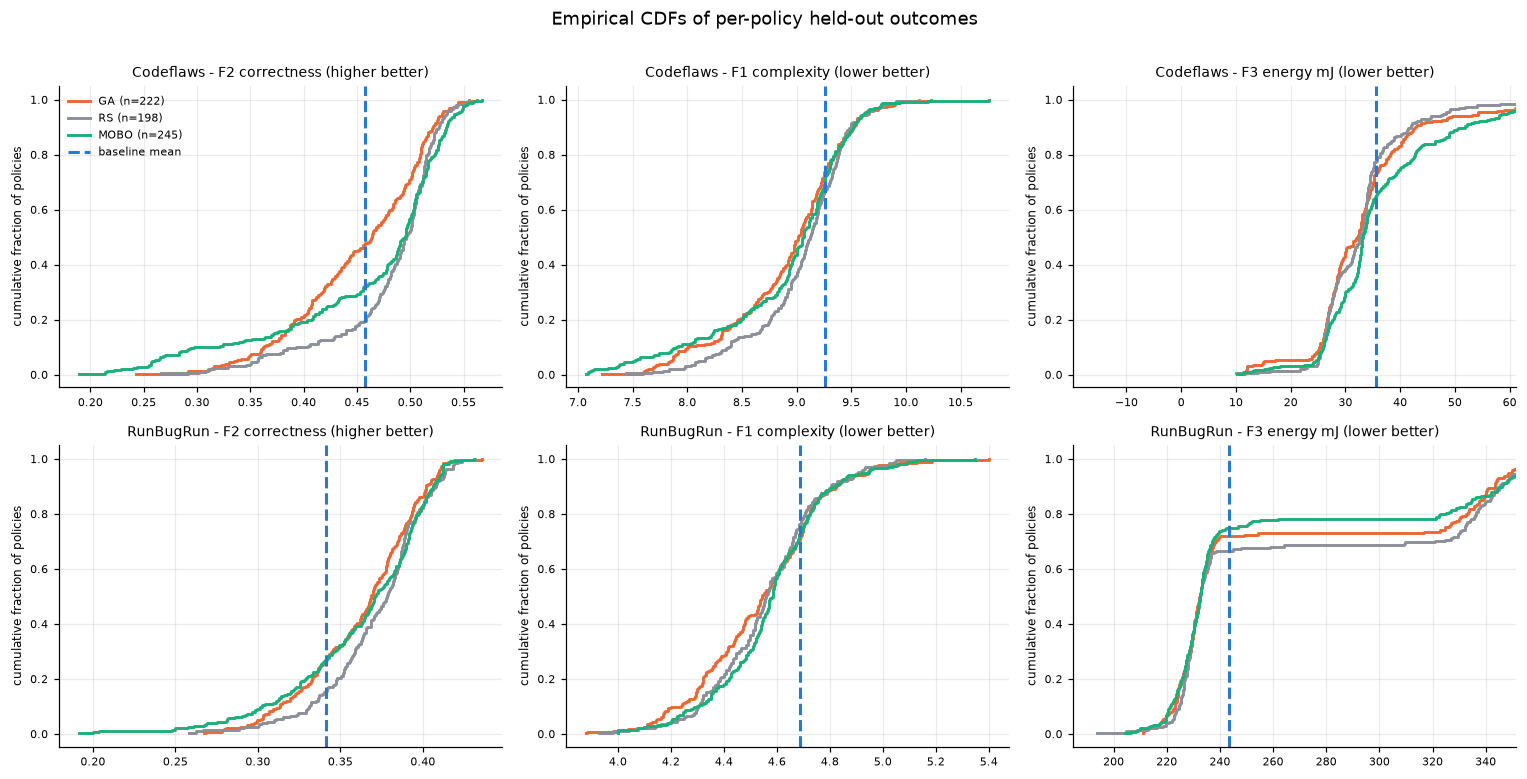

In [55]:
# Empirical CDFs of per-policy outcomes, by arm, against the baseline.
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, b in enumerate(BENCH):
    braw = {"mean_correctness": [r["mean_correctness"] for r in baseline[b]["reps"]],
            "mean_cl": [r["mean_cl"] for r in baseline[b]["reps"]],
            "mean_energy": [r["mean_energy"] for r in baseline[b]["reps"]]}
    for col, (key, lab) in enumerate((("mean_correctness", "F2 correctness (higher better)"),
                                      ("mean_cl", "F1 complexity (lower better)"),
                                      ("mean_energy", "F3 energy mJ (lower better)"))):
        ax = axes[row, col]
        for a in ORDER:
            v = np.sort(np.array(flat(b, a, key), float))
            if len(v) == 0: continue
            ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post",
                    color=PALETTE[a], lw=1.9, label=f"{a} (n={len(v)})")
        ax.axvline(st.mean(braw[key]), color=C_BASE, lw=2.0, ls="--", label="baseline mean")
        if key == "mean_energy":
            hi = np.percentile(np.array(flat(b, "GA", key), float), 97)
            ax.set_xlim(right=hi)
        ax.set_title(f"{b.split()[0]} - {lab}", fontsize=9)
        ax.set_ylabel("cumulative fraction of policies", fontsize=8)
        ax.tick_params(labelsize=7); ax.grid(alpha=0.25)
        if row == 0 and col == 0: ax.legend(fontsize=7)
fig.suptitle("Empirical CDFs of per-policy held-out outcomes", y=1.005)
fig.tight_layout(); savefig(fig, "ecdf_by_arm"); plt.show()

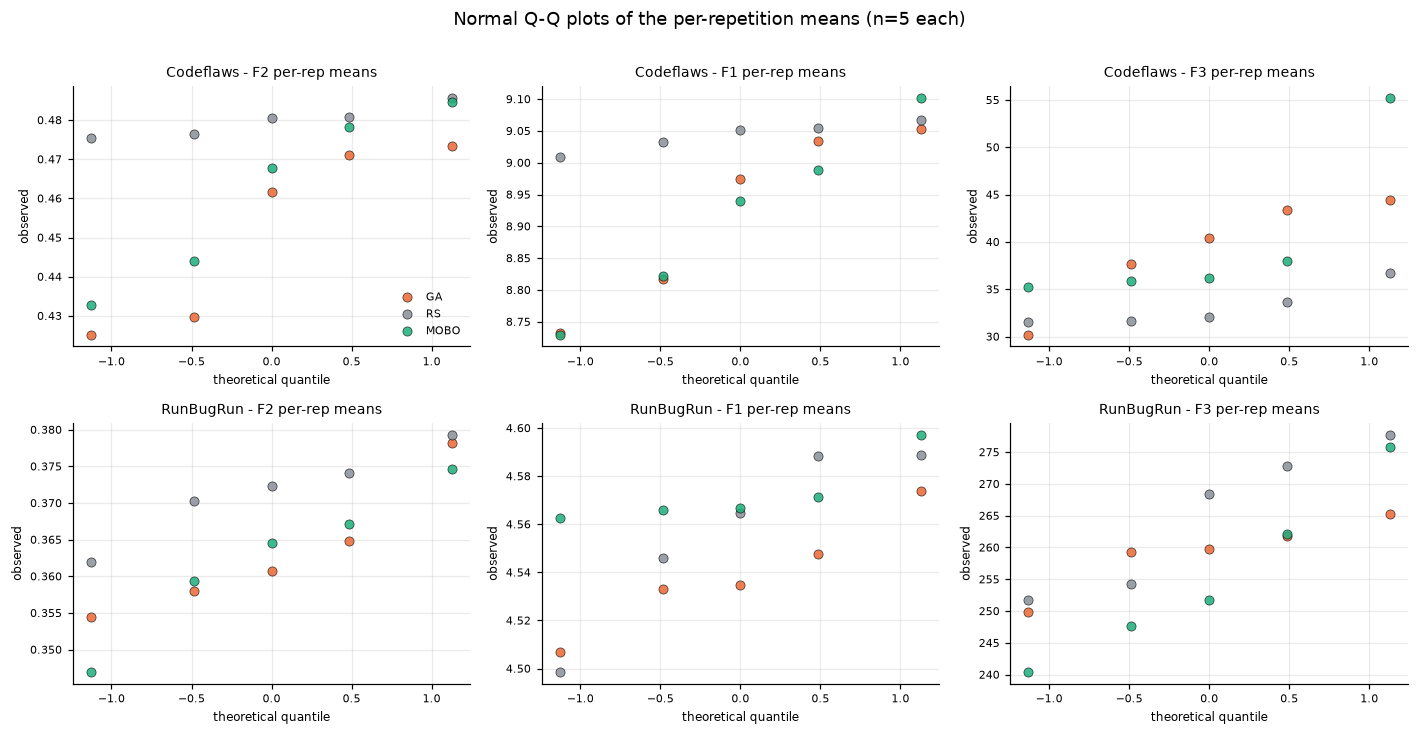

In [56]:
# Q-Q plots for the per-repetition means that the headline tests actually use.
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for row, b in enumerate(BENCH):
    for col, (key, lab) in enumerate((("mean_correctness", "F2"), ("mean_cl", "F1"),
                                      ("mean_energy", "F3"))):
        ax = axes[row, col]
        for a in ORDER:
            v = np.array(per_rep(b, a, key), float)
            (osm, osr), _ = probplot(v, dist="norm", fit=False), None
            ax.plot(osm, osr, "o", color=PALETTE[a], ms=6, alpha=0.85,
                    markeredgecolor="black", markeredgewidth=0.4, label=a)
        ax.set_title(f"{b.split()[0]} - {lab} per-rep means", fontsize=9)
        ax.set_xlabel("theoretical quantile", fontsize=8)
        ax.set_ylabel("observed", fontsize=8); ax.tick_params(labelsize=7); ax.grid(alpha=0.25)
        if row == 0 and col == 0: ax.legend(fontsize=7)
fig.suptitle("Normal Q-Q plots of the per-repetition means (n=5 each)", y=1.005)
fig.tight_layout(); savefig(fig, "qq_per_rep"); plt.show()

## §12j · Omnibus comparison across the three arms

Every test so far is pairwise. Running three pairwise comparisons per objective
inflates the family-wise error rate. Holm corrects for it but leaves the prior
question unaddressed: is there any difference among the three arms at all?

**The correct instrument here is Kruskal-Wallis, not Friedman.** An earlier
revision of this notebook used Friedman on the grounds that the arms "share the
same repetition seeds". They do not: NSGA-II uses seeds 42-46, random search
99-103 and MOBO 123-127. Repetition 0 of one arm has no statistical pairing with
repetition 0 of another, so the samples are independent, not blocked, and the
repeated-measures assumption Friedman requires does not hold. Sharing a held-out
problem set makes the *evaluation* common; it does not pair the *searches*.

Kruskal-Wallis is the independent-samples analogue. Where it rejects, Dunn's test
with Holm correction identifies which pairs differ; the Nemenyi post-hoc and its
critical-difference diagram are omitted because both presuppose the blocked
design that does not apply.

In [57]:
from scipy.stats import kruskal, rankdata, norm
print("  Kruskal-Wallis omnibus across the three arms (independent samples)\n")
print(f"  {'benchmark':22s}{'objective':16s}{'H':>8s}{'p':>10s}   mean ranks (GA, RS, MOBO)")
KW = {}
for b in BENCH:
    for key, lab, better in (("mean_correctness", "F2 correctness", "hi"),
                             ("mean_cl", "F1 complexity", "lo"),
                             ("mean_energy", "F3 energy", "lo")):
        cols = [per_rep(b, a, key) for a in ORDER]
        sgn = -1.0 if better == "hi" else 1.0            # rank 1 = best
        allv = np.concatenate([sgn * np.array(c) for c in cols])
        R = rankdata(allv)
        mr, o = [], 0
        for c in cols:
            mr.append(R[o:o + len(c)].mean()); o += len(c)
        try:
            H, pv = kruskal(*cols)
        except Exception:
            H, pv = float("nan"), float("nan")
        KW[(b, key)] = (H, pv, mr, [len(c) for c in cols])
        flag = "  <- rejects at 0.05" if pv < 0.05 else ""
        print(f"  {b:22s}{lab:16s}{H:8.3f}{pv:10.4f}   " +
              ", ".join(f"{a} {r:.1f}" for a, r in zip(ORDER, mr)) + flag)
    print()

print("  Dunn post-hoc (Holm-corrected) where the omnibus rejects\n")
def dunn(cols, labels):
    ns = [len(c) for c in cols]; N = sum(ns)
    R = rankdata(np.concatenate(cols)); mr, o = [], 0
    for c in cols:
        mr.append(R[o:o + len(c)].mean()); o += len(c)
    _, tie_counts = np.unique(np.concatenate(cols), return_counts=True)
    rank_variance = N * (N + 1) / 12.0 - np.sum(tie_counts**3 - tie_counts) / (12.0 * (N - 1))
    out = []
    for (i, j) in combinations(range(len(cols)), 2):
        se = np.sqrt(rank_variance * (1.0 / ns[i] + 1.0 / ns[j]))
        z = abs(mr[i] - mr[j]) / se
        out.append((f"{labels[j]}-{labels[i]}", z, 2 * (1 - norm.cdf(z))))
    return out

any_rej = False
for (b, key), (H, pv, mr, ns) in KW.items():
    if pv < 0.05:
        any_rej = True
        cols = [np.array(per_rep(b, a, key)) for a in ORDER]
        sgn = -1.0 if key == "mean_correctness" else 1.0
        res = dunn([sgn * c for c in cols], ORDER)
        adj = holm_adjust([r[2] for r in res])
        print(f"  {b} / {key}  (omnibus p = {pv:.4f})")
        for (lab, z, raw), pa in zip(res, adj):
            print(f"      {lab:10s} z={z:5.2f}  p={raw:.4f}  Holm={pa:.4f}"
                  + ("  SIGNIFICANT" if pa < 0.05 else ""))
if not any_rej:
    print("  (no objective rejects the omnibus null; no post-hoc is warranted)")

  Kruskal-Wallis omnibus across the three arms (independent samples)

  benchmark             objective              H         p   mean ranks (GA, RS, MOBO)
  Codeflaws (C)         F2 correctness     6.540    0.0380   GA 11.4, RS 4.2, MOBO 8.4  <- rejects at 0.05
  Codeflaws (C)         F1 complexity      3.380    0.1845   GA 6.6, RS 11.0, MOBO 6.4
  Codeflaws (C)         F3 energy          4.380    0.1119   GA 10.0, RS 4.6, MOBO 9.4

  RunBugRun (Python)    F2 correctness     2.960    0.2276   GA 9.6, RS 5.2, MOBO 9.2
  RunBugRun (Python)    F1 complexity      3.140    0.2080   GA 5.4, RS 8.2, MOBO 10.4
  RunBugRun (Python)    F3 energy          2.060    0.3570   GA 7.6, RS 10.2, MOBO 6.2

  Dunn post-hoc (Holm-corrected) where the omnibus rejects

  Codeflaws (C) / mean_correctness  (omnibus p = 0.0380)
      RS-GA      z= 2.55  p=0.0109  Holm=0.0327  SIGNIFICANT
      MOBO-GA    z= 1.06  p=0.2888  Holm=0.2888
      MOBO-RS    z= 1.48  p=0.1376  Holm=0.2751


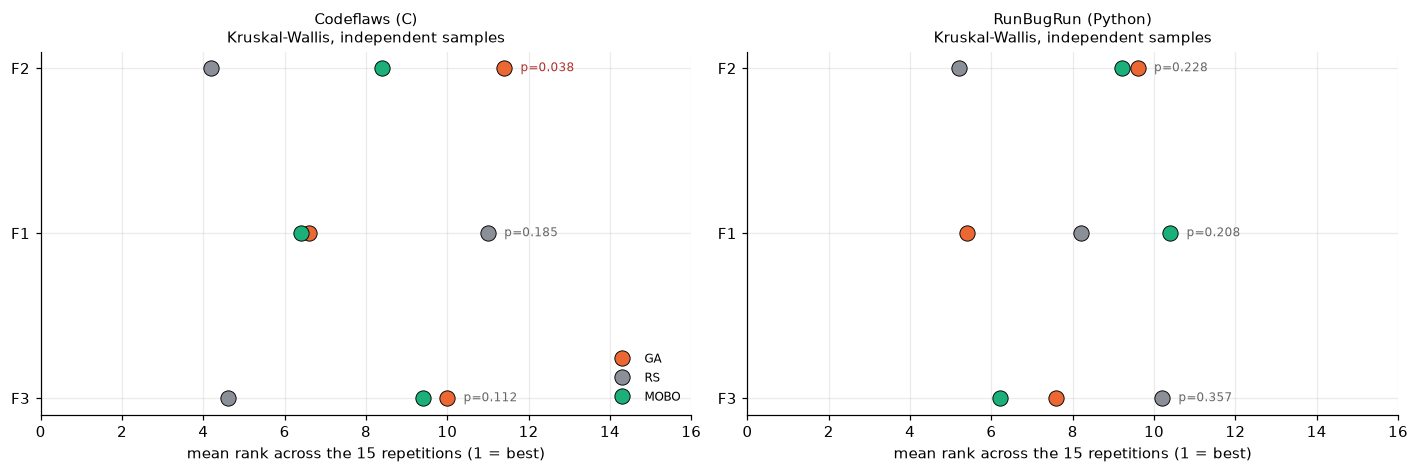

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
rowsK = [(b, key, lab) for b in BENCH
         for key, lab in (("mean_correctness", "F2"), ("mean_cl", "F1"), ("mean_energy", "F3"))]
for ax, b in zip(axes, BENCH):
    labs = [lab for (bb, key, lab) in rowsK if bb == b]
    ys = np.arange(len(labs))[::-1]
    for j, (bb, key, lab) in enumerate([r for r in rowsK if r[0] == b]):
        H, pv, mr, ns = KW[(b, key)]
        for a, r in zip(ORDER, mr):
            ax.plot([r], [ys[j]], "o", ms=10, color=PALETTE[a],
                    markeredgecolor="black", markeredgewidth=0.6,
                    label=a if j == 0 else None)
        ax.text(max(mr) + 0.4, ys[j], f"p={pv:.3f}", fontsize=8, va="center",
                color="#b03030" if pv < 0.05 else "#666")
    ax.set_yticks(ys); ax.set_yticklabels(labs)
    ax.set_xlabel("mean rank across the 15 repetitions (1 = best)")
    ax.set_title(f"{b}\nKruskal-Wallis, independent samples", fontsize=10)
    ax.grid(axis="x", alpha=0.25); ax.set_xlim(0, 16)
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout(); savefig(fig, "omnibus_kruskal"); plt.show()

## §12k · Front geometry

Pairwise projections show where retained policies lie and where the pooled
non-dominated set draws its members from. Dominance in a two-dimensional
projection does not establish dominance in the full three-objective space;
full-dimensional indicators and comparisons are needed for that claim.

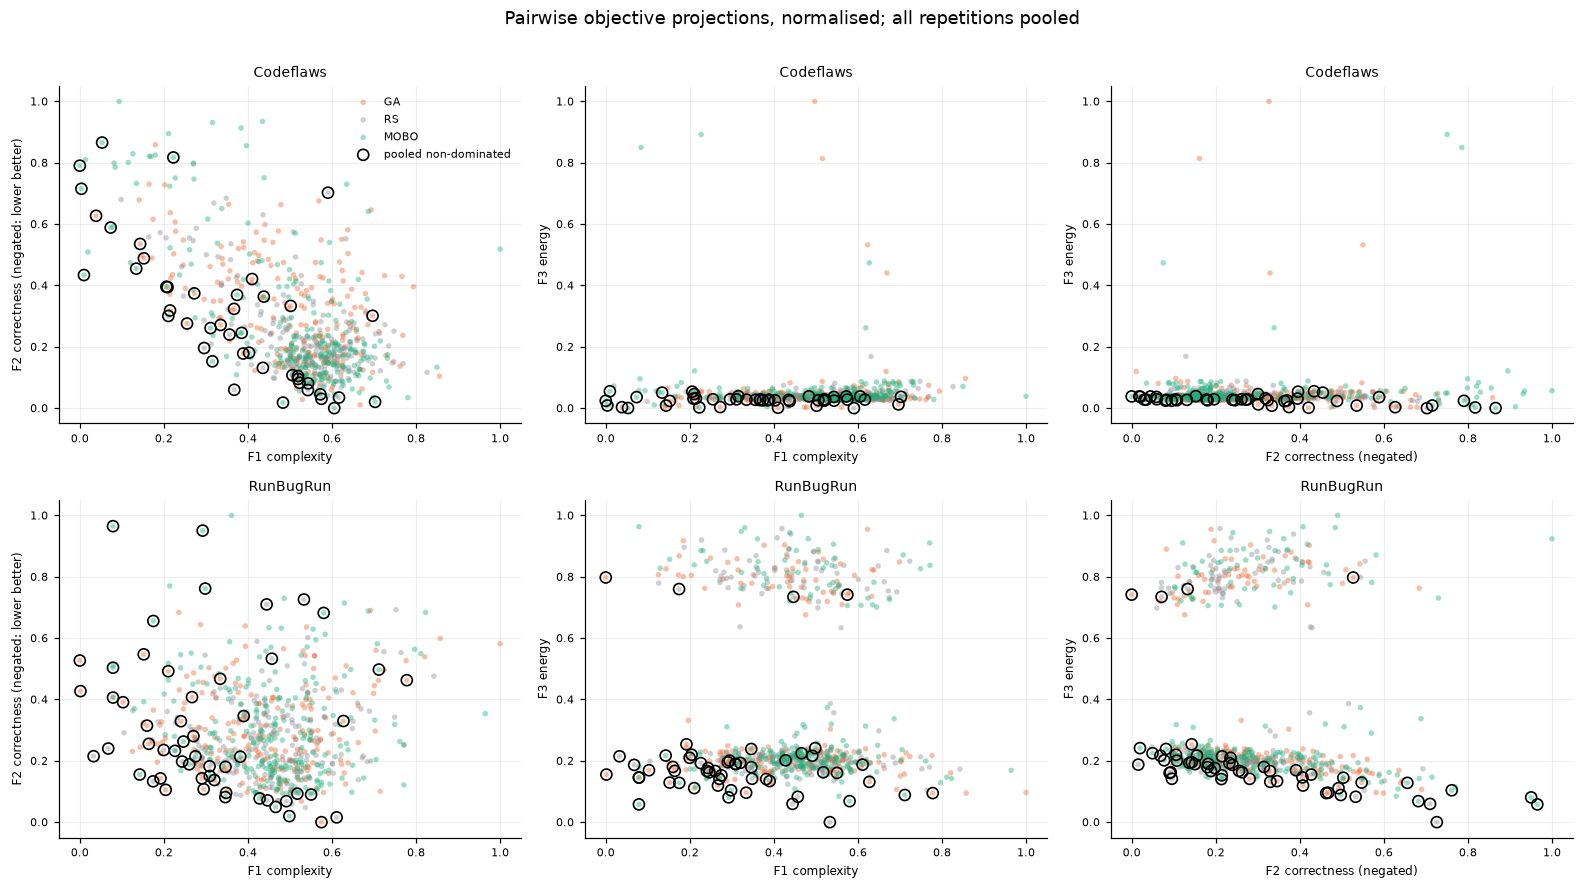

In [59]:
PAIRS = [(0, 1, "F1 complexity", "F2 correctness (negated: lower better)"),
         (0, 2, "F1 complexity", "F3 energy"),
         (1, 2, "F2 correctness (negated)", "F3 energy")]
fig, axes = plt.subplots(2, 3, figsize=(14.5, 8))
for row, b in enumerate(BENCH):
    U = sets[(b, "union", None)]
    for col, (i0, i1, xl, yl) in enumerate(PAIRS):
        ax = axes[row, col]
        for a in ORDER:
            P = np.vstack([sets[(b, a, i)] for i in RP(b, a)])
            ax.scatter(P[:, i0], P[:, i1], s=13, alpha=0.42, color=PALETTE[a],
                       label=a if col == 0 else None, edgecolors="none")
        ax.scatter(U[:, i0], U[:, i1], s=52, facecolors="none", edgecolors="black",
                   linewidths=1.1, label="pooled non-dominated" if col == 0 else None)
        ax.set_xlabel(xl, fontsize=8); ax.set_ylabel(yl, fontsize=8)
        ax.set_title(f"{b.split()[0]}", fontsize=9); ax.tick_params(labelsize=7); ax.grid(alpha=0.2)
        if row == 0 and col == 0: ax.legend(fontsize=7.5)
fig.suptitle("Pairwise objective projections, normalised; all repetitions pooled", y=1.005)
fig.tight_layout(); savefig(fig, "front_projections"); plt.show()

In [60]:
# Contribution of each arm to the pooled non-dominated set, and its distance to it.
print("  contribution to the pooled non-dominated front, and distance to it\n")
print(f"  {'benchmark':22s}{'arm':6s}{'contributed':>12s}{'share':>8s}{'mean IGD+':>11s}{'sd':>8s}")
CONTR = {}
for b in BENCH:
    U = sets[(b, "union", None)]
    tot = 0
    counts = {}
    for a in ORDER:
        P = np.vstack([sets[(b, a, i)] for i in RP(b, a)])
        c = sum(1 for u in U if np.any(np.all(np.isclose(P, u, atol=1e-12, rtol=0), axis=1)))
        counts[a] = c; tot += c
    for a in ORDER:
        ig = [igd_plus(sets[(b, a, i)], U) for i in RP(b, a)]
        CONTR[(b, a)] = (counts[a], counts[a] / max(tot, 1), st.mean(ig), st.stdev(ig))
        print(f"  {b:22s}{a:6s}{counts[a]:12d}{100*counts[a]/max(tot,1):7.1f}%"
              f"{st.mean(ig):11.4f}{st.stdev(ig):8.4f}")
    print(f"  {'':22s}{'union':6s}{len(U):12d}\n")

  contribution to the pooled non-dominated front, and distance to it

  benchmark             arm    contributed   share  mean IGD+      sd
  Codeflaws (C)         GA              16   35.6%     0.0527  0.0093
  Codeflaws (C)         RS               8   17.8%     0.0617  0.0123
  Codeflaws (C)         MOBO            21   46.7%     0.0451  0.0122
                        union           45

  RunBugRun (Python)    GA              22   40.0%     0.0572  0.0113


  RunBugRun (Python)    RS              16   29.1%     0.0674  0.0127
  RunBugRun (Python)    MOBO            17   30.9%     0.0700  0.0144
                        union           55



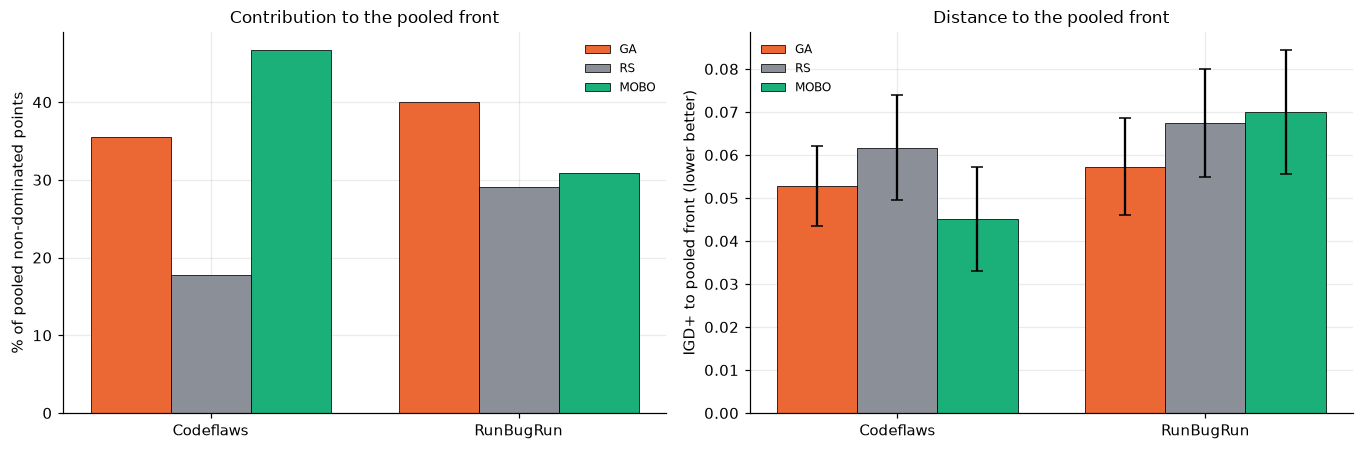

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
w = 0.26
for j, a in enumerate(ORDER):
    ax.bar(np.arange(len(BENCH)) + (j - 1) * w, [100 * CONTR[(b, a)][1] for b in BENCH],
           width=w, color=PALETTE[a], edgecolor="black", linewidth=0.5, label=a)
ax.set_xticks(range(len(BENCH))); ax.set_xticklabels([b.split()[0] for b in BENCH])
ax.set_ylabel("% of pooled non-dominated points"); ax.set_title("Contribution to the pooled front")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.25)
ax = axes[1]
for j, a in enumerate(ORDER):
    m = [CONTR[(b, a)][2] for b in BENCH]; e = [CONTR[(b, a)][3] for b in BENCH]
    ax.bar(np.arange(len(BENCH)) + (j - 1) * w, m, yerr=e, capsize=4,
           width=w, color=PALETTE[a], edgecolor="black", linewidth=0.5, label=a)
ax.set_xticks(range(len(BENCH))); ax.set_xticklabels([b.split()[0] for b in BENCH])
ax.set_ylabel("IGD+ to pooled front (lower better)"); ax.set_title("Distance to the pooled front")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.25)
fig.tight_layout(); savefig(fig, "front_contribution"); plt.show()

### §12k-i · Objective structure

Spearman correlations among held-out objectives describe association within the
retained policies. Strong correlation does not prove objective redundancy or
remove an objective from the optimisation problem. In particular, F2 and
feasibility share a mechanical relationship and do not provide independent
confirmations of benefit.

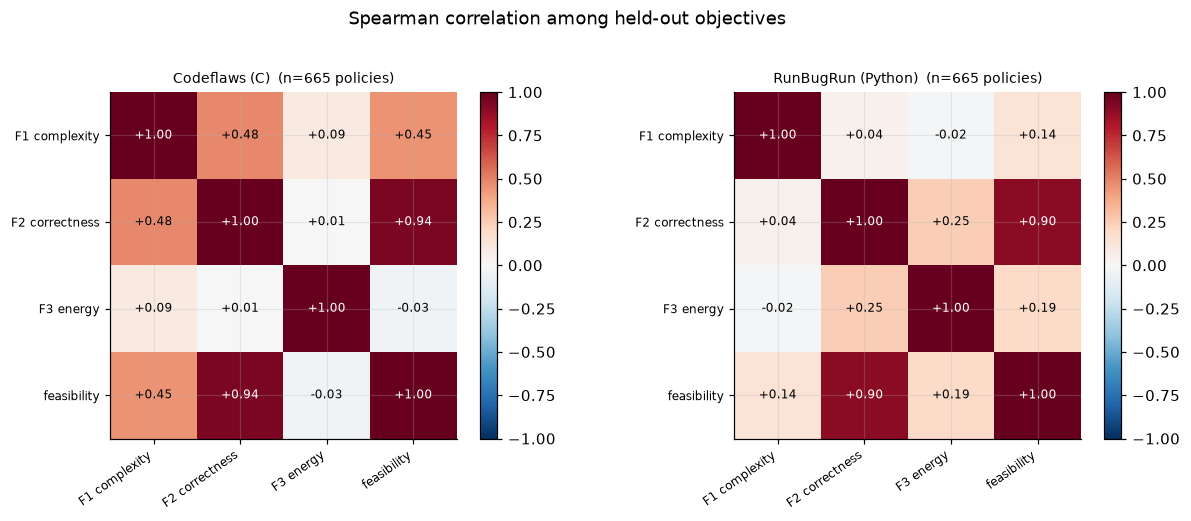


  correlation between F2 and feasibility (the mechanically linked pair):
    Codeflaws (C)          rho = +0.939  (n=665)
    RunBugRun (Python)     rho = +0.900  (n=665)


In [62]:
OBJ3 = [("mean_cl", "F1 complexity"), ("mean_correctness", "F2 correctness"),
        ("mean_energy", "F3 energy"), ("n_feasible", "feasibility")]
fig, axes = plt.subplots(1, len(BENCH), figsize=(11.5, 4.6))
for ax, b in zip(np.atleast_1d(axes), BENCH):
    recs = [x for a in ORDER for i in RP(b, a) for x in policies[b][a][i]]
    M = np.array([[r[k] for k, _ in OBJ3] for r in recs
                  if all(isinstance(r.get(k), (int, float)) and math.isfinite(r[k]) for k, _ in OBJ3)], float)
    C = np.zeros((len(OBJ3), len(OBJ3)))
    for i1 in range(len(OBJ3)):
        for i2 in range(len(OBJ3)):
            C[i1, i2] = spearmanr(M[:, i1], M[:, i2]).correlation
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(OBJ3))); ax.set_xticklabels([l for _, l in OBJ3], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(OBJ3))); ax.set_yticklabels([l for _, l in OBJ3], fontsize=8)
    for i1 in range(len(OBJ3)):
        for i2 in range(len(OBJ3)):
            ax.text(i2, i1, f"{C[i1,i2]:+.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(C[i1, i2]) > 0.55 else "black")
    ax.set_title(f"{b}  (n={len(M)} policies)", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.045)
fig.suptitle("Spearman correlation among held-out objectives", y=1.02)
fig.tight_layout(); savefig(fig, "objective_correlations"); plt.show()

print("\n  correlation between F2 and feasibility (the mechanically linked pair):")
for b in BENCH:
    recs = [x for a in ORDER for i in RP(b, a) for x in policies[b][a][i]]
    f2 = [r["mean_correctness"] for r in recs]; nf = [float(r["n_feasible"]) for r in recs]
    print(f"    {b:22s} rho = {spearmanr(f2, nf).correlation:+.3f}  (n={len(f2)})")

## §12l · Joint structure of the policy space

Parallel coordinates show retained policies across all eleven parameters. PCA
projects their standardised values onto two components. These displays describe
joint structure but cannot establish full-space separability, inseparability,
isotropy or convergence to the same optimum.

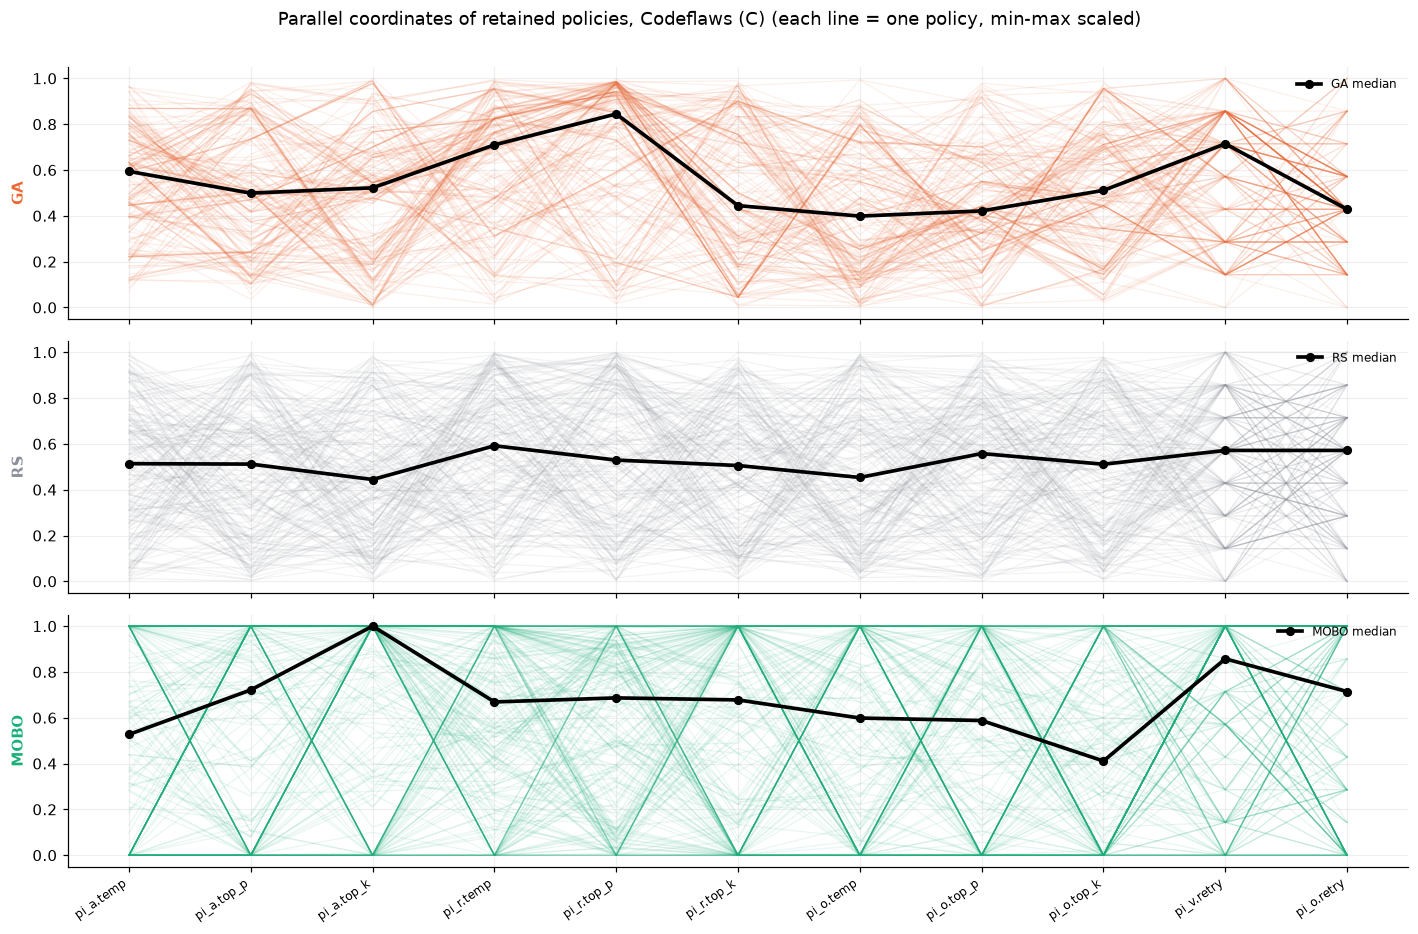

In [63]:
b0 = list(BENCH)[0]
dims = list(vec(policies[b0]["GA"][0][0]["policy"]))
fig, axes = plt.subplots(len(ORDER), 1, figsize=(13, 8.4), sharex=True)
allv = {d: [] for d in dims}
for a in ORDER:
    for i in RP(b0, a):
        for x in policies[b0][a][i]:
            v = vec(x["policy"])
            for d in dims: allv[d].append(v[d])
lo = {d: min(allv[d]) for d in dims}; hi = {d: max(allv[d]) for d in dims}
for ax, a in zip(axes, ORDER):
    for i in RP(b0, a):
        for x in policies[b0][a][i]:
            v = vec(x["policy"])
            y = [(v[d] - lo[d]) / (hi[d] - lo[d] if hi[d] > lo[d] else 1) for d in dims]
            ax.plot(range(len(dims)), y, color=PALETTE[a], alpha=0.10, lw=0.8)
    med = [np.median([(vec(x["policy"])[d] - lo[d]) / (hi[d] - lo[d] if hi[d] > lo[d] else 1)
                      for i in RP(b0, a) for x in policies[b0][a][i]]) for d in dims]
    ax.plot(range(len(dims)), med, color="black", lw=2.4, marker="o", ms=5, label=f"{a} median")
    ax.set_ylabel(a, color=PALETTE[a], fontweight="bold")
    ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.2)
axes[-1].set_xticks(range(len(dims)))
axes[-1].set_xticklabels(dims, rotation=35, ha="right", fontsize=8)
fig.suptitle(f"Parallel coordinates of retained policies, {b0} (each line = one policy, min-max scaled)", y=1.005)
fig.tight_layout(); savefig(fig, "parallel_coordinates"); plt.show()

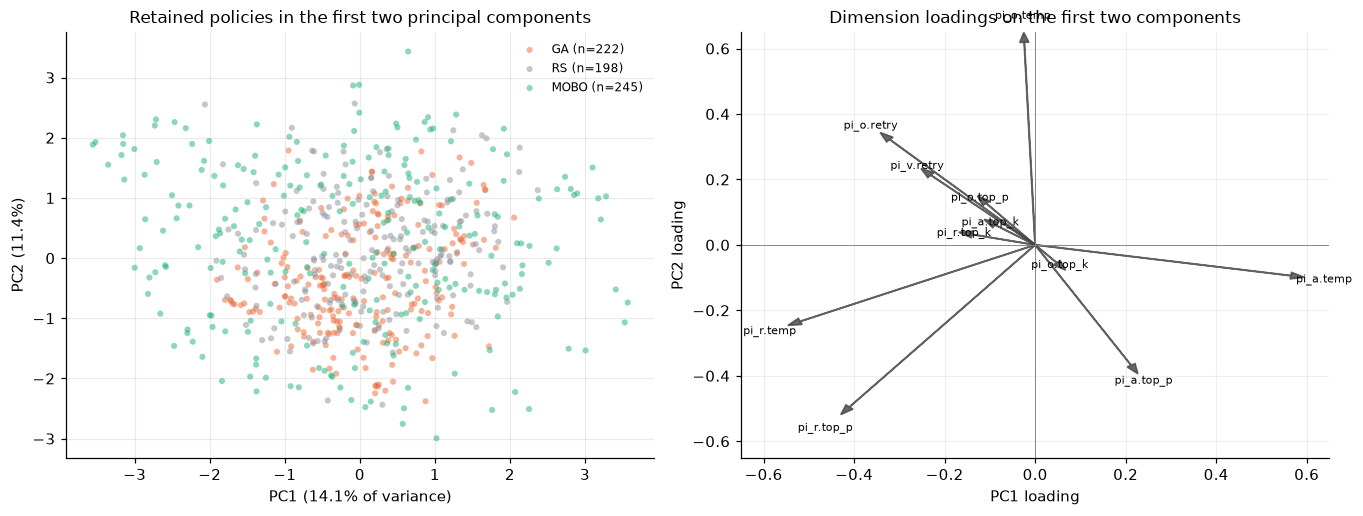

  first two components carry 25.5% of the variance in 11 dimensions.
  Low explained variance in two components is consistent with variance being
  spread across many directions, but it does not by itself establish isotropy,
  and overlap in a 2-D projection does not establish that the arms are
  inseparable in the full space. Both would need a test in 11 dimensions.


In [64]:
# Separability of the arms in the full 11-dimensional policy space.
X, lab = [], []
for a in ORDER:
    for i in RP(b0, a):
        for x in policies[b0][a][i]:
            v = vec(x["policy"]); X.append([v[d] for d in dims]); lab.append(a)
X = np.array(X, float); lab = np.array(lab)
Xz = (X - X.mean(0)) / np.where(X.std(0) == 0, 1, X.std(0))
U_, S_, Vt = np.linalg.svd(Xz - Xz.mean(0), full_matrices=False)
PC = (Xz - Xz.mean(0)) @ Vt[:2].T
evr = (S_ ** 2 / (S_ ** 2).sum())[:2]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
for a in ORDER:
    m = lab == a
    ax.scatter(PC[m, 0], PC[m, 1], s=16, alpha=0.5, color=PALETTE[a], label=f"{a} (n={m.sum()})",
               edgecolors="none")
ax.set_xlabel(f"PC1 ({100*evr[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100*evr[1]:.1f}%)")
ax.set_title("Retained policies in the first two principal components")
ax.legend(fontsize=8); ax.grid(alpha=0.25)

ax = axes[1]
load = Vt[:2].T
for j, d in enumerate(dims):
    ax.arrow(0, 0, load[j, 0], load[j, 1], head_width=0.02, color="#444", lw=1.1, alpha=0.8)
    ax.text(load[j, 0] * 1.13, load[j, 1] * 1.13, d, fontsize=7.5, ha="center", va="center")
ax.set_xlim(-0.65, 0.65); ax.set_ylim(-0.65, 0.65)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("PC1 loading"); ax.set_ylabel("PC2 loading")
ax.set_title("Dimension loadings on the first two components"); ax.grid(alpha=0.2)
fig.tight_layout(); savefig(fig, "policy_space_pca"); plt.show()

print(f"  first two components carry {100*evr.sum():.1f}% of the variance in 11 dimensions.")
print("  Low explained variance in two components is consistent with variance being")
print("  spread across many directions, but it does not by itself establish isotropy,")
print("  and overlap in a 2-D projection does not establish that the arms are")
print("  inseparable in the full space. Both would need a test in 11 dimensions.")

## §13 · Findings

Composed from the variables computed above rather than written by hand, so the
text cannot diverge from the numbers under re-execution on different data.

Codeflaws (C):
  F2 correctness   baseline 0.4580 +- 0.0243 over 5 repetitions
    - GA    per-repetition mean 0.4522 +- 0.0231; gain over default -0.0058 (-0.24 sd), does not exceed one baseline sd.
    - RS    per-repetition mean 0.4797 +- 0.0041; gain over default +0.0217 (+0.89 sd), does not exceed one baseline sd.
    - MOBO  per-repetition mean 0.4615 +- 0.0223; gain over default +0.0035 (+0.14 sd), does not exceed one baseline sd.
    - RS - GA: +0.0275; per-repetition MWU p=0.00794 (n=5 vs 5); per-policy p=3.47e-07; Cliff d=+1.000 (large).
    - MOBO - GA: +0.0093; per-repetition MWU p=0.421 (n=5 vs 5); per-policy p=0.000747; Cliff d=+0.360 (medium).
    - MOBO - RS: -0.0182; per-repetition MWU p=0.222 (n=5 vs 5); per-policy p=0.316; Cliff d=-0.520 (large).
    - best single policy: GA 0.5628, RS 0.5555, MOBO 0.5669 (best=MOBO); arm leading on the mean = RS  [DIFFERENT arm leads on mean vs best member]
    - between-run sd: GA 0.0231, RS 0.0041, MOBO 0.0223; most variable = GA 

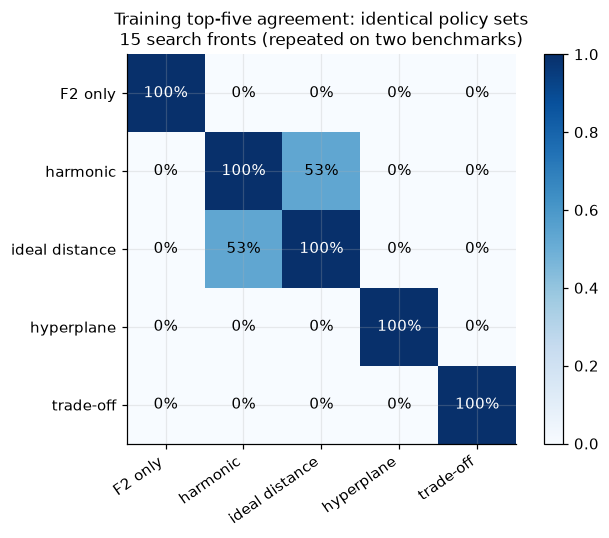

  wrote analysis/data/three_arm_results.json
  wrote docs/reports/replicated_three_arm_comparison.md
  C unseen-task sensitivity:
    GA F1: margin +0.2326, Holm(4) p=0.44444
    GA F2: margin +0.0384, Holm(4) p=0.12698
    GA F3: margin +3.6203, Holm(4) p=0.44444
    GA feasible: margin +5.8925, Holm(4) p=0.28108
    RS F1: margin +0.2233, Holm(4) p=1.00000
    RS F2: margin +0.0395, Holm(4) p=0.16667
    RS F3: margin +3.1685, Holm(4) p=1.00000
    RS feasible: margin +6.5376, Holm(4) p=0.12698
    MOBO F1: margin +0.2527, Holm(4) p=0.61905
    MOBO F2: margin +0.0537, Holm(4) p=0.03175
    MOBO F3: margin -1.3704, Holm(4) p=0.84127
    MOBO feasible: margin +8.0000, Holm(4) p=0.03175


In [65]:
lines = []
OBJ = [("F2 correctness", "mean_correctness", "hi"),
       ("F1 complexity",  "mean_cl",          "lo"),
       ("F3 energy",      "mean_energy",      "lo")]
for b in BENCH:
    lines.append(f"{b}:")
    for lab, key, better in OBJ:
        bs = baseline[b]["summary"][key]
        nrep = baseline[b]["summary"]["n_reps"]
        lines.append(f"  {lab}   baseline {bs['mean']:.4f} +- {bs['std']:.4f} over {nrep} repetitions")
        for a in ORDER:
            v = per_rep(b, a, key)
            g = (st.mean(v) - bs["mean"]) if better == "hi" else (bs["mean"] - st.mean(v))
            verdict = ("exceeds" if g > bs["std"] else "does not exceed") + " one baseline sd"
            lines.append(f"    - {a:5s} per-repetition mean {st.mean(v):.4f} +- {st.stdev(v):.4f}; "
                         f"gain over default {g:+.4f} ({g / bs['std']:+.2f} sd), {verdict}.")
        for x, y in combinations(ORDER, 2):
            r = repl[(b, key, x, y)]
            nx, ny = len(per_rep(b, x, key)), len(per_rep(b, y, key))
            lines.append(f"    - {y} - {x}: {r['diff']:+.4f}; per-repetition MWU p={r['p_rep']:.3g} "
                         f"(n={nx} vs {ny}); per-policy p={r['p_pol']:.3g}; "
                         f"Cliff d={r['delta']:+.3f} ({dmag(r['delta'])}).")
        pick = max if better == "hi" else min
        best = {a: pick(flat(b, a, key)) for a in ORDER}
        bl = pick(ORDER, key=lambda a: best[a])
        ml = pick(ORDER, key=lambda a: st.mean(per_rep(b, a, key)))
        lines.append("    - best single policy: "
                     + ", ".join(f"{a} {best[a]:.4f}" for a in ORDER)
                     + f" (best={bl}); arm leading on the mean = {ml}"
                     + ("  [same arm]" if bl == ml else "  [DIFFERENT arm leads on mean vs best member]"))
        sds = {a: st.stdev(per_rep(b, a, key)) for a in ORDER}
        mv = max(sds, key=lambda a: sds[a])
        lines.append("    - between-run sd: "
                     + ", ".join(f"{a} {sds[a]:.4f}" for a in ORDER)
                     + f"; most variable = {mv} ({sds[mv] / min(sds.values()):.2f}x the least variable).")
        lines.append("")
    lines.append("")
print("\n".join(lines))

summary_out = {
    "generated_by": "scripts/generators/build_three_arm_notebook.py",
    "benchmarks": {},
}
for b in BENCH:
    r = repl[(b, "mean_correctness", "GA", "RS")]     # explicit: this export is the GA-RS pair
    summary_out["benchmarks"][b] = {
        "heldout_digest": BENCH[b]["digest"],
        "energy_backend": "rapl_sysfs",
        "n_reps_per_arm": {a: len(RP(b, a)) for a in ORDER},
        "baseline": baseline[b]["summary"]["mean_correctness"],
        "per_rep_mean_f2": {a: per_rep(b, a, "mean_correctness") for a in ORDER},
        "p_per_rep_mwu": r["p_rep"], "p_per_policy": r["p_pol"],
        "cliffs_delta_rs_vs_ga": r["delta"],
        "hypervolume_ref_margin": REF_MARGIN,
        "hypervolume_per_rep": {a: hv_vals[(b, a)] for a in ORDER},
    }
(DATA / "three_arm_summary.json").write_text(json.dumps(summary_out, indent=2))
print(f"\n  wrote {(DATA / 'three_arm_summary.json').relative_to(REPO)}")

# the three-arm comparison report and its full-precision data are generated from this executed state.
# Keep the report template in the exporter; do not hand-edit generated tables.
import sys
sys.path.insert(0, str(REPO / "scripts" / "generators"))
from export_report import export_report
export_report(globals())

## §14 · Threats to validity

- **Five independent search repetitions per arm.** Low power and coarse rank-test
  resolution; non-significance is not equivalence. Baseline repetitions share
  tasks and host and measure execution variation, not independent datasets.
- **Task overlap on C.** Fifty training records cover 49 Codeforces tasks; 100
  held-out records cover 98 tasks. Six tasks overlap, affecting seven held-out
  records. The split is record-disjoint, not fully task-disjoint. Grouping the
  bootstrap correctly does not repair this leakage. Python's 100 records cover
  68 tasks; its excluded 50-record Python reference split covers 44 tasks, with
  no task overlap. All optimised policies were trained on C.
- **Conditional estimands.** F1 and F3 average feasible attempts only; changing
  which tasks are feasible changes their composition. They do not measure total
  pipeline energy, nor savings at fixed correctness or search-cost repayment.
- **Measurement and host.** Search and held-out hosts differ; training energy is
  used in selection and anytime analysis and may transfer poorly. Same-host real
  RAPL measurements improve comparability but do not remove drift or stochastic
  repair variation. Each non-baseline held-out policy was evaluated once.
- **Selection and multiplicity.** Correctness-only was favoured after inspecting
  held-out results. The four-outcome correction within each cell is narrower
  than a global family. A top-five mean is a shortlist estimand, not an evaluated
  deterministic single-policy deployment rule. Oracle selection uses outcomes.
- **Front conditioning and size.** Pooled-policy summaries weight repetitions by
  front size. Cardinality control is a sensitivity analysis. Correlations among
  retained policies are conditional associations, not guaranteed lower bounds.
- **Anytime archive limitations.** GA omits rejected offspring. Self-final HV
  ratios do not establish a common absolute target, and retrospective plateaus
  are not validated stopping rules.
- **External validity.** One model, two benchmarks, one language pair, one
  held-out sample per benchmark, and model defaults rather than expert tuning.